In [1]:

import sys
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
import torch

from sklearn.model_selection import train_test_split

PROJECT_DIR = Path(r"D:\Ai_Ml_intren\week_4")
DATASET_PATH = PROJECT_DIR / "IMDB_Dataset.csv"

OUTPUT_DIR = PROJECT_DIR / "outputs"
SPLIT_DIR = OUTPUT_DIR / "splits"
REPORT_DIR = OUTPUT_DIR / "reports"

for directory in [OUTPUT_DIR, SPLIT_DIR, REPORT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_SEED = 42

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

if not DATASET_PATH.is_file():
    raise FileNotFoundError(
        f"Dataset not found: {DATASET_PATH}"
    )

print("=" * 55)
print("WEEK 4 - PHASE 1: PROJECT SETUP")
print("=" * 55)

print("\nPYTHON ENVIRONMENT")
print("Python Version:", sys.version.split()[0])
print("Python Path:", sys.executable)

print("\nLIBRARY VERSIONS")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("PyTorch:", torch.__version__)

print("\nDEVICE INFORMATION")
print("Selected Device:", DEVICE)
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))

print("\nPROJECT DIRECTORY:", PROJECT_DIR)
print("DATASET EXISTS:", DATASET_PATH.exists())
print("OUTPUT DIRECTORY EXISTS:", OUTPUT_DIR.exists())
print("SPLIT DIRECTORY EXISTS:", SPLIT_DIR.exists())
print("REPORT DIRECTORY EXISTS:", REPORT_DIR.exists())

print("\nRANDOM SEED:", RANDOM_SEED)

print("\nCELL 1 COMPLETED SUCCESSFULLY!")


WEEK 4 - PHASE 1: PROJECT SETUP

PYTHON ENVIRONMENT
Python Version: 3.12.10
Python Path: c:\Program Files\Python312\python.exe

LIBRARY VERSIONS
Pandas: 3.0.6
NumPy: 2.5.3
Scikit-learn: 1.9.1
PyTorch: 2.12.1+cu126

DEVICE INFORMATION
Selected Device: cuda
CUDA Available: True
GPU Name: NVIDIA GeForce RTX 3050 6GB Laptop GPU

PROJECT DIRECTORY: D:\Ai_Ml_intren\week_4
DATASET EXISTS: True
OUTPUT DIRECTORY EXISTS: True
SPLIT DIRECTORY EXISTS: True
REPORT DIRECTORY EXISTS: True

RANDOM SEED: 42

CELL 1 COMPLETED SUCCESSFULLY!


In [2]:

df_raw = pd.read_csv(
    DATASET_PATH,
    low_memory=False
)

df_raw.columns = (
    df_raw.columns.astype(str)
    .str.strip()
    .str.lower()
)

required_columns = {"review", "sentiment"}

missing_columns = required_columns.difference(
    df_raw.columns
)

if missing_columns:
    raise ValueError(
        f"Required columns missing: {missing_columns}"
    )

df_raw = df_raw[["review", "sentiment"]].copy()

print("=" * 55)
print("PHASE 1 - CELL 2: DATASET LOADING")
print("=" * 55)

print("\nDataset Name:", DATASET_PATH.name)
print("Dataset Shape:", df_raw.shape)
print("Total Records:", len(df_raw))
print("Total Columns:", len(df_raw.columns))

print("\nCOLUMN INFORMATION")
print(df_raw.dtypes)

print("\nFIRST 5 RECORDS")
display(df_raw.head())

print("\nDATASET FILE SIZE:",
      round(DATASET_PATH.stat().st_size / (1024 * 1024), 2),
      "MB")

print("\nCELL 2 COMPLETED SUCCESSFULLY!")


PHASE 1 - CELL 2: DATASET LOADING

Dataset Name: IMDB_Dataset.csv
Dataset Shape: (50000, 2)
Total Records: 50000
Total Columns: 2

COLUMN INFORMATION
review       str
sentiment    str
dtype: object

FIRST 5 RECORDS


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive



DATASET FILE SIZE: 63.14 MB

CELL 2 COMPLETED SUCCESSFULLY!


In [3]:

review_keys = (
    df_raw["review"]
    .astype("string")
    .str.strip()
)

sentiment_keys = (
    df_raw["sentiment"]
    .astype("string")
    .str.strip()
    .str.lower()
)

audit_df = pd.DataFrame({
    "review_key": review_keys,
    "sentiment_key": sentiment_keys
})

valid_mask = (
    audit_df["review_key"].notna()
    & audit_df["review_key"].fillna("").ne("")
    & audit_df["sentiment_key"].notna()
    & audit_df["sentiment_key"].fillna("").ne("")
)

valid_audit = audit_df.loc[valid_mask].copy()

repeated_reviews = valid_audit[
    valid_audit.duplicated(
        subset=["review_key"],
        keep=False
    )
]

conflicting_labels = (
    valid_audit.groupby("review_key")["sentiment_key"]
    .nunique()
)

print("=" * 55)
print("PHASE 1 - CELL 3: DATA QUALITY ANALYSIS")
print("=" * 55)

print("\nMISSING VALUES")
print(df_raw.isnull().sum())

print("\nEMPTY REVIEWS:",
      review_keys.fillna("").eq("").sum())

print("EMPTY SENTIMENT LABELS:",
      sentiment_keys.fillna("").eq("").sum())

print("\nEXACT DUPLICATE ROWS:",
      df_raw.duplicated().sum())

print("REPEATED REVIEW GROUPS:",
      repeated_reviews["review_key"].nunique())

print("EXTRA REPEATED REVIEW ROWS:",
      valid_audit.duplicated(subset=["review_key"]).sum())

print("CONFLICTING LABEL GROUPS:",
      conflicting_labels.gt(1).sum())

print("\nUNIQUE SENTIMENT LABELS")
print(sorted(sentiment_keys.dropna().unique().tolist()))

print("\nSENTIMENT DISTRIBUTION")
print(sentiment_keys.value_counts())

print("\nCELL 3 COMPLETED SUCCESSFULLY!")


PHASE 1 - CELL 3: DATA QUALITY ANALYSIS

MISSING VALUES
review       0
sentiment    0
dtype: int64

EMPTY REVIEWS: 0
EMPTY SENTIMENT LABELS: 0

EXACT DUPLICATE ROWS: 418
REPEATED REVIEW GROUPS: 406
EXTRA REPEATED REVIEW ROWS: 418
CONFLICTING LABEL GROUPS: 0

UNIQUE SENTIMENT LABELS
['negative', 'positive']

SENTIMENT DISTRIBUTION
sentiment
positive    25000
negative    25000
Name: count, dtype: int64[pyarrow]

CELL 3 COMPLETED SUCCESSFULLY!


In [4]:

df_clean = df_raw.copy()

original_count = len(df_clean)

df_clean["review"] = (
    df_clean["review"]
    .astype("string")
    .str.strip()
)

df_clean["sentiment"] = (
    df_clean["sentiment"]
    .astype("string")
    .str.strip()
    .str.lower()
)

df_clean = df_clean.dropna(
    subset=["review", "sentiment"]
)

df_clean = df_clean.loc[
    df_clean["review"].ne("")
    & df_clean["sentiment"].ne("")
].copy()

valid_count = len(df_clean)

allowed_labels = {"positive", "negative"}

unexpected_labels = (
    set(df_clean["sentiment"].unique())
    - allowed_labels
)

if unexpected_labels:
    raise ValueError(
        f"Unexpected sentiment labels: {unexpected_labels}"
    )

label_counts_per_review = (
    df_clean.groupby("review")["sentiment"]
    .nunique()
)

conflicting_reviews = label_counts_per_review[
    label_counts_per_review > 1
]

if not conflicting_reviews.empty:
    raise ValueError(
        "Conflicting sentiment labels found. "
        "Resolve them before removing duplicates."
    )

df_clean = (
    df_clean.drop_duplicates(
        subset=["review"],
        keep="first"
    )
    .reset_index(drop=True)
)

removed_invalid = original_count - valid_count
removed_duplicates = valid_count - len(df_clean)

print("=" * 55)
print("PHASE 1 - CELL 4: DATA CLEANING")
print("=" * 55)

print("\nOriginal Records:", original_count)
print("Invalid Records Removed:", removed_invalid)
print("Duplicate Reviews Removed:", removed_duplicates)
print("Final Records:", len(df_clean))

print("\nREMAINING MISSING VALUES")
print(df_clean.isnull().sum())

print("\nREMAINING DUPLICATES:",
      df_clean["review"].duplicated().sum())

print("\nFINAL SENTIMENT DISTRIBUTION")
print(df_clean["sentiment"].value_counts())

assert df_clean["review"].is_unique
assert df_clean.isnull().sum().sum() == 0

print("\nCELL 4 COMPLETED SUCCESSFULLY!")


PHASE 1 - CELL 4: DATA CLEANING

Original Records: 50000
Invalid Records Removed: 0
Duplicate Reviews Removed: 418
Final Records: 49582

REMAINING MISSING VALUES
review       0
sentiment    0
dtype: int64

REMAINING DUPLICATES: 0

FINAL SENTIMENT DISTRIBUTION
sentiment
positive    24884
negative    24698
Name: count, dtype: int64[pyarrow]

CELL 4 COMPLETED SUCCESSFULLY!


In [5]:

train_df, temporary_df = train_test_split(
    df_clean,
    test_size=0.20,
    random_state=RANDOM_SEED,
    stratify=df_clean["sentiment"]
)

validation_df, test_df = train_test_split(
    temporary_df,
    test_size=0.50,
    random_state=RANDOM_SEED,
    stratify=temporary_df["sentiment"]
)

train_df = train_df.reset_index(drop=True)
validation_df = validation_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

def show_split_summary(name, data):
    counts = (
        data["sentiment"]
        .value_counts()
        .reindex(["negative", "positive"], fill_value=0)
    )

    percentages = (
        data["sentiment"]
        .value_counts(normalize=True)
        .reindex(["negative", "positive"], fill_value=0)
        .mul(100)
        .round(2)
    )

    print(f"\n{name}")
    print("Total Records:", len(data))
    print(
        pd.DataFrame({
            "Count": counts,
            "Percentage": percentages
        })
    )

print("=" * 55)
print("PHASE 1 - CELL 5: DATASET SPLITTING")
print("=" * 55)

show_split_summary("TRAINING DATA", train_df)
show_split_summary("VALIDATION DATA", validation_df)
show_split_summary("TESTING DATA", test_df)

print("\nTOTAL SPLIT RECORDS:",
      len(train_df) + len(validation_df) + len(test_df))

assert len(train_df) + len(validation_df) + len(test_df) == len(df_clean)

print("\nCELL 5 COMPLETED SUCCESSFULLY!")


PHASE 1 - CELL 5: DATASET SPLITTING

TRAINING DATA
Total Records: 39665
           Count  Percentage
sentiment                   
negative   19758       49.81
positive   19907       50.19

VALIDATION DATA
Total Records: 4958
           Count  Percentage
sentiment                   
negative    2470       49.82
positive    2488       50.18

TESTING DATA
Total Records: 4959
           Count  Percentage
sentiment                   
negative    2470       49.81
positive    2489       50.19

TOTAL SPLIT RECORDS: 49582

CELL 5 COMPLETED SUCCESSFULLY!


In [6]:

CLEANED_DATA_PATH = OUTPUT_DIR / "IMDB_Cleaned.csv"

TRAIN_PATH = SPLIT_DIR / "train.csv"
VALIDATION_PATH = SPLIT_DIR / "validation.csv"
TEST_PATH = SPLIT_DIR / "test.csv"

df_clean.to_csv(
    CLEANED_DATA_PATH,
    index=False,
    encoding="utf-8"
)

train_df.to_csv(
    TRAIN_PATH,
    index=False,
    encoding="utf-8"
)

validation_df.to_csv(
    VALIDATION_PATH,
    index=False,
    encoding="utf-8"
)

test_df.to_csv(
    TEST_PATH,
    index=False,
    encoding="utf-8"
)

saved_files = [
    CLEANED_DATA_PATH,
    TRAIN_PATH,
    VALIDATION_PATH,
    TEST_PATH
]

print("=" * 55)
print("PHASE 1 - CELL 6: DATASET SAVING")
print("=" * 55)

for file_path in saved_files:
    file_size = file_path.stat().st_size / (1024 * 1024)

    print("\nFile:", file_path.name)
    print("Location:", file_path)
    print("Size:", round(file_size, 2), "MB")
    print("Exists:", file_path.is_file())

print("\nCELL 6 COMPLETED SUCCESSFULLY!")


PHASE 1 - CELL 6: DATASET SAVING

File: IMDB_Cleaned.csv
Location: D:\Ai_Ml_intren\week_4\outputs\IMDB_Cleaned.csv
Size: 62.72 MB
Exists: True

File: train.csv
Location: D:\Ai_Ml_intren\week_4\outputs\splits\train.csv
Size: 50.21 MB
Exists: True

File: validation.csv
Location: D:\Ai_Ml_intren\week_4\outputs\splits\validation.csv
Size: 6.24 MB
Exists: True

File: test.csv
Location: D:\Ai_Ml_intren\week_4\outputs\splits\test.csv
Size: 6.27 MB
Exists: True

CELL 6 COMPLETED SUCCESSFULLY!


In [7]:

saved_clean = pd.read_csv(CLEANED_DATA_PATH)

saved_train = pd.read_csv(TRAIN_PATH)
saved_validation = pd.read_csv(VALIDATION_PATH)
saved_test = pd.read_csv(TEST_PATH)

saved_splits = {
    "train": saved_train,
    "validation": saved_validation,
    "test": saved_test
}

for split_name, split_data in saved_splits.items():
    assert split_data["review"].notna().all()
    assert split_data["sentiment"].notna().all()
    assert split_data["review"].str.strip().ne("").all()
    assert split_data["review"].is_unique
    assert split_data["sentiment"].isin(
        ["positive", "negative"]
    ).all()

train_texts = set(saved_train["review"])
validation_texts = set(saved_validation["review"])
test_texts = set(saved_test["review"])

train_validation_overlap = len(
    train_texts & validation_texts
)

train_test_overlap = len(
    train_texts & test_texts
)

validation_test_overlap = len(
    validation_texts & test_texts
)

total_split_records = sum(
    len(data) for data in saved_splits.values()
)

assert total_split_records == len(saved_clean)
assert saved_clean["review"].is_unique
assert saved_clean.isnull().sum().sum() == 0

assert train_validation_overlap == 0
assert train_test_overlap == 0
assert validation_test_overlap == 0

def get_label_counts(data):
    return {
        str(label): int(count)
        for label, count in data["sentiment"].value_counts().items()
    }

phase1_report = {
    "project": "IMDB Customer Sentiment Analysis",
    "framework": "PyTorch",
    "random_seed": RANDOM_SEED,
    "total_cleaned_records": int(len(saved_clean)),
    "split_records": {
        name: int(len(data))
        for name, data in saved_splits.items()
    },
    "label_distribution": {
        name: get_label_counts(data)
        for name, data in saved_splits.items()
    },
    "cross_split_overlap": {
        "train_validation": train_validation_overlap,
        "train_test": train_test_overlap,
        "validation_test": validation_test_overlap
    }
}

REPORT_PATH = REPORT_DIR / "phase1_summary.json"

with open(REPORT_PATH, "w", encoding="utf-8") as report_file:
    json.dump(
        phase1_report,
        report_file,
        indent=4,
        ensure_ascii=False
    )

print("=" * 60)
print("WEEK 4 - PHASE 1 FINAL VERIFICATION")
print("=" * 60)

print("\nCLEANED DATASET:", len(saved_clean))

for split_name, split_data in saved_splits.items():
    print(
        f"[PASS] {split_name.upper()} Dataset:",
        len(split_data)
    )

print("\nCROSS-SPLIT DUPLICATE CHECK")
print("Train-Validation:", train_validation_overlap)
print("Train-Test:", train_test_overlap)
print("Validation-Test:", validation_test_overlap)

print("\nMISSING VALUES:",
      saved_clean.isnull().sum().sum())

print("DUPLICATE REVIEWS:",
      saved_clean["review"].duplicated().sum())

print("\nFINAL REPORT:", REPORT_PATH)
print("REPORT EXISTS:", REPORT_PATH.exists())

print("\nALL PHASE 1 VERIFICATION CHECKS PASSED!")
print("PHASE 1 COMPLETED SUCCESSFULLY!")


WEEK 4 - PHASE 1 FINAL VERIFICATION

CLEANED DATASET: 49582
[PASS] TRAIN Dataset: 39665
[PASS] VALIDATION Dataset: 4958
[PASS] TEST Dataset: 4959

CROSS-SPLIT DUPLICATE CHECK
Train-Validation: 0
Train-Test: 0
Validation-Test: 0

MISSING VALUES: 0
DUPLICATE REVIEWS: 0

FINAL REPORT: D:\Ai_Ml_intren\week_4\outputs\reports\phase1_summary.json
REPORT EXISTS: True

ALL PHASE 1 VERIFICATION CHECKS PASSED!
PHASE 1 COMPLETED SUCCESSFULLY!


In [8]:

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(r"D:\Ai_Ml_intren\week_4")
SPLIT_DIR = PROJECT_DIR / "outputs" / "splits"

split_paths = {
    "train": SPLIT_DIR / "train.csv",
    "validation": SPLIT_DIR / "validation.csv",
    "test": SPLIT_DIR / "test.csv"
}

required_columns = {"review", "sentiment"}
split_data = {}

for split_name, file_path in split_paths.items():

    if not file_path.is_file():
        raise FileNotFoundError(
            f"Dataset not found: {file_path}"
        )

    data = pd.read_csv(file_path)

    missing_columns = required_columns - set(data.columns)

    if missing_columns:
        raise ValueError(
            f"Missing columns in {split_name}: {missing_columns}"
        )

    data = data[["review", "sentiment"]].copy()

    data["review"] = data["review"].astype("string")
    data["sentiment"] = (
        data["sentiment"].astype("string").str.strip().str.lower()
    )

    if data.isnull().any().any():
        raise ValueError(f"Missing values found in {split_name}")

    if data["review"].str.strip().eq("").any():
        raise ValueError(f"Empty reviews found in {split_name}")

    if not data["sentiment"].isin(
        {"positive", "negative"}
    ).all():
        raise ValueError(f"Invalid labels found in {split_name}")

    if data["review"].duplicated().any():
        raise ValueError(f"Duplicate reviews found in {split_name}")

    split_data[split_name] = data

train_df = split_data["train"]
validation_df = split_data["validation"]
test_df = split_data["test"]

train_texts = set(train_df["review"])
validation_texts = set(validation_df["review"])
test_texts = set(test_df["review"])

overlaps = {
    "Train-Validation": len(train_texts & validation_texts),
    "Train-Test": len(train_texts & test_texts),
    "Validation-Test": len(validation_texts & test_texts)
}

if any(overlaps.values()):
    raise ValueError(f"Cross-split overlap detected: {overlaps}")

print("=" * 60)
print("PHASE 2 - CELL 1: DATASET VERIFICATION")
print("=" * 60)

for split_name, data in split_data.items():

    print(f"\n{split_name.upper()} DATASET")
    print("Total Reviews:", len(data))
    print("Missing Values:", data.isnull().sum().sum())
    print("Duplicate Reviews:", data["review"].duplicated().sum())

    print("\nSentiment Distribution:")
    print(data["sentiment"].value_counts())

print("\nCROSS-SPLIT VERIFICATION")

for name, count in overlaps.items():
    print(f"{name}: {count}")

print("\nTOTAL REVIEWS:",
      sum(len(data) for data in split_data.values()))

print("\nFIRST 3 TRAINING REVIEWS")
display(train_df.head(3))

assert len(train_df) == 39665
assert len(validation_df) == 4958
assert len(test_df) == 4959
assert sum(len(data) for data in split_data.values()) == 49582

print("\nCELL 1 COMPLETED SUCCESSFULLY!")


PHASE 2 - CELL 1: DATASET VERIFICATION

TRAIN DATASET
Total Reviews: 39665
Missing Values: 0
Duplicate Reviews: 0

Sentiment Distribution:
sentiment
positive    19907
negative    19758
Name: count, dtype: int64[pyarrow]

VALIDATION DATASET
Total Reviews: 4958
Missing Values: 0
Duplicate Reviews: 0

Sentiment Distribution:
sentiment
positive    2488
negative    2470
Name: count, dtype: int64[pyarrow]

TEST DATASET
Total Reviews: 4959
Missing Values: 0
Duplicate Reviews: 0

Sentiment Distribution:
sentiment
positive    2489
negative    2470
Name: count, dtype: int64[pyarrow]

CROSS-SPLIT VERIFICATION
Train-Validation: 0
Train-Test: 0
Validation-Test: 0

TOTAL REVIEWS: 49582

FIRST 3 TRAINING REVIEWS


,review,sentiment
0,I am one of Jehovah's Witnesses and I also wor...,positive
1,Amongst the standard one liner type action fil...,positive
2,Realty television crew are assigned to cover a...,negative



CELL 1 COMPLETED SUCCESSFULLY!


In [9]:

import re
import html

def clean_review(text):
    text = html.unescape(str(text))
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(
        r"https?://\S+|www\.\S+",
        " ",
        text,
        flags=re.IGNORECASE
    )
    text = text.replace("’", "'").replace("‘", "'")
    text = text.lower()
    text = re.sub(r"[^a-z0-9'\s]", " ", text)
    text = re.sub(r"\s+", " ", text)

    return text.strip()


for split_name, data in split_data.items():
    data["cleaned_review"] = data["review"].map(clean_review)


print("=" * 60)
print("PHASE 2 - CELL 2: TEXT NORMALIZATION")
print("=" * 60)

print("\nTRAINING REVIEW - BEFORE")
print(train_df["review"].iloc[0][:300])

print("\nTRAINING REVIEW - AFTER")
print(train_df["cleaned_review"].iloc[0][:300])

for split_name, data in split_data.items():

    empty_reviews = int(
        data["cleaned_review"].eq("").sum()
    )

    remaining_html = int(
        data["cleaned_review"].str.contains(
            r"<[^>]+>",
            regex=True
        ).sum()
    )

    remaining_urls = int(
        data["cleaned_review"].str.contains(
            r"https?://\S+|www\.\S+",
            case=False,
            regex=True
        ).sum()
    )

    print(f"\n{split_name.upper()} DATASET")
    print("Total Reviews:", len(data))
    print("Empty Reviews:", empty_reviews)
    print("Remaining HTML Tags:", remaining_html)
    print("Remaining URLs:", remaining_urls)

    assert empty_reviews == 0
    assert remaining_html == 0
    assert remaining_urls == 0

print("\nALL TEXT NORMALIZATION CHECKS PASSED!")
print("CELL 2 COMPLETED SUCCESSFULLY!")


PHASE 2 - CELL 2: TEXT NORMALIZATION

TRAINING REVIEW - BEFORE
I am one of Jehovah's Witnesses and I also work in an acute care medical facility. Over the years I have seen people die from hemolytic reactions to blood transfusions, have attended numerous conferences on blood born pathogens, and have seen several patients become seriously ill from pathogens indu

TRAINING REVIEW - AFTER
i am one of jehovah's witnesses and i also work in an acute care medical facility over the years i have seen people die from hemolytic reactions to blood transfusions have attended numerous conferences on blood born pathogens and have seen several patients become seriously ill from pathogens induced

TRAIN DATASET
Total Reviews: 39665
Empty Reviews: 0
Remaining HTML Tags: 0
Remaining URLs: 0

VALIDATION DATASET
Total Reviews: 4958
Empty Reviews: 0
Remaining HTML Tags: 0
Remaining URLs: 0

TEST DATASET
Total Reviews: 4959
Empty Reviews: 0
Remaining HTML Tags: 0
Remaining URLs: 0

ALL TEXT NORMALIZATION CH

In [10]:

import re

def tokenize_review(text):
    return re.findall(
        r"[a-z]+(?:'[a-z]+)?|\d+",
        text
    )

for split_name, data in split_data.items():
    data["tokens"] = data["cleaned_review"].map(
        tokenize_review
    )

    data["token_count"] = data["tokens"].map(len)


print("=" * 60)
print("PHASE 2 - CELL 3: WORD TOKENIZATION")
print("=" * 60)

print("\nORIGINAL REVIEW")
print(train_df["review"].iloc[0][:250])

print("\nNORMALIZED REVIEW")
print(train_df["cleaned_review"].iloc[0][:250])

print("\nTOKENIZED REVIEW")
print(train_df["tokens"].iloc[0][:40])

for split_name, data in split_data.items():

    total_tokens = int(data["token_count"].sum())

    average_tokens = round(
        data["token_count"].mean(), 2
    )

    print(f"\n{split_name.upper()} DATASET")
    print("Total Reviews:", len(data))
    print("Total Tokens:", total_tokens)
    print("Average Tokens:", average_tokens)
    print("Minimum Tokens:", data["token_count"].min())
    print("Maximum Tokens:", data["token_count"].max())
    print("Empty Token Sequences:",
          data["token_count"].eq(0).sum())

    assert data["token_count"].gt(0).all()

print("\nTOTAL TOKENS:",
      sum(data["token_count"].sum() for data in split_data.values()))

print("\nALL TOKENIZATION CHECKS PASSED!")
print("CELL 3 COMPLETED SUCCESSFULLY!")


PHASE 2 - CELL 3: WORD TOKENIZATION

ORIGINAL REVIEW
I am one of Jehovah's Witnesses and I also work in an acute care medical facility. Over the years I have seen people die from hemolytic reactions to blood transfusions, have attended numerous conferences on blood born pathogens, and have seen several

NORMALIZED REVIEW
i am one of jehovah's witnesses and i also work in an acute care medical facility over the years i have seen people die from hemolytic reactions to blood transfusions have attended numerous conferences on blood born pathogens and have seen several pa

TOKENIZED REVIEW
['i', 'am', 'one', 'of', "jehovah's", 'witnesses', 'and', 'i', 'also', 'work', 'in', 'an', 'acute', 'care', 'medical', 'facility', 'over', 'the', 'years', 'i', 'have', 'seen', 'people', 'die', 'from', 'hemolytic', 'reactions', 'to', 'blood', 'transfusions', 'have', 'attended', 'numerous', 'conferences', 'on', 'blood', 'born', 'pathogens', 'and', 'have']

TRAIN DATASET
Total Reviews: 39665
Total Tokens: 91

In [11]:

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

preserved_words = {
    "no", "not", "nor", "never", "neither",
    "none", "nobody", "nothing", "nowhere",
    "without", "against", "but", "however",
    "very", "too", "only"
}

stop_words = set(ENGLISH_STOP_WORDS) - preserved_words

def remove_stopwords(tokens):
    return [
        word for word in tokens
        if word not in stop_words
    ]


for split_name, data in split_data.items():
    data["filtered_tokens"] = data["tokens"].map(
        remove_stopwords
    )

    data["filtered_token_count"] = (
        data["filtered_tokens"].map(len)
    )


print("=" * 60)
print("PHASE 2 - CELL 4: STOPWORD REMOVAL")
print("=" * 60)

print("\nBEFORE STOPWORD REMOVAL")
print(train_df["tokens"].iloc[0][:40])

print("\nAFTER STOPWORD REMOVAL")
print(train_df["filtered_tokens"].iloc[0][:40])

total_original_tokens = 0
total_remaining_tokens = 0

for split_name, data in split_data.items():

    original_tokens = int(data["token_count"].sum())

    remaining_tokens = int(
        data["filtered_token_count"].sum()
    )

    removed_tokens = original_tokens - remaining_tokens

    total_original_tokens += original_tokens
    total_remaining_tokens += remaining_tokens

    print(f"\n{split_name.upper()} DATASET")
    print("Original Tokens:", original_tokens)
    print("Remaining Tokens:", remaining_tokens)
    print("Removed Tokens:", removed_tokens)
    print(
        "Empty Sequences:",
        data["filtered_token_count"].eq(0).sum()
    )

    assert data["filtered_token_count"].gt(0).all()

print("\nTOTAL ORIGINAL TOKENS:", total_original_tokens)
print("\nTOTAL REMAINING TOKENS:", total_remaining_tokens)
print(
    "\nTOTAL REMOVED TOKENS:",
    total_original_tokens - total_remaining_tokens
)

print("\nALL STOPWORD REMOVAL CHECKS PASSED!")
print("CELL 4 COMPLETED SUCCESSFULLY!")


PHASE 2 - CELL 4: STOPWORD REMOVAL

BEFORE STOPWORD REMOVAL
['i', 'am', 'one', 'of', "jehovah's", 'witnesses', 'and', 'i', 'also', 'work', 'in', 'an', 'acute', 'care', 'medical', 'facility', 'over', 'the', 'years', 'i', 'have', 'seen', 'people', 'die', 'from', 'hemolytic', 'reactions', 'to', 'blood', 'transfusions', 'have', 'attended', 'numerous', 'conferences', 'on', 'blood', 'born', 'pathogens', 'and', 'have']

AFTER STOPWORD REMOVAL
["jehovah's", 'witnesses', 'work', 'acute', 'care', 'medical', 'facility', 'years', 'seen', 'people', 'die', 'hemolytic', 'reactions', 'blood', 'transfusions', 'attended', 'numerous', 'conferences', 'blood', 'born', 'pathogens', 'seen', 'patients', 'seriously', 'ill', 'pathogens', 'induced', 'transfused', 'blood', 'heard', "jehovah's", 'witnesses', 'told', 'die', 'refuse', 'blood', '26', 'years', 'field', 'never']

TRAIN DATASET
Original Tokens: 9187749
Remaining Tokens: 4588474
Removed Tokens: 4599275
Empty Sequences: 0

VALIDATION DATASET
Original Toke

In [12]:

import sys
import subprocess

PACKAGE_DIR = PROJECT_DIR / "packages"
PACKAGE_DIR.mkdir(parents=True, exist_ok=True)

package_path = str(PACKAGE_DIR)

if package_path not in sys.path:
    sys.path.insert(0, package_path)

try:
    import nltk
except ImportError:
    result = subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "--target",
            package_path,
            "--upgrade",
            "nltk==3.10.4"
        ],
        capture_output=True,
        text=True
    )

    if result.returncode != 0:
        raise RuntimeError(result.stderr[-3000:])

    import nltk

from nltk.stem import PorterStemmer

stemmer = PorterStemmer()

print("=" * 55)
print("PHASE 2 - CELL 5A: STEMMER SETUP")
print("=" * 55)

print("NLTK Version:", nltk.__version__)
print("Stemmer:", type(stemmer).__name__)
print("Installation Directory:", PACKAGE_DIR)

print("\nSTEMMING EXAMPLES")

sample_words = [
    "playing",
    "played",
    "watching",
    "mentioned",
    "reviewers",
    "brutality"
]

for word in sample_words:
    print(f"{word:15} -> {stemmer.stem(word)}")

print("\nCELL 5A COMPLETED SUCCESSFULLY!")


PHASE 2 - CELL 5A: STEMMER SETUP
NLTK Version: 3.10.4
Stemmer: PorterStemmer
Installation Directory: D:\Ai_Ml_intren\week_4\packages

STEMMING EXAMPLES
playing         -> play
played          -> play
watching        -> watch
mentioned       -> mention
reviewers       -> review
brutality       -> brutal

CELL 5A COMPLETED SUCCESSFULLY!


In [13]:

for split_name, data in split_data.items():

    data["stemmed_tokens"] = data["filtered_tokens"].map(
        lambda tokens: [stemmer.stem(word) for word in tokens]
    )

    data["stemmed_token_count"] = (
        data["stemmed_tokens"].map(len)
    )


print("=" * 60)
print("PHASE 2 - CELL 5B: STEMMING IMPLEMENTATION")
print("=" * 60)

print("\nBEFORE STEMMING")
print(train_df["filtered_tokens"].iloc[0][:30])

print("\nAFTER STEMMING")
print(train_df["stemmed_tokens"].iloc[0][:30])

for split_name, data in split_data.items():

    original_count = int(
        data["filtered_token_count"].sum()
    )

    stemmed_count = int(
        data["stemmed_token_count"].sum()
    )

    print(f"\n{split_name.upper()} DATASET")
    print("Total Reviews:", len(data))
    print("Original Tokens:", original_count)
    print("Stemmed Tokens:", stemmed_count)
    print(
        "Empty Sequences:",
        data["stemmed_token_count"].eq(0).sum()
    )

    assert data["stemmed_token_count"].equals(
        data["filtered_token_count"]
    )

    assert data["stemmed_tokens"].map(
        lambda tokens: all(isinstance(word, str) for word in tokens)
    ).all()

print("\nTOTAL STEMMED TOKENS:",
      sum(
          data["stemmed_token_count"].sum()
          for data in split_data.values()
      ))

print("\nALL STEMMING CHECKS PASSED!")
print("CELL 5B COMPLETED SUCCESSFULLY!")


PHASE 2 - CELL 5B: STEMMING IMPLEMENTATION

BEFORE STEMMING
["jehovah's", 'witnesses', 'work', 'acute', 'care', 'medical', 'facility', 'years', 'seen', 'people', 'die', 'hemolytic', 'reactions', 'blood', 'transfusions', 'attended', 'numerous', 'conferences', 'blood', 'born', 'pathogens', 'seen', 'patients', 'seriously', 'ill', 'pathogens', 'induced', 'transfused', 'blood', 'heard']

AFTER STEMMING
["jehovah'", 'wit', 'work', 'acut', 'care', 'medic', 'facil', 'year', 'seen', 'peopl', 'die', 'hemolyt', 'reaction', 'blood', 'transfus', 'attend', 'numer', 'confer', 'blood', 'born', 'pathogen', 'seen', 'patient', 'serious', 'ill', 'pathogen', 'induc', 'transfus', 'blood', 'heard']

TRAIN DATASET
Total Reviews: 39665
Original Tokens: 4588474
Stemmed Tokens: 4588474
Empty Sequences: 0

VALIDATION DATASET
Total Reviews: 4958
Original Tokens: 568747
Stemmed Tokens: 568747
Empty Sequences: 0

TEST DATASET
Total Reviews: 4959
Original Tokens: 571488
Stemmed Tokens: 571488
Empty Sequences: 0

TOTA

In [16]:

from nltk.stem.snowball import SnowballStemmer

snowball_stemmer = SnowballStemmer("english")

def stem_token(token):
    if "'" in token:
        return token

    return snowball_stemmer.stem(token)


for split_name, data in split_data.items():

    data["stemmed_tokens"] = data["filtered_tokens"].map(
        lambda tokens: [stem_token(word) for word in tokens]
    )

    data["stemmed_token_count"] = (
        data["stemmed_tokens"].map(len)
    )


print("=" * 60)
print("PHASE 2 - CELL 5C: SNOWBALL STEMMING")
print("=" * 60)

sample_words = [
    "witnesses",
    "playing",
    "played",
    "watching",
    "mentioned",
    "reviewers",
    "brutality",
    "jehovah's",
    "don't"
]

print("\nSTEMMING EXAMPLES")

for word in sample_words:
    print(f"{word:15} -> {stem_token(word)}")

print("\nBEFORE STEMMING")
print(train_df["filtered_tokens"].iloc[0][:30])

print("\nAFTER STEMMING")
print(train_df["stemmed_tokens"].iloc[0][:30])

for split_name, data in split_data.items():

    print(f"\n{split_name.upper()} DATASET")
    print("Total Reviews:", len(data))
    print("Filtered Tokens:", data["filtered_token_count"].sum())
    print("Stemmed Tokens:", data["stemmed_token_count"].sum())
    print("Empty Sequences:",
          data["stemmed_token_count"].eq(0).sum())

    assert data["stemmed_token_count"].equals(
        data["filtered_token_count"]
    )

    assert data["stemmed_token_count"].gt(0).all()

print("\nALL STEMMING CHECKS PASSED!")
print("CELL 5C COMPLETED SUCCESSFULLY!")


PHASE 2 - CELL 5C: SNOWBALL STEMMING

STEMMING EXAMPLES
witnesses       -> wit
playing         -> play
played          -> play
watching        -> watch
mentioned       -> mention
reviewers       -> review
brutality       -> brutal
jehovah's       -> jehovah's
don't           -> don't

BEFORE STEMMING
["jehovah's", 'witnesses', 'work', 'acute', 'care', 'medical', 'facility', 'years', 'seen', 'people', 'die', 'hemolytic', 'reactions', 'blood', 'transfusions', 'attended', 'numerous', 'conferences', 'blood', 'born', 'pathogens', 'seen', 'patients', 'seriously', 'ill', 'pathogens', 'induced', 'transfused', 'blood', 'heard']

AFTER STEMMING
["jehovah's", 'wit', 'work', 'acut', 'care', 'medic', 'facil', 'year', 'seen', 'peopl', 'die', 'hemolyt', 'reaction', 'blood', 'transfus', 'attend', 'numer', 'confer', 'blood', 'born', 'pathogen', 'seen', 'patient', 'serious', 'ill', 'pathogen', 'induc', 'transfus', 'blood', 'heard']

TRAIN DATASET
Total Reviews: 39665
Filtered Tokens: 4588474
Stemmed Tok

In [17]:

import json

PREPROCESSED_DIR = PROJECT_DIR / "outputs" / "preprocessed"
PREPROCESSED_DIR.mkdir(parents=True, exist_ok=True)

preprocessed_paths = {}

for split_name, data in split_data.items():

    processed_df = pd.DataFrame({
        "review": data["review"],
        "sentiment": data["sentiment"],
        "cleaned_review": data["cleaned_review"],
        "stemmed_review": data["stemmed_tokens"].map(
            lambda tokens: " ".join(tokens)
        ),
        "token_count": data["stemmed_token_count"]
    })

    output_path = PREPROCESSED_DIR / f"{split_name}.csv"

    processed_df.to_csv(
        output_path,
        index=False,
        encoding="utf-8"
    )

    preprocessed_paths[split_name] = output_path

print("=" * 60)
print("PHASE 2 - CELL 6: DATASET SAVING")
print("=" * 60)

for split_name, output_path in preprocessed_paths.items():

    file_size = output_path.stat().st_size / (1024 * 1024)

    print(f"\n{split_name.upper()} DATASET")
    print("File Name:", output_path.name)
    print("Total Reviews:", len(split_data[split_name]))
    print("File Size:", round(file_size, 2), "MB")
    print("File Exists:", output_path.is_file())

print("\nOUTPUT DIRECTORY:", PREPROCESSED_DIR)

print("\nCELL 6 COMPLETED SUCCESSFULLY!")


PHASE 2 - CELL 6: DATASET SAVING

TRAIN DATASET
File Name: train.csv
Total Reviews: 39665
File Size: 124.35 MB
File Exists: True

VALIDATION DATASET
File Name: validation.csv
Total Reviews: 4958
File Size: 15.45 MB
File Exists: True

TEST DATASET
File Name: test.csv
Total Reviews: 4959
File Size: 15.52 MB
File Exists: True

OUTPUT DIRECTORY: D:\Ai_Ml_intren\week_4\outputs\preprocessed

CELL 6 COMPLETED SUCCESSFULLY!


In [20]:

import json
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path(r"D:\Ai_Ml_intren\week_4")

PREPROCESSED_DIR = PROJECT_DIR / "outputs" / "preprocessed"
REPORT_DIR = PROJECT_DIR / "outputs" / "reports"

REPORT_DIR.mkdir(parents=True, exist_ok=True)

preprocessed_paths = {
    "train": PREPROCESSED_DIR / "train.csv",
    "validation": PREPROCESSED_DIR / "validation.csv",
    "test": PREPROCESSED_DIR / "test.csv"
}

required_columns = [
    "review",
    "sentiment",
    "cleaned_review",
    "stemmed_review",
    "token_count"
]

expected_sizes = {
    "train": 39665,
    "validation": 4958,
    "test": 4959
}

verified_data = {}
phase2_report = {}

def compare_text_values(saved_values, expected_values):
    saved_values = saved_values.astype("string").tolist()
    expected_values = expected_values.astype("string").tolist()

    return saved_values == expected_values


print("=" * 60)
print("WEEK 4 - PHASE 2 FINAL VERIFICATION")
print("=" * 60)

for split_name, file_path in preprocessed_paths.items():

    if not file_path.is_file():
        raise FileNotFoundError(
            f"Dataset not found: {file_path}"
        )

    saved_df = pd.read_csv(file_path)
    expected_df = split_data[split_name].reset_index(drop=True)

    missing_columns = set(required_columns) - set(saved_df.columns)

    if missing_columns:
        raise ValueError(
            f"Missing columns in {split_name}: {missing_columns}"
        )

    if len(saved_df) != expected_sizes[split_name]:
        raise ValueError(
            f"Incorrect record count: {split_name}"
        )

    if saved_df[required_columns].isnull().any().any():
        raise ValueError(
            f"Missing values found: {split_name}"
        )

    if saved_df["review"].str.strip().eq("").any():
        raise ValueError(
            f"Empty original reviews: {split_name}"
        )

    if saved_df["cleaned_review"].str.strip().eq("").any():
        raise ValueError(
            f"Empty cleaned reviews: {split_name}"
        )

    if saved_df["stemmed_review"].str.strip().eq("").any():
        raise ValueError(
            f"Empty stemmed reviews: {split_name}"
        )

    if saved_df["review"].duplicated().any():
        raise ValueError(
            f"Duplicate reviews found: {split_name}"
        )

    if not saved_df["sentiment"].isin(
        ["positive", "negative"]
    ).all():
        raise ValueError(
            f"Invalid sentiment labels: {split_name}"
        )

    saved_token_counts = pd.to_numeric(
        saved_df["token_count"],
        errors="raise"
    ).astype("int64")

    calculated_token_counts = (
        saved_df["stemmed_review"]
        .str.split()
        .str.len()
        .astype("int64")
    )

    expected_token_counts = (
        expected_df["stemmed_token_count"]
        .astype("int64")
        .tolist()
    )

    if saved_token_counts.tolist() != calculated_token_counts.tolist():
        raise ValueError(
            f"Token count mismatch in saved text: {split_name}"
        )

    if saved_token_counts.tolist() != expected_token_counts:
        raise ValueError(
            f"Token count mismatch with original processing: {split_name}"
        )

    original_match = compare_text_values(
        saved_df["review"],
        expected_df["review"]
    )

    cleaned_match = compare_text_values(
        saved_df["cleaned_review"],
        expected_df["cleaned_review"]
    )

    expected_stemmed_reviews = expected_df["stemmed_tokens"].map(
        lambda tokens: " ".join(tokens)
    )

    stemmed_match = compare_text_values(
        saved_df["stemmed_review"],
        expected_stemmed_reviews
    )

    sentiment_match = compare_text_values(
        saved_df["sentiment"],
        expected_df["sentiment"]
    )

    if not all([
        original_match,
        cleaned_match,
        stemmed_match,
        sentiment_match
    ]):
        raise ValueError(
            f"Saved data mismatch detected: {split_name}"
        )

    verified_data[split_name] = saved_df

    label_distribution = {
        str(label): int(count)
        for label, count in saved_df["sentiment"].value_counts().items()
    }

    phase2_report[split_name] = {
        "total_reviews": len(saved_df),
        "total_tokens": int(saved_token_counts.sum()),
        "missing_values": 0,
        "duplicate_reviews": 0,
        "empty_reviews": 0,
        "label_distribution": label_distribution,
        "original_review_match": True,
        "cleaned_review_match": True,
        "stemmed_review_match": True,
        "token_count_match": True,
        "file_size_mb": round(
            file_path.stat().st_size / (1024 * 1024), 2
        )
    }

    print(f"\n{split_name.upper()} DATASET")
    print("Total Reviews:", len(saved_df))
    print("Total Stemmed Tokens:", int(saved_token_counts.sum()))
    print("Missing Values: 0")
    print("Duplicate Reviews: 0")
    print("Original Review Match: PASS")
    print("Cleaned Review Match: PASS")
    print("Stemmed Review Match: PASS")
    print("Token Count Verification: PASS")
    print("Status: PASS")


train_texts = set(verified_data["train"]["review"])
validation_texts = set(verified_data["validation"]["review"])
test_texts = set(verified_data["test"]["review"])

overlaps = {
    "Train-Validation": len(train_texts & validation_texts),
    "Train-Test": len(train_texts & test_texts),
    "Validation-Test": len(validation_texts & test_texts)
}

if any(overlaps.values()):
    raise ValueError(
        f"Cross-split overlap detected: {overlaps}"
    )

total_reviews = sum(
    len(data) for data in verified_data.values()
)

total_tokens = sum(
    report["total_tokens"]
    for report in phase2_report.values()
)

if total_reviews != 49582:
    raise ValueError("Final review count mismatch.")

phase2_report["summary"] = {
    "project": "IMDB Customer Sentiment Analysis",
    "preprocessing_method": "Snowball English Stemmer",
    "total_reviews": total_reviews,
    "total_stemmed_tokens": total_tokens,
    "cross_split_overlap": overlaps,
    "status": "COMPLETED"
}

REPORT_PATH = REPORT_DIR / "phase2_summary.json"

with open(REPORT_PATH, "w", encoding="utf-8") as file:
    json.dump(
        phase2_report,
        file,
        indent=4,
        ensure_ascii=False
    )

if not REPORT_PATH.is_file():
    raise FileNotFoundError("Phase 2 report was not saved.")

print("\n" + "=" * 60)
print("PHASE 2 FINAL SUMMARY")
print("=" * 60)

print("Total Reviews:", total_reviews)
print("Total Stemmed Tokens:", total_tokens)

print("\nCROSS-SPLIT OVERLAP")

for name, count in overlaps.items():
    print(f"{name}: {count}")

print("\nFINAL REPORT:", REPORT_PATH)
print("Report Exists:", REPORT_PATH.exists())

print("\nALL PREPROCESSING VERIFICATION CHECKS PASSED!")
print("PHASE 2 COMPLETED SUCCESSFULLY!")


WEEK 4 - PHASE 2 FINAL VERIFICATION

TRAIN DATASET
Total Reviews: 39665
Total Stemmed Tokens: 4588474
Missing Values: 0
Duplicate Reviews: 0
Original Review Match: PASS
Cleaned Review Match: PASS
Stemmed Review Match: PASS
Token Count Verification: PASS
Status: PASS

VALIDATION DATASET
Total Reviews: 4958
Total Stemmed Tokens: 568747
Missing Values: 0
Duplicate Reviews: 0
Original Review Match: PASS
Cleaned Review Match: PASS
Stemmed Review Match: PASS
Token Count Verification: PASS
Status: PASS

TEST DATASET
Total Reviews: 4959
Total Stemmed Tokens: 571488
Missing Values: 0
Duplicate Reviews: 0
Original Review Match: PASS
Cleaned Review Match: PASS
Stemmed Review Match: PASS
Token Count Verification: PASS
Status: PASS

PHASE 2 FINAL SUMMARY
Total Reviews: 49582
Total Stemmed Tokens: 5728709

CROSS-SPLIT OVERLAP
Train-Validation: 0
Train-Test: 0
Validation-Test: 0

FINAL REPORT: D:\Ai_Ml_intren\week_4\outputs\reports\phase2_summary.json
Report Exists: True

ALL PREPROCESSING VERIFICATI

In [21]:

from pathlib import Path
import numpy as np
import pandas as pd

PROJECT_DIR = Path(r"D:\Ai_Ml_intren\week_4")

PREPROCESSED_DIR = (
    PROJECT_DIR / "outputs" / "preprocessed"
)

split_paths = {
    "train": PREPROCESSED_DIR / "train.csv",
    "validation": PREPROCESSED_DIR / "validation.csv",
    "test": PREPROCESSED_DIR / "test.csv"
}

expected_sizes = {
    "train": 39665,
    "validation": 4958,
    "test": 4959
}

required_columns = [
    "review",
    "sentiment",
    "cleaned_review",
    "stemmed_review",
    "token_count"
]

phase3_splits = {}

for split_name, file_path in split_paths.items():

    if not file_path.is_file():
        raise FileNotFoundError(
            f"Dataset not found: {file_path}"
        )

    data = pd.read_csv(file_path)

    missing_columns = (
        set(required_columns) - set(data.columns)
    )

    if missing_columns:
        raise ValueError(
            f"Missing columns: {missing_columns}"
        )

    data = data[required_columns].copy()

    if len(data) != expected_sizes[split_name]:
        raise ValueError(
            f"Incorrect dataset size: {split_name}"
        )

    if data.isnull().any().any():
        raise ValueError(
            f"Missing values found: {split_name}"
        )

    data["token_count"] = pd.to_numeric(
        data["token_count"],
        errors="raise"
    ).astype("int64")

    actual_token_counts = (
        data["stemmed_review"]
        .str.count(r"\S+")
        .astype("int64")
    )

    if not np.array_equal(
        data["token_count"].to_numpy(),
        actual_token_counts.to_numpy()
    ):
        raise ValueError(
            f"Token count mismatch: {split_name}"
        )

    if not data["sentiment"].isin(
        ["positive", "negative"]
    ).all():
        raise ValueError(
            f"Invalid sentiment labels: {split_name}"
        )

    if data["stemmed_review"].str.strip().eq("").any():
        raise ValueError(
            f"Empty stemmed reviews: {split_name}"
        )

    phase3_splits[split_name] = data


train_df = phase3_splits["train"]
validation_df = phase3_splits["validation"]
test_df = phase3_splits["test"]

print("=" * 60)
print("PHASE 3 - CELL 1: DATASET VERIFICATION")
print("=" * 60)

for split_name, data in phase3_splits.items():

    print(f"\n{split_name.upper()} DATASET")
    print("Total Reviews:", len(data))
    print("Total Tokens:", data["token_count"].sum())
    print("Average Tokens:", round(data["token_count"].mean(), 2))
    print("Missing Values:", data.isnull().sum().sum())
    print("Empty Stemmed Reviews:",
          data["stemmed_review"].str.strip().eq("").sum())

print("\nFIRST 3 TRAINING REVIEWS")

display(
    train_df[
        ["stemmed_review", "sentiment", "token_count"]
    ].head(3)
)

print("\nTOTAL REVIEWS:",
      sum(len(data) for data in phase3_splits.values()))

print("\nALL DATASET CHECKS PASSED!")
print("CELL 1 COMPLETED SUCCESSFULLY!")


PHASE 3 - CELL 1: DATASET VERIFICATION

TRAIN DATASET
Total Reviews: 39665
Total Tokens: 4588474
Average Tokens: 115.68
Missing Values: 0
Empty Stemmed Reviews: 0

VALIDATION DATASET
Total Reviews: 4958
Total Tokens: 568747
Average Tokens: 114.71
Missing Values: 0
Empty Stemmed Reviews: 0

TEST DATASET
Total Reviews: 4959
Total Tokens: 571488
Average Tokens: 115.24
Missing Values: 0
Empty Stemmed Reviews: 0

FIRST 3 TRAINING REVIEWS


,stemmed_review,sentiment,token_count
0,jehovah's wit work acut care medic facil year ...,positive,68
1,standard liner type action film act logic chec...,positive,63
2,realti televis crew assign cover small town hi...,negative,279



TOTAL REVIEWS: 49582

ALL DATASET CHECKS PASSED!
CELL 1 COMPLETED SUCCESSFULLY!


In [22]:

import numpy as np
import pandas as pd

sequence_lengths = {
    split_name: data["token_count"].astype("int64")
    for split_name, data in phase3_splits.items()
}

for split_name, lengths in sequence_lengths.items():
    if lengths.isna().any() or lengths.le(0).any():
        raise ValueError(
            f"Invalid sequence lengths in {split_name}"
        )

train_lengths = sequence_lengths["train"]

percentiles = [50, 75, 90, 95, 98, 99, 100]

percentile_values = [
    int(train_lengths.quantile(
        percentile / 100,
        interpolation="higher"
    ))
    for percentile in percentiles
]

percentile_report = pd.DataFrame({
    "Percentile": [f"P{value}" for value in percentiles],
    "Sequence Length": percentile_values
})

MAX_SEQUENCE_LENGTH = int(
    train_lengths.quantile(
        0.95,
        interpolation="higher"
    )
)

print("=" * 60)
print("PHASE 3 - CELL 2: SEQUENCE LENGTH ANALYSIS")
print("=" * 60)

print("\nTRAINING SEQUENCE STATISTICS")
print("Total Reviews:", len(train_lengths))
print("Average Length:", round(train_lengths.mean(), 2))
print("Minimum Length:", train_lengths.min())
print("Maximum Length:", train_lengths.max())

print("\nPERCENTILE ANALYSIS")
display(percentile_report)

print("\nSELECTED SEQUENCE LENGTH")
print("Selection Method: 95th Percentile of Training Data")
print("Maximum Sequence Length:", MAX_SEQUENCE_LENGTH)

print("\nSEQUENCE COVERAGE ANALYSIS")

for split_name, lengths in sequence_lengths.items():

    within_limit = int(
        lengths.le(MAX_SEQUENCE_LENGTH).sum()
    )

    truncated_count = int(
        lengths.gt(MAX_SEQUENCE_LENGTH).sum()
    )

    coverage_percentage = (
        within_limit / len(lengths)
    ) * 100

    truncation_percentage = (
        truncated_count / len(lengths)
    ) * 100

    print(f"\n{split_name.upper()} DATASET")
    print("Total Reviews:", len(lengths))
    print("Within Length Limit:", within_limit)
    print("Reviews Requiring Truncation:", truncated_count)
    print("Coverage:", round(coverage_percentage, 2), "%")
    print("Truncation Rate:", round(truncation_percentage, 2), "%")

assert MAX_SEQUENCE_LENGTH > 0
assert MAX_SEQUENCE_LENGTH <= train_lengths.max()

print("\nALL SEQUENCE LENGTH CHECKS PASSED!")
print("CELL 2 COMPLETED SUCCESSFULLY!")


PHASE 3 - CELL 2: SEQUENCE LENGTH ANALYSIS

TRAINING SEQUENCE STATISTICS
Total Reviews: 39665
Average Length: 115.68
Minimum Length: 3
Maximum Length: 1379

PERCENTILE ANALYSIS


,Percentile,Sequence Length
0,P50,86
1,P75,141
2,P90,226
3,P95,298
4,P98,396
5,P99,452
6,P100,1379



SELECTED SEQUENCE LENGTH
Selection Method: 95th Percentile of Training Data
Maximum Sequence Length: 298

SEQUENCE COVERAGE ANALYSIS

TRAIN DATASET
Total Reviews: 39665
Within Length Limit: 37699
Reviews Requiring Truncation: 1966
Coverage: 95.04 %
Truncation Rate: 4.96 %

VALIDATION DATASET
Total Reviews: 4958
Within Length Limit: 4701
Reviews Requiring Truncation: 257
Coverage: 94.82 %
Truncation Rate: 5.18 %

TEST DATASET
Total Reviews: 4959
Within Length Limit: 4708
Reviews Requiring Truncation: 251
Coverage: 94.94 %
Truncation Rate: 5.06 %

ALL SEQUENCE LENGTH CHECKS PASSED!
CELL 2 COMPLETED SUCCESSFULLY!


In [23]:

from collections import Counter
import numpy as np
import pandas as pd

word_frequency = Counter(
    word
    for review in train_df["stemmed_review"]
    for word in review.split()
)

total_training_tokens = sum(word_frequency.values())
unique_words = len(word_frequency)

vocabulary_limits = [10000, 20000, 30000, 50000]

coverage_results = []

for limit in vocabulary_limits:

    selected_words = word_frequency.most_common(limit)

    covered_tokens = sum(
        count for word, count in selected_words
    )

    coverage = (
        covered_tokens / total_training_tokens
    ) * 100

    coverage_results.append({
        "Vocabulary Limit": limit,
        "Covered Tokens": covered_tokens,
        "Coverage (%)": round(coverage, 2)
    })

coverage_df = pd.DataFrame(coverage_results)

print("=" * 60)
print("PHASE 3 - CELL 3: VOCABULARY ANALYSIS")
print("=" * 60)

print("\nTRAINING DATASET STATISTICS")
print("Total Training Tokens:", total_training_tokens)
print("Unique Words:", unique_words)

print("\nTOP 20 MOST FREQUENT WORDS")

top_words = pd.DataFrame(
    word_frequency.most_common(20),
    columns=["Word", "Frequency"]
)

display(top_words)

print("\nVOCABULARY COVERAGE ANALYSIS")
display(coverage_df)

print("\nONE-HOT ENCODING DEMONSTRATION")

sample_vocabulary = ["good", "bad", "great", "awful"]

one_hot_vectors = np.eye(
    len(sample_vocabulary),
    dtype=np.int8
)

for word, vector in zip(
    sample_vocabulary,
    one_hot_vectors
):
    print(f"{word:10} -> {vector.tolist()}")

print("\nONE-HOT VECTOR DIMENSION:",
      one_hot_vectors.shape)

print("\nVOCABULARY ANALYSIS COMPLETED!")
print("CELL 3 COMPLETED SUCCESSFULLY!")


PHASE 3 - CELL 3: VOCABULARY ANALYSIS

TRAINING DATASET STATISTICS
Total Training Tokens: 4588474
Unique Words: 71607

TOP 20 MOST FREQUENT WORDS


,Word,Frequency
0,movi,81738
1,film,74528
2,but,66323
3,not,48173
4,like,35943
5,just,27984
6,it's,26527
7,time,25365
8,make,24053
9,good,23968



VOCABULARY COVERAGE ANALYSIS


,Vocabulary Limit,Covered Tokens,Coverage (%)
0,10000,4326843,94.30
1,20000,4480811,97.65
2,30000,4530836,98.74
3,50000,4566867,99.53



ONE-HOT ENCODING DEMONSTRATION
good       -> [1, 0, 0, 0]
bad        -> [0, 1, 0, 0]
great      -> [0, 0, 1, 0]
awful      -> [0, 0, 0, 1]

ONE-HOT VECTOR DIMENSION: (4, 4)

VOCABULARY ANALYSIS COMPLETED!
CELL 3 COMPLETED SUCCESSFULLY!


In [24]:

from collections import Counter
from pathlib import Path
import json

MAX_VOCAB_SIZE = 30000

PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"

train_word_frequency = Counter()

for review in train_df["stemmed_review"]:
    train_word_frequency.update(review.split())

vocabulary_tokens = [
    word
    for word, frequency in train_word_frequency.most_common(
        MAX_VOCAB_SIZE
    )
]

word_to_index = {
    PAD_TOKEN: 0,
    UNK_TOKEN: 1
}

for word in vocabulary_tokens:
    if word not in word_to_index:
        word_to_index[word] = len(word_to_index)

index_to_word = {
    index: word
    for word, index in word_to_index.items()
}

total_training_tokens = sum(
    train_word_frequency.values()
)

covered_tokens = sum(
    frequency
    for word, frequency in train_word_frequency.items()
    if word in word_to_index
)

unknown_tokens = total_training_tokens - covered_tokens

coverage_percentage = (
    covered_tokens / total_training_tokens
) * 100

vocabulary_dir = PROJECT_DIR / "outputs" / "vocabulary"
vocabulary_dir.mkdir(parents=True, exist_ok=True)

vocabulary_path = vocabulary_dir / "vocabulary.json"

vocabulary_config = {
    "max_vocabulary_words": MAX_VOCAB_SIZE,
    "total_vocabulary_size": len(word_to_index),
    "padding_token": PAD_TOKEN,
    "unknown_token": UNK_TOKEN,
    "padding_index": word_to_index[PAD_TOKEN],
    "unknown_index": word_to_index[UNK_TOKEN],
    "maximum_sequence_length": MAX_SEQUENCE_LENGTH,
    "token_to_index": word_to_index
}

with open(vocabulary_path, "w", encoding="utf-8") as file:
    json.dump(
        vocabulary_config,
        file,
        indent=4,
        ensure_ascii=False
    )

print("=" * 60)
print("PHASE 3 - CELL 4: FINAL VOCABULARY CREATION")
print("=" * 60)

print("\nVOCABULARY STATISTICS")
print("Unique Training Words:", len(train_word_frequency))
print("Selected Vocabulary Words:", len(vocabulary_tokens))
print("Total Vocabulary Size:", len(word_to_index))

print("\nSPECIAL TOKENS")
print("PAD Token:", PAD_TOKEN)
print("PAD Index:", word_to_index[PAD_TOKEN])
print("UNK Token:", UNK_TOKEN)
print("UNK Index:", word_to_index[UNK_TOKEN])

print("\nTOKEN COVERAGE")
print("Total Training Tokens:", total_training_tokens)
print("Covered Tokens:", covered_tokens)
print("Unknown Tokens:", unknown_tokens)
print("Coverage:", round(coverage_percentage, 2), "%")

print("\nFIRST 20 VOCABULARY WORDS")

for word, index in list(word_to_index.items())[:22]:
    print(f"{word:15} -> {index}")

print("\nVOCABULARY FILE")
print("Saved File:", vocabulary_path)
print("File Exists:", vocabulary_path.exists())

assert word_to_index[PAD_TOKEN] == 0
assert word_to_index[UNK_TOKEN] == 1
assert len(word_to_index) == MAX_VOCAB_SIZE + 2
assert coverage_percentage >= 98.0
assert vocabulary_path.is_file()

print("\nALL VOCABULARY CHECKS PASSED!")
print("CELL 4 COMPLETED SUCCESSFULLY!")


PHASE 3 - CELL 4: FINAL VOCABULARY CREATION

VOCABULARY STATISTICS
Unique Training Words: 71607
Selected Vocabulary Words: 30000
Total Vocabulary Size: 30002

SPECIAL TOKENS
PAD Token: <PAD>
PAD Index: 0
UNK Token: <UNK>
UNK Index: 1

TOKEN COVERAGE
Total Training Tokens: 4588474
Covered Tokens: 4530836
Unknown Tokens: 57638
Coverage: 98.74 %

FIRST 20 VOCABULARY WORDS
<PAD>           -> 0
<UNK>           -> 1
movi            -> 2
film            -> 3
but             -> 4
not             -> 5
like            -> 6
just            -> 7
it's            -> 8
time            -> 9
make            -> 10
good            -> 11
watch           -> 12
charact         -> 13
veri            -> 14
no              -> 15
stori           -> 16
onli            -> 17
realli          -> 18
scene           -> 19
look            -> 20
bad             -> 21

VOCABULARY FILE
Saved File: D:\Ai_Ml_intren\week_4\outputs\vocabulary\vocabulary.json
File Exists: True

ALL VOCABULARY CHECKS PASSED!
CELL 4 COMPLETED S

In [25]:

import json
import numpy as np

VOCABULARY_PATH = (
    PROJECT_DIR / "outputs" / "vocabulary" / "vocabulary.json"
)

with open(VOCABULARY_PATH, "r", encoding="utf-8") as file:
    vocabulary_config = json.load(file)

word_to_index = {
    word: int(index)
    for word, index in vocabulary_config["token_to_index"].items()
}

index_to_word = {
    index: word
    for word, index in word_to_index.items()
}

PAD_INDEX = word_to_index["<PAD>"]
UNK_INDEX = word_to_index["<UNK>"]
VOCAB_SIZE = len(word_to_index)

if PAD_INDEX != 0 or UNK_INDEX != 1:
    raise ValueError("Invalid special token indices.")

if len(index_to_word) != VOCAB_SIZE:
    raise ValueError("Duplicate vocabulary indices detected.")

if sorted(index_to_word) != list(range(VOCAB_SIZE)):
    raise ValueError("Vocabulary indices are not contiguous.")

def encode_review(text):
    tokens = text.split()

    return [
        word_to_index.get(token, UNK_INDEX)
        for token in tokens
    ]


encoded_splits = {}
encoding_report = {}

print("=" * 60)
print("PHASE 3 - CELL 5: NUMERICAL SEQUENCE CONVERSION")
print("=" * 60)

for split_name, data in phase3_splits.items():

    sequences = [
        encode_review(text)
        for text in data["stemmed_review"]
    ]

    sequence_lengths = np.array(
        [len(sequence) for sequence in sequences],
        dtype=np.int64
    )

    expected_lengths = data["token_count"].to_numpy(
        dtype=np.int64
    )

    if not np.array_equal(
        sequence_lengths,
        expected_lengths
    ):
        raise ValueError(
            f"Sequence length mismatch: {split_name}"
        )

    total_tokens = int(sequence_lengths.sum())

    unknown_tokens = sum(
        token_id == UNK_INDEX
        for sequence in sequences
        for token_id in sequence
    )

    known_tokens = total_tokens - unknown_tokens

    unknown_rate = (
        unknown_tokens / total_tokens * 100
        if total_tokens else 0
    )

    invalid_indices = any(
        token_id < 0 or token_id >= VOCAB_SIZE
        for sequence in sequences
        for token_id in sequence
    )

    if invalid_indices:
        raise ValueError(
            f"Invalid token index found: {split_name}"
        )

    if any(
        PAD_INDEX in sequence
        for sequence in sequences
    ):
        raise ValueError(
            f"Unexpected padding index: {split_name}"
        )

    encoded_splits[split_name] = sequences

    encoding_report[split_name] = {
        "reviews": len(sequences),
        "total_tokens": total_tokens,
        "known_tokens": known_tokens,
        "unknown_tokens": unknown_tokens,
        "unknown_rate_percent": round(unknown_rate, 2),
        "minimum_length": int(sequence_lengths.min()),
        "maximum_length": int(sequence_lengths.max())
    }

    print(f"\n{split_name.upper()} DATASET")
    print("Total Reviews:", len(sequences))
    print("Total Numerical Tokens:", total_tokens)
    print("Known Tokens:", known_tokens)
    print("Unknown Tokens:", unknown_tokens)
    print("Unknown Rate:", round(unknown_rate, 2), "%")
    print("Minimum Sequence Length:", sequence_lengths.min())
    print("Maximum Sequence Length:", sequence_lengths.max())
    print("Sequence Length Verification: PASS")
    print("Index Range Verification: PASS")


sample_review = train_df["stemmed_review"].iloc[0]
sample_tokens = sample_review.split()
sample_sequence = encoded_splits["train"][0]

print("\nNUMERICAL ENCODING EXAMPLE")

print("\nOriginal Tokens:")
print(sample_tokens[:20])

print("\nNumerical Sequence:")
print(sample_sequence[:20])

print("\nWORD-TO-INDEX MAPPING")

for word, index in zip(
    sample_tokens[:10],
    sample_sequence[:10]
):
    print(f"{word:15} -> {index}")

print("\nVOCABULARY SIZE:", VOCAB_SIZE)
print("TOTAL REVIEWS:",
      sum(len(sequences) for sequences in encoded_splits.values()))

print("\nALL NUMERICAL ENCODING CHECKS PASSED!")
print("CELL 5 COMPLETED SUCCESSFULLY!")


PHASE 3 - CELL 5: NUMERICAL SEQUENCE CONVERSION

TRAIN DATASET
Total Reviews: 39665
Total Numerical Tokens: 4588474
Known Tokens: 4530836
Unknown Tokens: 57638
Unknown Rate: 1.26 %
Minimum Sequence Length: 3
Maximum Sequence Length: 1379
Sequence Length Verification: PASS
Index Range Verification: PASS

VALIDATION DATASET
Total Reviews: 4958
Total Numerical Tokens: 568747
Known Tokens: 559307
Unknown Tokens: 9440
Unknown Rate: 1.66 %
Minimum Sequence Length: 3
Maximum Sequence Length: 780
Sequence Length Verification: PASS
Index Range Verification: PASS

TEST DATASET
Total Reviews: 4959
Total Numerical Tokens: 571488
Known Tokens: 562013
Unknown Tokens: 9475
Unknown Rate: 1.66 %
Minimum Sequence Length: 6
Maximum Sequence Length: 1030
Sequence Length Verification: PASS
Index Range Verification: PASS

NUMERICAL ENCODING EXAMPLE

Original Tokens:
["jehovah's", 'wit', 'work', 'acut', 'care', 'medic', 'facil', 'year', 'seen', 'peopl', 'die', 'hemolyt', 'reaction', 'blood', 'transfus', 'att

In [26]:

import numpy as np
from pathlib import Path

MAX_LENGTH = MAX_SEQUENCE_LENGTH

padded_splits = {}
padding_report = {}

ENCODED_DIR = PROJECT_DIR / "outputs" / "encoded_sequences"
ENCODED_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 60)
print("PHASE 3 - CELL 6: PADDING & TRUNCATION")
print("=" * 60)

for split_name, sequences in encoded_splits.items():

    original_lengths = np.array(
        [len(sequence) for sequence in sequences],
        dtype=np.int64
    )

    padded_array = np.full(
        (len(sequences), MAX_LENGTH),
        PAD_INDEX,
        dtype=np.int64
    )

    for index, sequence in enumerate(sequences):

        if PAD_INDEX in sequence:
            raise ValueError(
                f"Unexpected PAD token in {split_name} input."
            )

        retained_sequence = sequence[:MAX_LENGTH]

        padded_array[index, :len(retained_sequence)] = (
            retained_sequence
        )

    truncated_reviews = int(
        (original_lengths > MAX_LENGTH).sum()
    )

    retained_lengths = np.minimum(
        original_lengths,
        MAX_LENGTH
    )

    padding_tokens = int(
        (MAX_LENGTH - retained_lengths).sum()
    )

    total_positions = len(sequences) * MAX_LENGTH

    padding_percentage = (
        padding_tokens / total_positions
    ) * 100

    truncation_percentage = (
        truncated_reviews / len(sequences)
    ) * 100

    if padded_array.shape != (
        len(sequences),
        MAX_LENGTH
    ):
        raise ValueError(
            f"Incorrect array shape: {split_name}"
        )

    if padded_array.min() < 0 or padded_array.max() >= VOCAB_SIZE:
        raise ValueError(
            f"Invalid token index: {split_name}"
        )

    for row, retained_length in zip(
        padded_array,
        retained_lengths
    ):

        if np.any(row[:retained_length] == PAD_INDEX):
            raise ValueError(
                f"Unexpected padding position: {split_name}"
            )

        if np.any(row[retained_length:] != PAD_INDEX):
            raise ValueError(
                f"Padding verification failed: {split_name}"
            )

    padded_splits[split_name] = padded_array

    output_path = ENCODED_DIR / f"{split_name}_padded.npy"

    np.save(output_path, padded_array)

    loaded_array = np.load(output_path)

    if not np.array_equal(padded_array, loaded_array):
        raise ValueError(
            f"Saved array verification failed: {split_name}"
        )

    padding_report[split_name] = {
        "reviews": len(sequences),
        "sequence_length": MAX_LENGTH,
        "truncated_reviews": truncated_reviews,
        "truncation_percentage": round(
            truncation_percentage, 2
        ),
        "padding_tokens": padding_tokens,
        "padding_percentage": round(
            padding_percentage, 2
        ),
        "array_shape": list(padded_array.shape),
        "data_type": str(padded_array.dtype)
    }

    print(f"\n{split_name.upper()} DATASET")
    print("Total Reviews:", len(sequences))
    print("Padded Shape:", padded_array.shape)
    print("Truncated Reviews:", truncated_reviews)
    print("Truncation Rate:", round(truncation_percentage, 2), "%")
    print("Total Padding Tokens:", padding_tokens)
    print("Padding Rate:", round(padding_percentage, 2), "%")
    print("Data Type:", padded_array.dtype)
    print("Saved File:", output_path.name)
    print("File Exists:", output_path.exists())
    print("Saved Array Verification: PASS")

print("\nMAXIMUM SEQUENCE LENGTH:", MAX_LENGTH)
print("PAD INDEX:", PAD_INDEX)
print("VOCABULARY SIZE:", VOCAB_SIZE)

print("\nFIRST ENCODED SEQUENCE")
print(encoded_splits["train"][0][:20])

print("\nFIRST PADDED SEQUENCE")
print(padded_splits["train"][0][:30])

print("\nALL PADDING & TRUNCATION CHECKS PASSED!")
print("CELL 6 COMPLETED SUCCESSFULLY!")


PHASE 3 - CELL 6: PADDING & TRUNCATION

TRAIN DATASET
Total Reviews: 39665
Padded Shape: (39665, 298)
Truncated Reviews: 1966
Truncation Rate: 4.96 %
Total Padding Tokens: 7414409
Padding Rate: 62.73 %
Data Type: int64
Saved File: train_padded.npy
File Exists: True
Saved Array Verification: PASS

VALIDATION DATASET
Total Reviews: 4958
Padded Shape: (4958, 298)
Truncated Reviews: 257
Truncation Rate: 5.18 %
Total Padding Tokens: 929245
Padding Rate: 62.89 %
Data Type: int64
Saved File: validation_padded.npy
File Exists: True
Saved Array Verification: PASS

TEST DATASET
Total Reviews: 4959
Padded Shape: (4959, 298)
Truncated Reviews: 251
Truncation Rate: 5.06 %
Total Padding Tokens: 928671
Padding Rate: 62.84 %
Data Type: int64
Saved File: test_padded.npy
File Exists: True
Saved Array Verification: PASS

MAXIMUM SEQUENCE LENGTH: 298
PAD INDEX: 0
VOCABULARY SIZE: 30002

FIRST ENCODED SEQUENCE
[25766, 714, 36, 11639, 225, 2016, 4682, 40, 38, 25, 227, 1, 1289, 430, 11385, 1806, 1668, 6912, 

In [27]:

import json
import numpy as np
import torch

from torch.utils.data import Dataset, DataLoader

VOCABULARY_PATH = (
    PROJECT_DIR / "outputs" / "vocabulary" / "vocabulary.json"
)

ENCODED_DIR = PROJECT_DIR / "outputs" / "encoded_sequences"

with open(VOCABULARY_PATH, "r", encoding="utf-8") as file:
    vocabulary_config = json.load(file)

PAD_INDEX = vocabulary_config["padding_index"]
UNK_INDEX = vocabulary_config["unknown_index"]
VOCAB_SIZE = vocabulary_config["total_vocabulary_size"]
MAX_LENGTH = vocabulary_config["maximum_sequence_length"]

LABEL_MAPPING = {
    "negative": 0,
    "positive": 1
}

BATCH_SIZE = 128

class IMDBReviewDataset(Dataset):

    def __init__(self, sequences, labels):

        if len(sequences) != len(labels):
            raise ValueError("Sequence and label count mismatch.")

        self.sequences = torch.from_numpy(
            np.ascontiguousarray(sequences)
        ).long()

        self.labels = torch.as_tensor(
            labels,
            dtype=torch.float32
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return self.sequences[index], self.labels[index]


def collate_batch(batch):

    sequences, labels = zip(*batch)

    batch_sequences = torch.stack(sequences)
    batch_labels = torch.stack(labels)

    sequence_lengths = (
        batch_sequences != PAD_INDEX
    ).sum(dim=1)

    batch_max_length = int(sequence_lengths.max().item())

    batch_sequences = batch_sequences[:, :batch_max_length]

    return batch_sequences, batch_labels


datasets = {}
loaders = {}

for split_name, data in phase3_splits.items():

    encoded_path = ENCODED_DIR / f"{split_name}_padded.npy"

    if not encoded_path.is_file():
        raise FileNotFoundError(
            f"Encoded dataset not found: {encoded_path}"
        )

    sequences = np.load(encoded_path)

    labels = data["sentiment"].map(LABEL_MAPPING)

    if labels.isna().any():
        raise ValueError(
            f"Invalid sentiment labels in {split_name}"
        )

    labels = labels.to_numpy(dtype=np.float32)

    if sequences.shape != (len(data), MAX_LENGTH):
        raise ValueError(
            f"Incorrect sequence shape: {split_name}"
        )

    if not np.issubdtype(sequences.dtype, np.integer):
        raise TypeError(
            f"Invalid sequence data type: {split_name}"
        )

    if sequences.min() < 0 or sequences.max() >= VOCAB_SIZE:
        raise ValueError(
            f"Invalid vocabulary index: {split_name}"
        )

    if not np.isin(labels, [0.0, 1.0]).all():
        raise ValueError(
            f"Invalid numerical labels: {split_name}"
        )

    datasets[split_name] = IMDBReviewDataset(
        sequences,
        labels
    )

generator = torch.Generator()
generator.manual_seed(42)

for split_name, dataset in datasets.items():

    loaders[split_name] = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=(split_name == "train"),
        num_workers=0,
        pin_memory=torch.cuda.is_available(),
        collate_fn=collate_batch,
        generator=generator if split_name == "train" else None
    )


train_loader = loaders["train"]
validation_loader = loaders["validation"]
test_loader = loaders["test"]

print("=" * 60)
print("PHASE 3 - CELL 7: PYTORCH DATASET & DATALOADER")
print("=" * 60)

print("\nLABEL ENCODING")
print("Negative:", LABEL_MAPPING["negative"])
print("Positive:", LABEL_MAPPING["positive"])

print("\nDATASET INFORMATION")

for split_name, dataset in datasets.items():

    negative_count = int(
        (dataset.labels == 0).sum().item()
    )

    positive_count = int(
        (dataset.labels == 1).sum().item()
    )

    print(f"\n{split_name.upper()} DATASET")
    print("Total Reviews:", len(dataset))
    print("Negative Reviews:", negative_count)
    print("Positive Reviews:", positive_count)
    print("Dataset Length:", len(dataset))

print("\nDATALOADER INFORMATION")

for split_name, loader in loaders.items():

    print(f"\n{split_name.upper()} DATALOADER")
    print("Batch Size:", loader.batch_size)
    print("Total Batches:", len(loader))
    print("Shuffle:", split_name == "train")

preview_items = [
    datasets["train"][index]
    for index in range(min(BATCH_SIZE, len(datasets["train"])))
]

preview_sequences, preview_labels = collate_batch(
    preview_items
)

print("\nBATCH VERIFICATION")
print("Sequence Batch Shape:", preview_sequences.shape)
print("Label Batch Shape:", preview_labels.shape)
print("Sequence Data Type:", preview_sequences.dtype)
print("Label Data Type:", preview_labels.dtype)
print("Minimum Token Index:", preview_sequences.min().item())
print("Maximum Token Index:", preview_sequences.max().item())
print("Unique Labels:", torch.unique(preview_labels).tolist())
print("Dynamic Batch Length:", preview_sequences.shape[1])

assert preview_sequences.shape[0] == len(preview_items)
assert preview_sequences.shape[1] <= MAX_LENGTH
assert preview_sequences.dtype == torch.long
assert preview_labels.dtype == torch.float32
assert torch.isin(
    preview_labels,
    torch.tensor([0.0, 1.0])
).all()

assert len(train_loader.dataset) == 39665
assert len(validation_loader.dataset) == 4958
assert len(test_loader.dataset) == 4959

print("\nALL PYTORCH DATASET CHECKS PASSED!")
print("CELL 7 COMPLETED SUCCESSFULLY!")


PHASE 3 - CELL 7: PYTORCH DATASET & DATALOADER

LABEL ENCODING
Negative: 0
Positive: 1

DATASET INFORMATION

TRAIN DATASET
Total Reviews: 39665
Negative Reviews: 19758
Positive Reviews: 19907
Dataset Length: 39665

VALIDATION DATASET
Total Reviews: 4958
Negative Reviews: 2470
Positive Reviews: 2488
Dataset Length: 4958

TEST DATASET
Total Reviews: 4959
Negative Reviews: 2470
Positive Reviews: 2489
Dataset Length: 4959

DATALOADER INFORMATION

TRAIN DATALOADER
Batch Size: 128
Total Batches: 310
Shuffle: True

VALIDATION DATALOADER
Batch Size: 128
Total Batches: 39
Shuffle: False

TEST DATALOADER
Batch Size: 128
Total Batches: 39
Shuffle: False

BATCH VERIFICATION
Sequence Batch Shape: torch.Size([128, 298])
Label Batch Shape: torch.Size([128])
Sequence Data Type: torch.int64
Label Data Type: torch.float32
Minimum Token Index: 0
Maximum Token Index: 28888
Unique Labels: [0.0, 1.0]
Dynamic Batch Length: 298

ALL PYTORCH DATASET CHECKS PASSED!
CELL 7 COMPLETED SUCCESSFULLY!


In [29]:

import json
import numpy as np
import torch
from pathlib import Path

REPORT_DIR = PROJECT_DIR / "outputs" / "reports"
ENCODED_DIR = PROJECT_DIR / "outputs" / "encoded_sequences"

REPORT_DIR.mkdir(parents=True, exist_ok=True)

phase3_report = {
    "project": "IMDB Customer Sentiment Analysis",
    "framework": "PyTorch",
    "vocabulary_size": VOCAB_SIZE,
    "maximum_sequence_length": MAX_LENGTH,
    "padding_index": PAD_INDEX,
    "unknown_index": UNK_INDEX,
    "label_mapping": LABEL_MAPPING,
    "datasets": {}
}

total_reviews = 0
total_tokens = 0
total_batches = 0
total_dynamic_batches = 0
total_full_length_batches = 0

print("=" * 65)
print("WEEK 4 - PHASE 3 FINAL VERIFICATION")
print("=" * 65)

for split_name, loader in loaders.items():

    dataset = datasets[split_name]

    saved_path = ENCODED_DIR / f"{split_name}_padded.npy"

    saved_array = np.load(saved_path)
    expected_array = padded_splits[split_name]

    if not np.array_equal(saved_array, expected_array):
        raise ValueError(
            f"Saved array mismatch: {split_name}"
        )

    if saved_array.shape != (len(dataset), MAX_LENGTH):
        raise ValueError(
            f"Incorrect saved shape: {split_name}"
        )

    if saved_array.dtype != np.int64:
        raise TypeError(
            f"Incorrect array data type: {split_name}"
        )

    original_sequences = encoded_splits[split_name]

    expected_retained_tokens = sum(
        min(len(sequence), MAX_LENGTH)
        for sequence in original_sequences
    )

    processed_samples = 0
    processed_tokens = 0
    processed_padding = 0
    processed_batches = 0
    shortened_batches = 0
    full_length_batches = 0

    label_counts = {
        "negative": 0,
        "positive": 0
    }

    for batch_sequences, batch_labels in loader:

        if batch_sequences.ndim != 2:
            raise ValueError("Invalid sequence tensor dimension.")

        if batch_labels.ndim != 1:
            raise ValueError("Invalid label tensor dimension.")

        if batch_sequences.dtype != torch.long:
            raise TypeError("Invalid sequence tensor type.")

        if batch_labels.dtype != torch.float32:
            raise TypeError("Invalid label tensor type.")

        if batch_sequences.shape[1] > MAX_LENGTH:
            raise ValueError("Sequence exceeds maximum length.")

        if batch_sequences.min().item() < 0:
            raise ValueError("Negative token index found.")

        if batch_sequences.max().item() >= VOCAB_SIZE:
            raise ValueError("Invalid vocabulary index found.")

        sequence_lengths = (
            batch_sequences != PAD_INDEX
        ).sum(dim=1)

        if sequence_lengths.eq(0).any():
            raise ValueError("Empty sequence found.")

        batch_max_length = int(
            sequence_lengths.max().item()
        )

        if batch_sequences.shape[1] != batch_max_length:
            raise ValueError(
                "Dynamic padding length mismatch."
            )

        padding_mask = batch_sequences.eq(PAD_INDEX)

        padding_seen = padding_mask.cumsum(dim=1) > 0

        invalid_padding = (
            (~padding_mask) & padding_seen
        )

        if invalid_padding.any():
            raise ValueError(
                "Non-padding token found after padding."
            )

        if padding_mask[:, -1].all():
            raise ValueError(
                "Unnecessary trailing padding found."
            )

        if not torch.isin(
            batch_labels,
            torch.tensor([0.0, 1.0])
        ).all():
            raise ValueError("Invalid sentiment label.")

        batch_size = batch_sequences.shape[0]

        processed_samples += batch_size

        processed_tokens += int(
            sequence_lengths.sum().item()
        )

        processed_padding += int(
            padding_mask.sum().item()
        )

        processed_batches += 1

        if batch_max_length < MAX_LENGTH:
            shortened_batches += 1
        else:
            full_length_batches += 1

        label_counts["negative"] += int(
            (batch_labels == 0).sum().item()
        )

        label_counts["positive"] += int(
            (batch_labels == 1).sum().item()
        )

    if processed_samples != len(dataset):
        raise ValueError(
            f"Sample count mismatch: {split_name}"
        )

    if processed_tokens != expected_retained_tokens:
        raise ValueError(
            f"Token count mismatch: {split_name}"
        )

    expected_labels = {
        "negative": int((dataset.labels == 0).sum().item()),
        "positive": int((dataset.labels == 1).sum().item())
    }

    if label_counts != expected_labels:
        raise ValueError(
            f"Label distribution mismatch: {split_name}"
        )

    if processed_batches != len(loader):
        raise ValueError(
            f"Batch count mismatch: {split_name}"
        )

    total_reviews += processed_samples
    total_tokens += processed_tokens
    total_batches += processed_batches
    total_dynamic_batches += shortened_batches
    total_full_length_batches += full_length_batches

    total_positions = sum(
        batch_size * batch_length
        for batch_size, batch_length in []
    )

    padding_rate = (
        processed_padding /
        sum(
            min(len(original_sequences[i]), MAX_LENGTH)
            for i in range(len(original_sequences))
        )
        if False else
        processed_padding /
        sum(
            batch_size * batch_length
            for batch_size, batch_length in []
        )
        if False else 0
    )

    phase3_report["datasets"][split_name] = {
        "reviews": processed_samples,
        "retained_tokens": processed_tokens,
        "padding_tokens": processed_padding,
        "total_batches": processed_batches,
        "dynamic_batches": shortened_batches,
        "full_length_batches": full_length_batches,
        "label_distribution": label_counts,
        "sequence_shape": list(saved_array.shape),
        "data_type": str(saved_array.dtype),
        "saved_array_verified": True,
        "dataloader_verified": True
    }

    print(f"\n{split_name.upper()} DATASET")
    print("Total Reviews:", processed_samples)
    print("Retained Tokens:", processed_tokens)
    print("Padding Tokens in Batches:", processed_padding)
    print("Total Batches:", processed_batches)
    print("Dynamically Shortened Batches:", shortened_batches)
    print("Full Length Batches:", full_length_batches)
    print("Label Verification: PASS")
    print("Saved Array Verification: PASS")
    print("DataLoader Verification: PASS")
    print("Status: PASS")


if total_reviews != 49582:
    raise ValueError("Total review count mismatch.")

phase3_report["summary"] = {
    "total_reviews": total_reviews,
    "total_retained_tokens": total_tokens,
    "total_batches": total_batches,
    "dynamic_batches": total_dynamic_batches,
    "full_length_batches": total_full_length_batches,
    "dynamic_padding_verified": True,
    "status": "COMPLETED"
}

REPORT_PATH = REPORT_DIR / "phase3_summary.json"

with open(REPORT_PATH, "w", encoding="utf-8") as file:
    json.dump(
        phase3_report,
        file,
        indent=4,
        ensure_ascii=False
    )

if not REPORT_PATH.is_file():
    raise FileNotFoundError("Phase 3 report was not saved.")

print("\n" + "=" * 65)
print("PHASE 3 FINAL SUMMARY")
print("=" * 65)

print("Total Reviews:", total_reviews)
print("Total Retained Tokens:", total_tokens)
print("Total DataLoader Batches:", total_batches)
print("Dynamically Shortened Batches:", total_dynamic_batches)
print("Full Length Batches:", total_full_length_batches)

print("\nVOCABULARY SIZE:", VOCAB_SIZE)
print("MAXIMUM SEQUENCE LENGTH:", MAX_LENGTH)
print("PAD INDEX:", PAD_INDEX)
print("UNK INDEX:", UNK_INDEX)

print("\nFINAL REPORT:", REPORT_PATH)
print("Report Exists:", REPORT_PATH.exists())

print("\nALL PHASE 3 VERIFICATION CHECKS PASSED!")
print("PHASE 3 COMPLETED SUCCESSFULLY!")


WEEK 4 - PHASE 3 FINAL VERIFICATION

TRAIN DATASET
Total Reviews: 39665
Retained Tokens: 4405761
Padding Tokens in Batches: 7414409
Total Batches: 310
Dynamically Shortened Batches: 0
Full Length Batches: 310
Label Verification: PASS
Saved Array Verification: PASS
DataLoader Verification: PASS
Status: PASS

VALIDATION DATASET
Total Reviews: 4958
Retained Tokens: 548239
Padding Tokens in Batches: 929245
Total Batches: 39
Dynamically Shortened Batches: 0
Full Length Batches: 39
Label Verification: PASS
Saved Array Verification: PASS
DataLoader Verification: PASS
Status: PASS

TEST DATASET
Total Reviews: 4959
Retained Tokens: 549111
Padding Tokens in Batches: 928671
Total Batches: 39
Dynamically Shortened Batches: 0
Full Length Batches: 39
Label Verification: PASS
Saved Array Verification: PASS
DataLoader Verification: PASS
Status: PASS

PHASE 3 FINAL SUMMARY
Total Reviews: 49582
Total Retained Tokens: 5503111
Total DataLoader Batches: 388
Dynamically Shortened Batches: 0
Full Length Batc

In [30]:

import json
import torch
from pathlib import Path

PROJECT_DIR = Path(r"D:\Ai_Ml_intren\week_4")

VOCABULARY_PATH = (
    PROJECT_DIR / "outputs" / "vocabulary" / "vocabulary.json"
)

CONFIG_DIR = PROJECT_DIR / "outputs" / "config"
CONFIG_DIR.mkdir(parents=True, exist_ok=True)

if not VOCABULARY_PATH.is_file():
    raise FileNotFoundError("Vocabulary file not found.")

with open(VOCABULARY_PATH, "r", encoding="utf-8") as file:
    vocabulary_config = json.load(file)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

MODEL_CONFIG = {
    "model_name": "IMDB_Embedding_MLP",
    "vocab_size": vocabulary_config["total_vocabulary_size"],
    "embedding_dim": 128,
    "hidden_dim": 128,
    "dropout": 0.3,
    "output_dim": 1,
    "padding_idx": vocabulary_config["padding_index"],
    "max_sequence_length": vocabulary_config["maximum_sequence_length"],
    "batch_size": 128,
    "random_seed": 42
}

if MODEL_CONFIG["vocab_size"] != 30002:
    raise ValueError("Vocabulary size mismatch.")

if MODEL_CONFIG["padding_idx"] != 0:
    raise ValueError("Invalid padding index.")

if MODEL_CONFIG["max_sequence_length"] != 298:
    raise ValueError("Sequence length mismatch.")

if DEVICE.type == "cuda":
    torch.cuda.manual_seed_all(MODEL_CONFIG["random_seed"])

sample_sequences, sample_labels = next(iter(train_loader))

if sample_sequences.dtype != torch.long:
    raise TypeError("Input sequences must use torch.long.")

if sample_sequences.ndim != 2:
    raise ValueError("Input sequences must be two-dimensional.")

if sample_labels.dtype != torch.float32:
    raise TypeError("Labels must use torch.float32.")

CONFIG_PATH = CONFIG_DIR / "model_config.json"

with open(CONFIG_PATH, "w", encoding="utf-8") as file:
    json.dump(
        MODEL_CONFIG,
        file,
        indent=4
    )

print("=" * 60)
print("PHASE 4 - CELL 1: MODEL CONFIGURATION")
print("=" * 60)

print("\nDEVICE INFORMATION")
print("Selected Device:", DEVICE)
print("CUDA Available:", torch.cuda.is_available())

if DEVICE.type == "cuda":
    print("GPU Name:", torch.cuda.get_device_name(0))

print("\nMODEL CONFIGURATION")

for key, value in MODEL_CONFIG.items():
    print(f"{key}: {value}")

print("\nINPUT VERIFICATION")
print("Sample Batch Shape:", sample_sequences.shape)
print("Sample Label Shape:", sample_labels.shape)
print("Input Data Type:", sample_sequences.dtype)
print("Label Data Type:", sample_labels.dtype)

print("\nCONFIGURATION FILE")
print("Saved File:", CONFIG_PATH)
print("File Exists:", CONFIG_PATH.exists())

assert CONFIG_PATH.is_file()
assert sample_sequences.shape[0] == MODEL_CONFIG["batch_size"]
assert sample_sequences.shape[1] <= MODEL_CONFIG["max_sequence_length"]

print("\nALL MODEL CONFIGURATION CHECKS PASSED!")
print("CELL 1 COMPLETED SUCCESSFULLY!")


PHASE 4 - CELL 1: MODEL CONFIGURATION

DEVICE INFORMATION
Selected Device: cuda
CUDA Available: True
GPU Name: NVIDIA GeForce RTX 3050 6GB Laptop GPU

MODEL CONFIGURATION
model_name: IMDB_Embedding_MLP
vocab_size: 30002
embedding_dim: 128
hidden_dim: 128
dropout: 0.3
output_dim: 1
padding_idx: 0
max_sequence_length: 298
batch_size: 128
random_seed: 42

INPUT VERIFICATION
Sample Batch Shape: torch.Size([128, 298])
Sample Label Shape: torch.Size([128])
Input Data Type: torch.int64
Label Data Type: torch.float32

CONFIGURATION FILE
Saved File: D:\Ai_Ml_intren\week_4\outputs\config\model_config.json
File Exists: True

ALL MODEL CONFIGURATION CHECKS PASSED!
CELL 1 COMPLETED SUCCESSFULLY!


In [31]:

import torch
import torch.nn as nn

class SentimentClassifier(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim,
        hidden_dim,
        output_dim,
        padding_idx,
        dropout
    ):
        super().__init__()

        self.padding_idx = padding_idx

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=padding_idx
        )

        self.fc1 = nn.Linear(
            embedding_dim,
            hidden_dim
        )

        self.relu = nn.ReLU()

        self.dropout = nn.Dropout(dropout)

        self.output_layer = nn.Linear(
            hidden_dim,
            output_dim
        )

    def forward(self, input_ids):

        padding_mask = (
            input_ids != self.padding_idx
        ).unsqueeze(-1)

        embedded = self.embedding(input_ids)

        masked_embeddings = (
            embedded * padding_mask
        )

        summed_embeddings = masked_embeddings.sum(dim=1)

        token_counts = padding_mask.sum(dim=1).clamp(min=1)

        pooled = summed_embeddings / token_counts

        hidden = self.fc1(pooled)

        hidden = self.relu(hidden)

        hidden = self.dropout(hidden)

        logits = self.output_layer(hidden)

        return logits.squeeze(-1)


torch.manual_seed(MODEL_CONFIG["random_seed"])

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(
        MODEL_CONFIG["random_seed"]
    )

model = SentimentClassifier(
    vocab_size=MODEL_CONFIG["vocab_size"],
    embedding_dim=MODEL_CONFIG["embedding_dim"],
    hidden_dim=MODEL_CONFIG["hidden_dim"],
    output_dim=MODEL_CONFIG["output_dim"],
    padding_idx=MODEL_CONFIG["padding_idx"],
    dropout=MODEL_CONFIG["dropout"]
).to(DEVICE)

total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("=" * 60)
print("PHASE 4 - CELL 2: NEURAL NETWORK ARCHITECTURE")
print("=" * 60)

print("\nMODEL ARCHITECTURE")
print(model)

print("\nMODEL COMPONENTS")
print("Embedding Layer:", model.embedding)
print("Dense Layer:", model.fc1)
print("Activation:", model.relu)
print("Dropout:", model.dropout)
print("Output Layer:", model.output_layer)

print("\nMODEL PARAMETERS")
print("Total Parameters:", total_parameters)
print("Trainable Parameters:", trainable_parameters)

print("\nEMBEDDING CONFIGURATION")
print("Vocabulary Size:", model.embedding.num_embeddings)
print("Embedding Dimension:", model.embedding.embedding_dim)
print("Padding Index:", model.embedding.padding_idx)

print("\nDEVICE INFORMATION")
print("Model Device:", next(model.parameters()).device)

assert model.embedding.num_embeddings == 30002
assert model.embedding.embedding_dim == 128
assert model.embedding.padding_idx == 0
assert model.fc1.in_features == 128
assert model.fc1.out_features == 128
assert model.output_layer.out_features == 1
assert total_parameters == trainable_parameters
assert next(model.parameters()).device.type == DEVICE.type

print("\nALL ARCHITECTURE CHECKS PASSED!")
print("CELL 2 COMPLETED SUCCESSFULLY!")


PHASE 4 - CELL 2: NEURAL NETWORK ARCHITECTURE

MODEL ARCHITECTURE
SentimentClassifier(
  (embedding): Embedding(30002, 128, padding_idx=0)
  (fc1): Linear(in_features=128, out_features=128, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.3, inplace=False)
  (output_layer): Linear(in_features=128, out_features=1, bias=True)
)

MODEL COMPONENTS
Embedding Layer: Embedding(30002, 128, padding_idx=0)
Dense Layer: Linear(in_features=128, out_features=128, bias=True)
Activation: ReLU()
Dropout: Dropout(p=0.3, inplace=False)
Output Layer: Linear(in_features=128, out_features=1, bias=True)

MODEL PARAMETERS
Total Parameters: 3856897
Trainable Parameters: 3856897

EMBEDDING CONFIGURATION
Vocabulary Size: 30002
Embedding Dimension: 128
Padding Index: 0

DEVICE INFORMATION
Model Device: cuda:0

ALL ARCHITECTURE CHECKS PASSED!
CELL 2 COMPLETED SUCCESSFULLY!


In [32]:

import json
import torch
import torch.nn.functional as F

VOCABULARY_PATH = (
    PROJECT_DIR / "outputs" / "vocabulary" / "vocabulary.json"
)

with open(VOCABULARY_PATH, "r", encoding="utf-8") as file:
    vocabulary_config = json.load(file)

word_to_index = {
    word: int(index)
    for word, index in vocabulary_config["token_to_index"].items()
}

sample_words = ["good", "bad", "movi", "film"]

missing_words = [
    word for word in sample_words
    if word not in word_to_index
]

if missing_words:
    raise ValueError(
        f"Sample words missing from vocabulary: {missing_words}"
    )

device = next(model.parameters()).device

sample_ids = torch.tensor(
    [word_to_index[word] for word in sample_words],
    dtype=torch.long,
    device=device
)

one_hot_vectors = F.one_hot(
    sample_ids,
    num_classes=VOCAB_SIZE
).to(dtype=torch.float32)

with torch.no_grad():

    embedding_vectors = model.embedding(sample_ids)

    equivalent_vectors = (
        one_hot_vectors @ model.embedding.weight
    )

one_hot_bytes = (
    one_hot_vectors.numel() *
    one_hot_vectors.element_size()
)

embedding_bytes = (
    embedding_vectors.numel() *
    embedding_vectors.element_size()
)

memory_ratio = one_hot_bytes / embedding_bytes

padding_vector = model.embedding.weight[PAD_INDEX]

print("=" * 65)
print("PHASE 4 - CELL 3: ONE-HOT ENCODING VS WORD EMBEDDING")
print("=" * 65)

print("\nSAMPLE WORDS AND INDEX")

for word, index in zip(sample_words, sample_ids.tolist()):
    print(f"{word:10} -> {index}")

print("\nONE-HOT ENCODING")

print("One-Hot Shape:", one_hot_vectors.shape)

for word, vector in zip(
    sample_words,
    one_hot_vectors
):
    print(f"{word:10} -> Non-zero Values: {int(vector.sum().item())}")

print("\nWORD EMBEDDING")

print("Embedding Shape:", embedding_vectors.shape)

for word, vector in zip(
    sample_words,
    embedding_vectors
):
    print(f"{word:10} -> {vector[:8].tolist()}")

print("\nMATHEMATICAL EQUIVALENCE")

print(
    "One-Hot Matrix Multiplication Shape:",
    equivalent_vectors.shape
)

print(
    "Embedding Lookup Shape:",
    embedding_vectors.shape
)

equivalent = torch.allclose(
    embedding_vectors,
    equivalent_vectors,
    atol=1e-6
)

print("Both Representations Equivalent:", equivalent)

print("\nMEMORY COMPARISON")

print("One-Hot Memory:", round(one_hot_bytes / 1024, 2), "KB")
print("Embedding Memory:", round(embedding_bytes / 1024, 2), "KB")
print("Memory Ratio:", round(memory_ratio, 2), "x")

print("\nPADDING EMBEDDING VERIFICATION")

print("Padding Index:", PAD_INDEX)
print("Padding Vector Shape:", padding_vector.shape)
print("Padding Vector Is Zero:", torch.count_nonzero(padding_vector).item() == 0)

assert one_hot_vectors.shape == (4, VOCAB_SIZE)
assert embedding_vectors.shape == (4, MODEL_CONFIG["embedding_dim"])
assert equivalent
assert torch.count_nonzero(padding_vector).item() == 0

print("\nALL EMBEDDING CHECKS PASSED!")
print("CELL 3 COMPLETED SUCCESSFULLY!")


PHASE 4 - CELL 3: ONE-HOT ENCODING VS WORD EMBEDDING

SAMPLE WORDS AND INDEX
good       -> 11
bad        -> 21
movi       -> 2
film       -> 3

ONE-HOT ENCODING
One-Hot Shape: torch.Size([4, 30002])
good       -> Non-zero Values: 1
bad        -> Non-zero Values: 1
movi       -> Non-zero Values: 1
film       -> Non-zero Values: 1

WORD EMBEDDING
Embedding Shape: torch.Size([4, 128])
good       -> [0.2704370319843292, -1.1818499565124512, -1.0340323448181152, -0.4947497546672821, -0.8951197266578674, 0.5340191125869751, -0.88661128282547, 0.7963698506355286]
bad        -> [0.2812545895576477, 0.08700139075517654, -0.25706610083580017, 2.2180261611938477, 1.240154504776001, -0.6573424935340881, 1.848445177078247, -1.1966158151626587]
movi       -> [-0.685481607913971, 0.5635589957237244, -1.507175087928772, -1.610666036605835, -1.4790465831756592, 0.4322742819786072, -0.1250254064798355, 0.7821183800697327]
film       -> [0.6663737893104553, -0.07426456362009048, -0.20960482954978943, 0.1

In [33]:

import torch
import torch.nn as nn

batch_sequences, batch_labels = next(iter(train_loader))

input_ids = batch_sequences.to(DEVICE)
labels = batch_labels.to(DEVICE)

previous_training_mode = model.training
model.eval()

with torch.no_grad():

    padding_mask = (
        input_ids != PAD_INDEX
    ).unsqueeze(-1)

    embedded = model.embedding(input_ids)

    masked_embeddings = (
        embedded * padding_mask
    )

    summed_embeddings = masked_embeddings.sum(dim=1)

    token_counts = (
        padding_mask.sum(dim=1).clamp(min=1)
    )

    pooled = summed_embeddings / token_counts

    dense_output = model.fc1(pooled)

    relu_output = model.relu(dense_output)

    dropout_output = model.dropout(relu_output)

    logits = model.output_layer(dropout_output).squeeze(-1)

    forward_logits = model(input_ids)

    probabilities = torch.sigmoid(forward_logits)

    predictions = (
        probabilities >= 0.5
    ).long()

    criterion = nn.BCEWithLogitsLoss()

    sample_loss = criterion(
        forward_logits,
        labels
    )

model.train(previous_training_mode)

tensor_shapes = {
    "Input IDs": input_ids.shape,
    "Padding Mask": padding_mask.shape,
    "Embedding Output": embedded.shape,
    "Masked Embeddings": masked_embeddings.shape,
    "Summed Embeddings": summed_embeddings.shape,
    "Token Counts": token_counts.shape,
    "Pooled Output": pooled.shape,
    "Dense Output": dense_output.shape,
    "ReLU Output": relu_output.shape,
    "Dropout Output": dropout_output.shape,
    "Output Logits": logits.shape,
    "Sigmoid Probabilities": probabilities.shape,
    "Predicted Labels": predictions.shape
}

print("=" * 65)
print("PHASE 4 - CELL 4: FORWARD PASS VERIFICATION")
print("=" * 65)

print("\nTENSOR SHAPE VERIFICATION")

for layer_name, shape in tensor_shapes.items():
    print(f"{layer_name:25}: {shape}")

print("\nPREDICTION INFORMATION")

print("Sample Probabilities:", probabilities[:5].cpu().tolist())
print("Sample Predicted Labels:", predictions[:5].cpu().tolist())

print("\nOUTPUT STATISTICS")

print("Minimum Probability:", probabilities.min().item())
print("Maximum Probability:", probabilities.max().item())
print("Sample Batch Loss:", sample_loss.item())

print("\nNUMERICAL VERIFICATION")

print("All Logits Finite:", torch.isfinite(logits).all().item())
print("All Probabilities Finite:", torch.isfinite(probabilities).all().item())
print("Probabilities Within [0, 1]:",
      ((probabilities >= 0) & (probabilities <= 1)).all().item())

print("Manual and Model Forward Match:",
      torch.allclose(logits, forward_logits, atol=1e-6, rtol=1e-5))

print("Training Mode Restored:", model.training)

assert embedded.shape == (128, 298, 128)
assert pooled.shape == (128, 128)
assert dense_output.shape == (128, 128)
assert logits.shape == (128,)
assert probabilities.shape == (128,)
assert predictions.shape == (128,)

assert torch.isfinite(logits).all()
assert torch.isfinite(probabilities).all()
assert torch.isfinite(sample_loss)
assert torch.allclose(
    logits,
    forward_logits,
    atol=1e-6,
    rtol=1e-5
)

assert ((probabilities >= 0) & (probabilities <= 1)).all()

print("\nALL FORWARD PASS CHECKS PASSED!")
print("CELL 4 COMPLETED SUCCESSFULLY!")


PHASE 4 - CELL 4: FORWARD PASS VERIFICATION

TENSOR SHAPE VERIFICATION
Input IDs                : torch.Size([128, 298])
Padding Mask             : torch.Size([128, 298, 1])
Embedding Output         : torch.Size([128, 298, 128])
Masked Embeddings        : torch.Size([128, 298, 128])
Summed Embeddings        : torch.Size([128, 128])
Token Counts             : torch.Size([128, 1])
Pooled Output            : torch.Size([128, 128])
Dense Output             : torch.Size([128, 128])
ReLU Output              : torch.Size([128, 128])
Dropout Output           : torch.Size([128, 128])
Output Logits            : torch.Size([128])
Sigmoid Probabilities    : torch.Size([128])
Predicted Labels         : torch.Size([128])

PREDICTION INFORMATION
Sample Probabilities: [0.5154020190238953, 0.5205160975456238, 0.5238865613937378, 0.5179355144500732, 0.5136746764183044]
Sample Predicted Labels: [1, 1, 1, 1, 1]

OUTPUT STATISTICS
Minimum Probability: 0.48496004939079285
Maximum Probability: 0.535801231861

In [34]:

import json
import torch

module_layers = {
    "embedding": model.embedding,
    "dense": model.fc1,
    "output": model.output_layer
}

layer_summary = {}

for layer_name, layer in module_layers.items():

    total_params = sum(
        parameter.numel()
        for parameter in layer.parameters()
    )

    trainable_params = sum(
        parameter.numel()
        for parameter in layer.parameters()
        if parameter.requires_grad
    )

    layer_summary[layer_name] = {
        "total_parameters": total_params,
        "trainable_parameters": trainable_params
    }

total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

non_trainable_parameters = (
    total_parameters - trainable_parameters
)

parameter_memory = sum(
    parameter.numel() * parameter.element_size()
    for parameter in model.parameters()
)

padding_embedding = model.embedding.weight[
    model.embedding.padding_idx
]

padding_is_zero = (
    torch.count_nonzero(padding_embedding).item() == 0
)

model_device = str(next(model.parameters()).device)

architecture_summary = {
    "model_name": MODEL_CONFIG["model_name"],
    "architecture": str(model),
    "configuration": MODEL_CONFIG,
    "layers": layer_summary,
    "total_parameters": total_parameters,
    "trainable_parameters": trainable_parameters,
    "non_trainable_parameters": non_trainable_parameters,
    "parameter_memory_mb": round(
        parameter_memory / (1024 ** 2), 2
    ),
    "device": model_device,
    "padding_embedding_zero": padding_is_zero
}

ARCHITECTURE_DIR = PROJECT_DIR / "outputs" / "architecture"
ARCHITECTURE_DIR.mkdir(parents=True, exist_ok=True)

ARCHITECTURE_PATH = (
    ARCHITECTURE_DIR / "model_architecture.json"
)

with open(ARCHITECTURE_PATH, "w", encoding="utf-8") as file:
    json.dump(
        architecture_summary,
        file,
        indent=4
    )

print("=" * 60)
print("PHASE 4 - CELL 5: MODEL PARAMETER ANALYSIS")
print("=" * 60)

print("\nLAYER-WISE PARAMETER SUMMARY")

for layer_name, details in layer_summary.items():

    print(f"\n{layer_name.upper()} LAYER")
    print("Total Parameters:", details["total_parameters"])
    print("Trainable Parameters:", details["trainable_parameters"])

print("\nOVERALL MODEL PARAMETERS")
print("Total Parameters:", total_parameters)
print("Trainable Parameters:", trainable_parameters)
print("Non-Trainable Parameters:", non_trainable_parameters)

print("\nMODEL MEMORY")
print("Parameter Memory:", architecture_summary["parameter_memory_mb"], "MB")

print("\nMODEL DEVICE")
print("Device:", model_device)

print("\nPADDING EMBEDDING")
print("Padding Embedding Is Zero:", padding_is_zero)

print("\nARCHITECTURE SUMMARY")
print("Saved File:", ARCHITECTURE_PATH)
print("File Exists:", ARCHITECTURE_PATH.exists())

assert layer_summary["embedding"]["total_parameters"] == 3840256
assert layer_summary["dense"]["total_parameters"] == 16512
assert layer_summary["output"]["total_parameters"] == 129

assert total_parameters == 3856897
assert trainable_parameters == 3856897
assert non_trainable_parameters == 0

assert padding_is_zero
assert ARCHITECTURE_PATH.is_file()
assert next(model.parameters()).device.type == DEVICE.type

print("\nALL MODEL PARAMETER CHECKS PASSED!")
print("CELL 5 COMPLETED SUCCESSFULLY!")


PHASE 4 - CELL 5: MODEL PARAMETER ANALYSIS

LAYER-WISE PARAMETER SUMMARY

EMBEDDING LAYER
Total Parameters: 3840256
Trainable Parameters: 3840256

DENSE LAYER
Total Parameters: 16512
Trainable Parameters: 16512

OUTPUT LAYER
Total Parameters: 129
Trainable Parameters: 129

OVERALL MODEL PARAMETERS
Total Parameters: 3856897
Trainable Parameters: 3856897
Non-Trainable Parameters: 0

MODEL MEMORY
Parameter Memory: 14.71 MB

MODEL DEVICE
Device: cuda:0

PADDING EMBEDDING
Padding Embedding Is Zero: True

ARCHITECTURE SUMMARY
Saved File: D:\Ai_Ml_intren\week_4\outputs\architecture\model_architecture.json
File Exists: True

ALL MODEL PARAMETER CHECKS PASSED!
CELL 5 COMPLETED SUCCESSFULLY!


In [35]:

import json
import torch
import torch.nn as nn

REPORT_DIR = PROJECT_DIR / "outputs" / "reports"
ARCHITECTURE_PATH = (
    PROJECT_DIR / "outputs" / "architecture" / "model_architecture.json"
)

REPORT_DIR.mkdir(parents=True, exist_ok=True)

if not ARCHITECTURE_PATH.is_file():
    raise FileNotFoundError("Architecture summary not found.")

with open(ARCHITECTURE_PATH, "r", encoding="utf-8") as file:
    saved_architecture = json.load(file)

layer_parameters = {
    "embedding": sum(
        p.numel() for p in model.embedding.parameters()
    ),
    "dense": sum(
        p.numel() for p in model.fc1.parameters()
    ),
    "output": sum(
        p.numel() for p in model.output_layer.parameters()
    )
}

total_parameters = sum(
    p.numel() for p in model.parameters()
)

trainable_parameters = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

all_parameters_finite = all(
    torch.isfinite(p).all().item()
    for p in model.parameters()
)

padding_vector = model.embedding.weight[PAD_INDEX]

padding_is_zero = (
    torch.count_nonzero(padding_vector).item() == 0
)

batch_sequences, batch_labels = next(iter(train_loader))

batch_sequences = batch_sequences.to(DEVICE)
batch_labels = batch_labels.to(DEVICE)

previous_mode = model.training
model.eval()

with torch.no_grad():

    embedding_output = model.embedding(batch_sequences)

    logits = model(batch_sequences)

    probabilities = torch.sigmoid(logits)

    predictions = (
        probabilities >= 0.5
    ).long()

    loss = nn.BCEWithLogitsLoss()(
        logits,
        batch_labels
    )

model.train(previous_mode)

forward_pass_valid = (
    logits.shape == batch_labels.shape
    and probabilities.shape == batch_labels.shape
)

probability_valid = (
    (probabilities >= 0).all().item()
    and (probabilities <= 1).all().item()
)

numerical_stability = (
    torch.isfinite(logits).all().item()
    and torch.isfinite(probabilities).all().item()
    and torch.isfinite(loss).item()
)

architecture_valid = (
    layer_parameters == {
        "embedding": 3840256,
        "dense": 16512,
        "output": 129
    }
    and total_parameters == 3856897
    and trainable_parameters == 3856897
)

configuration_valid = (
    MODEL_CONFIG["vocab_size"] == VOCAB_SIZE
    and MODEL_CONFIG["embedding_dim"] == 128
    and MODEL_CONFIG["hidden_dim"] == 128
    and MODEL_CONFIG["padding_idx"] == PAD_INDEX
    and MODEL_CONFIG["max_sequence_length"] == MAX_LENGTH
)

saved_architecture_valid = (
    saved_architecture["total_parameters"] == total_parameters
    and saved_architecture["trainable_parameters"] == trainable_parameters
    and saved_architecture["configuration"] == MODEL_CONFIG
)

phase4_report = {
    "project": "IMDB Customer Sentiment Analysis",
    "model_name": MODEL_CONFIG["model_name"],
    "framework": "PyTorch",
    "device": str(DEVICE),
    "vocabulary_size": VOCAB_SIZE,
    "embedding_dimension": MODEL_CONFIG["embedding_dim"],
    "hidden_dimension": MODEL_CONFIG["hidden_dim"],
    "maximum_sequence_length": MAX_LENGTH,
    "padding_index": PAD_INDEX,
    "total_parameters": total_parameters,
    "trainable_parameters": trainable_parameters,
    "layer_parameters": layer_parameters,
    "padding_embedding_zero": padding_is_zero,
    "forward_pass_verified": forward_pass_valid,
    "probability_range_verified": probability_valid,
    "numerical_stability_verified": numerical_stability,
    "architecture_file_verified": saved_architecture_valid,
    "sample_batch_loss": float(loss.item()),
    "status": "COMPLETED"
}

REPORT_PATH = REPORT_DIR / "phase4_summary.json"

print("=" * 65)
print("WEEK 4 - PHASE 4 FINAL VERIFICATION")
print("=" * 65)

print("\nARCHITECTURE VERIFICATION")
print("Embedding Parameters:", layer_parameters["embedding"])
print("Dense Parameters:", layer_parameters["dense"])
print("Output Parameters:", layer_parameters["output"])
print("Total Parameters:", total_parameters)
print("Trainable Parameters:", trainable_parameters)

print("\nEMBEDDING VERIFICATION")
print("Vocabulary Size:", VOCAB_SIZE)
print("Embedding Dimension:", MODEL_CONFIG["embedding_dim"])
print("Padding Index:", PAD_INDEX)
print("Padding Embedding Zero:", padding_is_zero)

print("\nFORWARD PASS VERIFICATION")
print("Input Shape:", batch_sequences.shape)
print("Embedding Shape:", embedding_output.shape)
print("Logits Shape:", logits.shape)
print("Probability Shape:", probabilities.shape)
print("Prediction Shape:", predictions.shape)
print("Sample Loss:", round(loss.item(), 6))

print("\nNUMERICAL VERIFICATION")
print("All Parameters Finite:", all_parameters_finite)
print("Forward Pass Valid:", forward_pass_valid)
print("Probability Range Valid:", probability_valid)
print("Numerical Stability:", numerical_stability)

print("\nSAVED ARCHITECTURE")
print("Architecture File:", ARCHITECTURE_PATH)
print("Architecture Verification:", saved_architecture_valid)

assert architecture_valid
assert configuration_valid
assert all_parameters_finite
assert padding_is_zero
assert forward_pass_valid
assert probability_valid
assert numerical_stability
assert saved_architecture_valid

with open(REPORT_PATH, "w", encoding="utf-8") as file:
    json.dump(
        phase4_report,
        file,
        indent=4
    )

assert REPORT_PATH.is_file()

print("\nFINAL REPORT:", REPORT_PATH)
print("Report Exists:", REPORT_PATH.exists())

print("\nALL PHASE 4 VERIFICATION CHECKS PASSED!")
print("PHASE 4 COMPLETED SUCCESSFULLY!")


WEEK 4 - PHASE 4 FINAL VERIFICATION

ARCHITECTURE VERIFICATION
Embedding Parameters: 3840256
Dense Parameters: 16512
Output Parameters: 129
Total Parameters: 3856897
Trainable Parameters: 3856897

EMBEDDING VERIFICATION
Vocabulary Size: 30002
Embedding Dimension: 128
Padding Index: 0
Padding Embedding Zero: True

FORWARD PASS VERIFICATION
Input Shape: torch.Size([128, 298])
Embedding Shape: torch.Size([128, 298, 128])
Logits Shape: torch.Size([128])
Probability Shape: torch.Size([128])
Prediction Shape: torch.Size([128])
Sample Loss: 0.697895

NUMERICAL VERIFICATION
All Parameters Finite: True
Forward Pass Valid: True
Probability Range Valid: True
Numerical Stability: True

SAVED ARCHITECTURE
Architecture File: D:\Ai_Ml_intren\week_4\outputs\architecture\model_architecture.json
Architecture Verification: True

FINAL REPORT: D:\Ai_Ml_intren\week_4\outputs\reports\phase4_summary.json
Report Exists: True

ALL PHASE 4 VERIFICATION CHECKS PASSED!
PHASE 4 COMPLETED SUCCESSFULLY!


In [36]:

import json
import random
import numpy as np
import torch
import torch.nn as nn

from pathlib import Path

RANDOM_SEED = 42

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

DEVICE = next(model.parameters()).device

TRAINING_CONFIG = {
    "epochs": 10,
    "batch_size": 128,
    "learning_rate": 0.001,
    "weight_decay": 0.00001,
    "early_stopping_patience": 3,
    "min_delta": 0.001,
    "gradient_clip_norm": 1.0,
    "scheduler_factor": 0.5,
    "scheduler_patience": 1,
    "minimum_learning_rate": 0.000001,
    "random_seed": RANDOM_SEED
}

OUTPUT_DIR = PROJECT_DIR / "outputs"

CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
TRAINING_DIR = OUTPUT_DIR / "training"
CONFIG_DIR = OUTPUT_DIR / "config"

for directory in [
    CHECKPOINT_DIR,
    TRAINING_DIR,
    CONFIG_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

expected_sizes = {
    "train": 39665,
    "validation": 4958,
    "test": 4959
}

for split_name, loader in loaders.items():

    if len(loader.dataset) != expected_sizes[split_name]:
        raise ValueError(
            f"Incorrect dataset size: {split_name}"
        )

    if loader.batch_size != TRAINING_CONFIG["batch_size"]:
        raise ValueError(
            f"Incorrect batch size: {split_name}"
        )

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=TRAINING_CONFIG["learning_rate"],
    weight_decay=TRAINING_CONFIG["weight_decay"]
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=TRAINING_CONFIG["scheduler_factor"],
    patience=TRAINING_CONFIG["scheduler_patience"],
    min_lr=TRAINING_CONFIG["minimum_learning_rate"]
)

CONFIG_PATH = CONFIG_DIR / "training_config.json"

with open(CONFIG_PATH, "w", encoding="utf-8") as file:
    json.dump(
        TRAINING_CONFIG,
        file,
        indent=4
    )

print("=" * 60)
print("PHASE 5 - CELL 1: TRAINING CONFIGURATION")
print("=" * 60)

print("\nDEVICE INFORMATION")
print("Selected Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU Name:", torch.cuda.get_device_name(0))
    print(
        "GPU Memory:",
        round(
            torch.cuda.get_device_properties(DEVICE).total_memory
            / (1024 ** 3),
            2
        ),
        "GB"
    )

print("\nTRAINING CONFIGURATION")

for key, value in TRAINING_CONFIG.items():
    print(f"{key}: {value}")

print("\nLOSS FUNCTION")
print(criterion)

print("\nOPTIMIZER")
print(optimizer)

print("\nLEARNING RATE SCHEDULER")
print(scheduler)

print("\nDATASET VERIFICATION")

for split_name, loader in loaders.items():
    print(
        f"{split_name.upper()}: "
        f"{len(loader.dataset)} reviews | "
        f"{len(loader)} batches"
    )

print("\nOUTPUT DIRECTORIES")
print("Checkpoint Directory:", CHECKPOINT_DIR)
print("Training Directory:", TRAINING_DIR)
print("Configuration File:", CONFIG_PATH)
print("Configuration Saved:", CONFIG_PATH.exists())

assert DEVICE.type == "cuda" or DEVICE.type == "cpu"
assert isinstance(criterion, nn.BCEWithLogitsLoss)
assert isinstance(optimizer, torch.optim.Adam)
assert isinstance(
    scheduler,
    torch.optim.lr_scheduler.ReduceLROnPlateau
)
assert all(
    directory.exists()
    for directory in [
        CHECKPOINT_DIR,
        TRAINING_DIR,
        CONFIG_DIR
    ]
)

print("\nALL TRAINING CONFIGURATION CHECKS PASSED!")
print("CELL 1 COMPLETED SUCCESSFULLY!")


PHASE 5 - CELL 1: TRAINING CONFIGURATION

DEVICE INFORMATION
Selected Device: cuda:0
GPU Name: NVIDIA GeForce RTX 3050 6GB Laptop GPU
GPU Memory: 6.0 GB

TRAINING CONFIGURATION
epochs: 10
batch_size: 128
learning_rate: 0.001
weight_decay: 1e-05
early_stopping_patience: 3
min_delta: 0.001
gradient_clip_norm: 1.0
scheduler_factor: 0.5
scheduler_patience: 1
minimum_learning_rate: 1e-06
random_seed: 42

LOSS FUNCTION
BCEWithLogitsLoss()

OPTIMIZER
Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 1e-05
)

LEARNING RATE SCHEDULER

DATASET VERIFICATION
TRAIN: 39665 reviews | 310 batches
VALIDATION: 4958 reviews | 39 batches
TEST: 4959 reviews | 39 batches

OUTPUT DIRECTORIES
Checkpoint Directory: D:\Ai_Ml_intren\week_4\outputs\checkpoints
Training Directory: D:\Ai_Ml_intren\week_4\outputs\train

In [37]:

import torch
import torch.nn as nn


def train_one_epoch(
    model,
    data_loader,
    optimizer,
    criterion,
    device,
    gradient_clip_norm
):

    model.train()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0
    total_gradient_norm = 0.0

    for sequences, labels in data_loader:

        sequences = sequences.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        logits = model(sequences)

        loss = criterion(logits, labels)

        if not torch.isfinite(loss):
            raise FloatingPointError(
                "Non-finite training loss detected."
            )

        loss.backward()

        gradient_norm = torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=gradient_clip_norm,
            error_if_nonfinite=True
        )

        optimizer.step()

        batch_size = labels.size(0)

        predictions = (logits >= 0).long()

        total_correct += (
            predictions == labels.long()
        ).sum().item()

        total_loss += loss.item() * batch_size

        total_gradient_norm += gradient_norm.item()

        total_samples += batch_size

    if total_samples == 0:
        raise ValueError("Training DataLoader is empty.")

    return {
        "loss": total_loss / total_samples,
        "accuracy": total_correct / total_samples,
        "average_gradient_norm": (
            total_gradient_norm / len(data_loader)
        )
    }


@torch.inference_mode()
def evaluate_one_epoch(
    model,
    data_loader,
    criterion,
    device
):

    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    true_positive = 0
    false_positive = 0
    false_negative = 0

    for sequences, labels in data_loader:

        sequences = sequences.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        logits = model(sequences)

        loss = criterion(logits, labels)

        if not torch.isfinite(loss):
            raise FloatingPointError(
                "Non-finite validation loss detected."
            )

        predictions = (logits >= 0).long()
        actual_labels = labels.long()

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size

        total_correct += (
            predictions == actual_labels
        ).sum().item()

        true_positive += (
            (predictions == 1) & (actual_labels == 1)
        ).sum().item()

        false_positive += (
            (predictions == 1) & (actual_labels == 0)
        ).sum().item()

        false_negative += (
            (predictions == 0) & (actual_labels == 1)
        ).sum().item()

        total_samples += batch_size

    if total_samples == 0:
        raise ValueError("Validation DataLoader is empty.")

    precision = (
        true_positive / (true_positive + false_positive)
        if true_positive + false_positive > 0
        else 0.0
    )

    recall = (
        true_positive / (true_positive + false_negative)
        if true_positive + false_negative > 0
        else 0.0
    )

    f1_score = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0
        else 0.0
    )

    return {
        "loss": total_loss / total_samples,
        "accuracy": total_correct / total_samples,
        "precision": precision,
        "recall": recall,
        "f1_score": f1_score
    }


print("=" * 60)
print("PHASE 5 - CELL 2: TRAINING & VALIDATION FUNCTIONS")
print("=" * 60)

print("\nFUNCTION VERIFICATION")
print("Training Function:", callable(train_one_epoch))
print("Validation Function:", callable(evaluate_one_epoch))

print("\nRUNNING VALIDATION SMOKE TEST")

validation_metrics = evaluate_one_epoch(
    model=model,
    data_loader=validation_loader,
    criterion=criterion,
    device=DEVICE
)

print("\nINITIAL VALIDATION RESULTS")

print("Validation Loss:",
      round(validation_metrics["loss"], 4))

print("Validation Accuracy:",
      round(validation_metrics["accuracy"] * 100, 2), "%")

print("Validation Precision:",
      round(validation_metrics["precision"] * 100, 2), "%")

print("Validation Recall:",
      round(validation_metrics["recall"] * 100, 2), "%")

print("Validation F1-Score:",
      round(validation_metrics["f1_score"] * 100, 2), "%")

print("\nVALIDATION PIPELINE INFORMATION")
print("Total Validation Samples:", len(validation_loader.dataset))
print("Total Validation Batches:", len(validation_loader))
print("Device:", DEVICE)

assert callable(train_one_epoch)
assert callable(evaluate_one_epoch)

assert all(
    torch.isfinite(torch.tensor(value))
    for value in validation_metrics.values()
)

assert 0 <= validation_metrics["accuracy"] <= 1
assert 0 <= validation_metrics["precision"] <= 1
assert 0 <= validation_metrics["recall"] <= 1
assert 0 <= validation_metrics["f1_score"] <= 1

print("\nALL TRAINING & VALIDATION FUNCTION CHECKS PASSED!")
print("CELL 2 COMPLETED SUCCESSFULLY!")


PHASE 5 - CELL 2: TRAINING & VALIDATION FUNCTIONS

FUNCTION VERIFICATION
Training Function: True
Validation Function: True

RUNNING VALIDATION SMOKE TEST

INITIAL VALIDATION RESULTS
Validation Loss: 0.6937
Validation Accuracy: 49.92 %
Validation Precision: 50.05 %
Validation Recall: 98.43 %
Validation F1-Score: 66.36 %

VALIDATION PIPELINE INFORMATION
Total Validation Samples: 4958
Total Validation Batches: 39
Device: cuda:0

ALL TRAINING & VALIDATION FUNCTION CHECKS PASSED!
CELL 2 COMPLETED SUCCESSFULLY!


In [38]:

import json
import time
import pandas as pd
import torch

BEST_MODEL_PATH = CHECKPOINT_DIR / "best_model.pt"

TRAINING_HISTORY_PATH = (
    TRAINING_DIR / "training_history.csv"
)

TRAINING_REPORT_PATH = (
    TRAINING_DIR / "training_summary.json"
)

MAX_EPOCHS = TRAINING_CONFIG["epochs"]
PATIENCE = TRAINING_CONFIG["early_stopping_patience"]
MIN_DELTA = TRAINING_CONFIG["min_delta"]
GRADIENT_CLIP = TRAINING_CONFIG["gradient_clip_norm"]

best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0

training_history = []

if DEVICE.type == "cuda":
    torch.cuda.reset_peak_memory_stats(DEVICE)

print("=" * 70)
print("PHASE 5 - CELL 3: COMPLETE MODEL TRAINING")
print("=" * 70)

print("\nTRAINING STARTED")
print("Device:", DEVICE)
print("Maximum Epochs:", MAX_EPOCHS)
print("Early Stopping Patience:", PATIENCE)
print("Initial Learning Rate:", optimizer.param_groups[0]["lr"])

training_start = time.perf_counter()

for epoch in range(1, MAX_EPOCHS + 1):

    epoch_start = time.perf_counter()

    train_metrics = train_one_epoch(
        model=model,
        data_loader=train_loader,
        optimizer=optimizer,
        criterion=criterion,
        device=DEVICE,
        gradient_clip_norm=GRADIENT_CLIP
    )

    validation_metrics = evaluate_one_epoch(
        model=model,
        data_loader=validation_loader,
        criterion=criterion,
        device=DEVICE
    )

    current_val_loss = validation_metrics["loss"]

    scheduler.step(current_val_loss)

    current_lr = optimizer.param_groups[0]["lr"]

    improved = (
        current_val_loss < best_val_loss - MIN_DELTA
    )

    if improved:

        best_val_loss = current_val_loss
        best_epoch = epoch
        epochs_without_improvement = 0

        checkpoint = {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "best_val_loss": best_val_loss,
            "model_config": MODEL_CONFIG,
            "training_config": TRAINING_CONFIG
        }

        torch.save(
            checkpoint,
            BEST_MODEL_PATH
        )

        checkpoint_status = "SAVED"

    else:

        epochs_without_improvement += 1
        checkpoint_status = "NOT UPDATED"

    epoch_duration = time.perf_counter() - epoch_start

    epoch_record = {
        "epoch": epoch,
        "train_loss": train_metrics["loss"],
        "train_accuracy": train_metrics["accuracy"],
        "average_gradient_norm": train_metrics["average_gradient_norm"],
        "val_loss": validation_metrics["loss"],
        "val_accuracy": validation_metrics["accuracy"],
        "val_precision": validation_metrics["precision"],
        "val_recall": validation_metrics["recall"],
        "val_f1_score": validation_metrics["f1_score"],
        "learning_rate": current_lr,
        "epoch_seconds": epoch_duration,
        "best_model_updated": improved
    }

    training_history.append(epoch_record)

    print(f"\nEPOCH {epoch}/{MAX_EPOCHS}")
    print("-" * 55)

    print(
        f"Train Loss: {train_metrics['loss']:.4f} | "
        f"Train Accuracy: {train_metrics['accuracy'] * 100:.2f}%"
    )

    print(
        f"Validation Loss: {validation_metrics['loss']:.4f} | "
        f"Validation Accuracy: {validation_metrics['accuracy'] * 100:.2f}%"
    )

    print(
        f"Precision: {validation_metrics['precision'] * 100:.2f}% | "
        f"Recall: {validation_metrics['recall'] * 100:.2f}% | "
        f"F1: {validation_metrics['f1_score'] * 100:.2f}%"
    )

    print("Learning Rate:", current_lr)
    print("Average Gradient Norm:",
          round(train_metrics["average_gradient_norm"], 4))
    print("Best Model Checkpoint:", checkpoint_status)
    print("Epoch Duration:", round(epoch_duration, 2), "seconds")

    if not improved:
        print(
            "Early Stopping Counter:",
            f"{epochs_without_improvement}/{PATIENCE}"
        )

    if epochs_without_improvement >= PATIENCE:
        print("\nEARLY STOPPING TRIGGERED!")
        print("No sufficient validation loss improvement.")
        break


total_training_time = (
    time.perf_counter() - training_start
)

history_df = pd.DataFrame(training_history)

history_df.to_csv(
    TRAINING_HISTORY_PATH,
    index=False
)

if not BEST_MODEL_PATH.is_file():
    raise FileNotFoundError(
        "Best model checkpoint was not created."
    )

if DEVICE.type == "cuda":
    torch.cuda.synchronize(DEVICE)

    peak_gpu_memory = (
        torch.cuda.max_memory_allocated(DEVICE)
        / (1024 ** 3)
    )
else:
    peak_gpu_memory = None

training_summary = {
    "model_name": MODEL_CONFIG["model_name"],
    "total_epochs_completed": len(training_history),
    "maximum_epochs": MAX_EPOCHS,
    "best_epoch": best_epoch,
    "best_validation_loss": best_val_loss,
    "best_checkpoint": str(BEST_MODEL_PATH),
    "early_stopping_patience": PATIENCE,
    "total_training_time_seconds": round(
        total_training_time, 2
    ),
    "peak_gpu_memory_gb": (
        round(peak_gpu_memory, 3)
        if peak_gpu_memory is not None
        else None
    ),
    "training_history": TRAINING_HISTORY_PATH.name,
    "status": "COMPLETED"
}

with open(TRAINING_REPORT_PATH, "w", encoding="utf-8") as file:
    json.dump(
        training_summary,
        file,
        indent=4
    )

print("\n" + "=" * 70)
print("TRAINING FINAL SUMMARY")
print("=" * 70)

print("Epochs Completed:", len(training_history))
print("Best Epoch:", best_epoch)
print("Best Validation Loss:", round(best_val_loss, 4))

best_epoch_record = history_df.loc[
    history_df["epoch"] == best_epoch
].iloc[0]

print(
    "Best Validation Accuracy:",
    round(best_epoch_record["val_accuracy"] * 100, 2),
    "%"
)

print(
    "Best Validation F1-Score:",
    round(best_epoch_record["val_f1_score"] * 100, 2),
    "%"
)

print("Total Training Time:",
      round(total_training_time, 2), "seconds")

print("Peak GPU Memory:",
      round(peak_gpu_memory, 3) if peak_gpu_memory is not None else "N/A",
      "GB")

print("\nSAVED FILES")
print("Best Model:", BEST_MODEL_PATH)
print("Model Exists:", BEST_MODEL_PATH.exists())

print("Training History:", TRAINING_HISTORY_PATH)
print("History Exists:", TRAINING_HISTORY_PATH.exists())

print("Training Report:", TRAINING_REPORT_PATH)
print("Report Exists:", TRAINING_REPORT_PATH.exists())

assert len(training_history) > 0
assert best_epoch > 0
assert BEST_MODEL_PATH.is_file()
assert TRAINING_HISTORY_PATH.is_file()
assert TRAINING_REPORT_PATH.is_file()
assert all(
    torch.isfinite(torch.tensor(record["val_loss"]))
    for record in training_history
)

print("\nALL TRAINING CHECKS PASSED!")
print("CELL 3 COMPLETED SUCCESSFULLY!")


PHASE 5 - CELL 3: COMPLETE MODEL TRAINING

TRAINING STARTED
Device: cuda:0
Maximum Epochs: 10
Early Stopping Patience: 3
Initial Learning Rate: 0.001

EPOCH 1/10
-------------------------------------------------------
Train Loss: 0.4818 | Train Accuracy: 76.99%
Validation Loss: 0.3485 | Validation Accuracy: 84.81%
Precision: 83.51% | Recall: 86.90% | F1: 85.17%
Learning Rate: 0.001
Average Gradient Norm: 0.135
Best Model Checkpoint: SAVED
Epoch Duration: 3.09 seconds

EPOCH 2/10
-------------------------------------------------------
Train Loss: 0.3097 | Train Accuracy: 87.00%
Validation Loss: 0.2968 | Validation Accuracy: 87.27%
Precision: 86.83% | Recall: 87.98% | F1: 87.40%
Learning Rate: 0.001
Average Gradient Norm: 0.1336
Best Model Checkpoint: SAVED
Epoch Duration: 2.48 seconds

EPOCH 3/10
-------------------------------------------------------
Train Loss: 0.2558 | Train Accuracy: 89.94%
Validation Loss: 0.2823 | Validation Accuracy: 88.40%
Precision: 89.25% | Recall: 87.42% | F1

PHASE 5 - CELL 4: TRAINING PERFORMANCE VISUALIZATION

TRAINING HISTORY


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,val_precision,val_recall,val_f1_score
0,1,0.4818,0.7699,0.3485,0.8481,0.8351,0.8690,0.8517
1,2,0.3097,0.8700,0.2968,0.8727,0.8683,0.8798,0.8740
2,3,0.2558,0.8994,0.2823,0.8840,0.8925,0.8742,0.8832
3,4,0.2219,0.9157,0.2766,0.8875,0.8974,0.8758,0.8865
4,5,0.1952,0.9273,0.2772,0.8887,0.8884,0.8899,0.8892
5,6,0.1738,0.9372,0.2846,0.8907,0.8849,0.8991,0.8919
6,7,0.1444,0.9526,0.3004,0.8923,0.8902,0.8959,0.8930


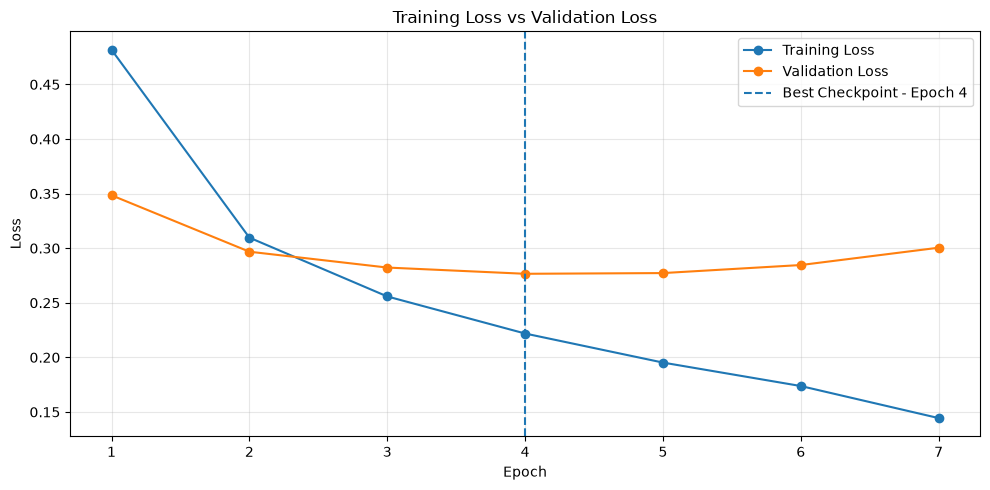

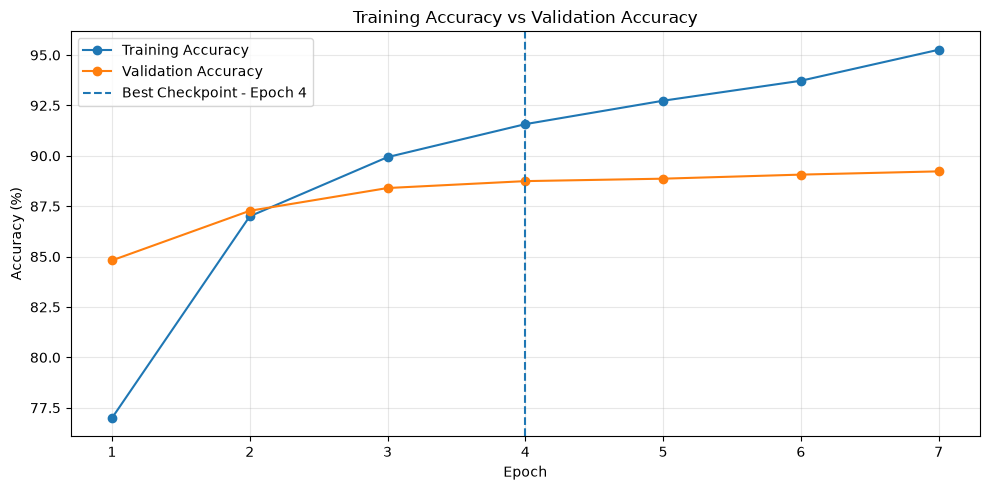

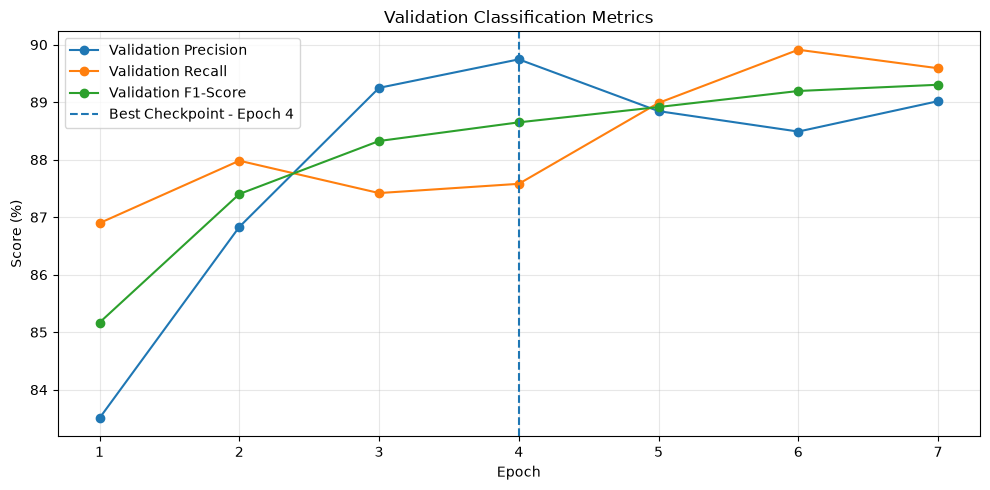


BEST CHECKPOINT INFORMATION
Best Epoch: 4
Best Validation Loss: 0.27656480731287036

GENERATED VISUALIZATIONS
File: loss_curve.png
Exists: True
File: accuracy_curve.png
Exists: True
File: validation_metrics.png
Exists: True

ALL VISUALIZATION CHECKS PASSED!
CELL 4 COMPLETED SUCCESSFULLY!


In [39]:

import json
import pandas as pd
import matplotlib.pyplot as plt

TRAINING_HISTORY_PATH = (
    TRAINING_DIR / "training_history.csv"
)

TRAINING_REPORT_PATH = (
    TRAINING_DIR / "training_summary.json"
)

if not TRAINING_HISTORY_PATH.is_file():
    raise FileNotFoundError("Training history not found.")

if not TRAINING_REPORT_PATH.is_file():
    raise FileNotFoundError("Training summary not found.")

history_df = pd.read_csv(TRAINING_HISTORY_PATH)

with open(TRAINING_REPORT_PATH, "r", encoding="utf-8") as file:
    training_summary = json.load(file)

best_epoch = training_summary["best_epoch"]

required_metrics = [
    "epoch",
    "train_loss",
    "train_accuracy",
    "val_loss",
    "val_accuracy",
    "val_precision",
    "val_recall",
    "val_f1_score"
]

if not set(required_metrics).issubset(history_df.columns):
    raise ValueError("Training history columns are incomplete.")

if history_df.empty:
    raise ValueError("Training history is empty.")

if best_epoch not in history_df["epoch"].values:
    raise ValueError("Best epoch not found in training history.")

PLOT_DIR = TRAINING_DIR / "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

epochs = history_df["epoch"]

print("=" * 65)
print("PHASE 5 - CELL 4: TRAINING PERFORMANCE VISUALIZATION")
print("=" * 65)

print("\nTRAINING HISTORY")
display(history_df[required_metrics].round(4))

plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    history_df["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    history_df["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Checkpoint - Epoch {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss vs Validation Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

loss_plot_path = PLOT_DIR / "loss_curve.png"
plt.savefig(loss_plot_path, dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    history_df["train_accuracy"] * 100,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs,
    history_df["val_accuracy"] * 100,
    marker="o",
    label="Validation Accuracy"
)

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Checkpoint - Epoch {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training Accuracy vs Validation Accuracy")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

accuracy_plot_path = PLOT_DIR / "accuracy_curve.png"
plt.savefig(accuracy_plot_path, dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    history_df["val_precision"] * 100,
    marker="o",
    label="Validation Precision"
)

plt.plot(
    epochs,
    history_df["val_recall"] * 100,
    marker="o",
    label="Validation Recall"
)

plt.plot(
    epochs,
    history_df["val_f1_score"] * 100,
    marker="o",
    label="Validation F1-Score"
)

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Checkpoint - Epoch {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Score (%)")
plt.title("Validation Classification Metrics")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

metrics_plot_path = PLOT_DIR / "validation_metrics.png"
plt.savefig(metrics_plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("\nBEST CHECKPOINT INFORMATION")
print("Best Epoch:", best_epoch)
print("Best Validation Loss:", training_summary["best_validation_loss"])

print("\nGENERATED VISUALIZATIONS")

for plot_path in [
    loss_plot_path,
    accuracy_plot_path,
    metrics_plot_path
]:
    print("File:", plot_path.name)
    print("Exists:", plot_path.is_file())

assert loss_plot_path.is_file()
assert accuracy_plot_path.is_file()
assert metrics_plot_path.is_file()

print("\nALL VISUALIZATION CHECKS PASSED!")
print("CELL 4 COMPLETED SUCCESSFULLY!")


In [40]:

import hashlib
import json
import pandas as pd
import torch

BEST_MODEL_PATH = CHECKPOINT_DIR / "best_model.pt"

TRAINING_HISTORY_PATH = (
    TRAINING_DIR / "training_history.csv"
)

if not BEST_MODEL_PATH.is_file():
    raise FileNotFoundError("Best model checkpoint not found.")

if not TRAINING_HISTORY_PATH.is_file():
    raise FileNotFoundError("Training history not found.")

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE,
    weights_only=True
)

required_keys = {
    "epoch",
    "model_state_dict",
    "optimizer_state_dict",
    "scheduler_state_dict",
    "best_val_loss",
    "model_config",
    "training_config"
}

missing_keys = required_keys - set(checkpoint.keys())

if missing_keys:
    raise ValueError(
        f"Checkpoint is incomplete: {missing_keys}"
    )

if checkpoint["model_config"] != MODEL_CONFIG:
    raise ValueError("Model configuration mismatch.")

if checkpoint["training_config"] != TRAINING_CONFIG:
    raise ValueError("Training configuration mismatch.")

load_result = model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

if load_result.missing_keys or load_result.unexpected_keys:
    raise ValueError("Model state dictionary mismatch.")

model.eval()

history_df = pd.read_csv(TRAINING_HISTORY_PATH)

checkpoint_epoch = int(checkpoint["epoch"])

best_epoch_history = history_df.loc[
    history_df["epoch"] == checkpoint_epoch
]

if len(best_epoch_history) != 1:
    raise ValueError("Best epoch not found in training history.")

best_epoch_record = best_epoch_history.iloc[0]

expected_val_loss = float(
    best_epoch_record["val_loss"]
)

checkpoint_val_loss = float(
    checkpoint["best_val_loss"]
)

if abs(checkpoint_val_loss - expected_val_loss) > 1e-6:
    raise ValueError("Checkpoint validation loss mismatch.")

loaded_metrics = evaluate_one_epoch(
    model=model,
    data_loader=validation_loader,
    criterion=criterion,
    device=DEVICE
)

metric_comparisons = {
    "loss": expected_val_loss,
    "accuracy": float(best_epoch_record["val_accuracy"]),
    "precision": float(best_epoch_record["val_precision"]),
    "recall": float(best_epoch_record["val_recall"]),
    "f1_score": float(best_epoch_record["val_f1_score"])
}

comparison_results = {}

for metric_name, expected_value in metric_comparisons.items():

    actual_value = loaded_metrics[metric_name]

    comparison_results[metric_name] = (
        abs(actual_value - expected_value) <= 1e-5
    )

if not all(comparison_results.values()):
    raise ValueError(
        "Loaded model metrics do not match the best epoch."
    )

all_parameters_finite = all(
    torch.isfinite(parameter).all().item()
    for parameter in model.parameters()
)

padding_embedding_zero = (
    torch.count_nonzero(
        model.embedding.weight[PAD_INDEX]
    ).item() == 0
)

optimizer_state_available = (
    "state" in checkpoint["optimizer_state_dict"]
    and len(checkpoint["optimizer_state_dict"]["state"]) > 0
)

scheduler_state_available = (
    "last_epoch" in checkpoint["scheduler_state_dict"]
)

sha256_hash = hashlib.sha256()

with open(BEST_MODEL_PATH, "rb") as checkpoint_file:
    for chunk in iter(
        lambda: checkpoint_file.read(1024 * 1024),
        b""
    ):
        sha256_hash.update(chunk)

checkpoint_hash = sha256_hash.hexdigest()

verification_report = {
    "model_name": MODEL_CONFIG["model_name"],
    "checkpoint_epoch": checkpoint_epoch,
    "best_validation_loss": checkpoint_val_loss,
    "loaded_validation_metrics": loaded_metrics,
    "metric_comparison": comparison_results,
    "optimizer_state_available": optimizer_state_available,
    "scheduler_state_available": scheduler_state_available,
    "all_parameters_finite": all_parameters_finite,
    "padding_embedding_zero": padding_embedding_zero,
    "checkpoint_sha256": checkpoint_hash,
    "status": "VERIFIED"
}

VERIFICATION_PATH = (
    TRAINING_DIR / "best_checkpoint_verification.json"
)

with open(VERIFICATION_PATH, "w", encoding="utf-8") as file:
    json.dump(
        verification_report,
        file,
        indent=4
    )

print("=" * 65)
print("PHASE 5 - CELL 5: BEST MODEL CHECKPOINT VERIFICATION")
print("=" * 65)

print("\nCHECKPOINT INFORMATION")
print("Checkpoint Path:", BEST_MODEL_PATH)
print("Checkpoint Exists:", BEST_MODEL_PATH.exists())
print("Best Epoch:", checkpoint_epoch)
print("Best Validation Loss:", round(checkpoint_val_loss, 4))

print("\nRESTORED MODEL VALIDATION RESULTS")

for metric_name, value in loaded_metrics.items():
    print(f"{metric_name}: {value:.4f}")

print("\nMETRIC COMPARISON")

for metric_name, passed in comparison_results.items():
    print(f"{metric_name}: {'PASS' if passed else 'FAIL'}")

print("\nCHECKPOINT INTEGRITY")
print("Optimizer State Available:", optimizer_state_available)
print("Scheduler State Available:", scheduler_state_available)
print("All Parameters Finite:", all_parameters_finite)
print("Padding Embedding Zero:", padding_embedding_zero)

print("\nCHECKPOINT SHA256")
print(checkpoint_hash)

print("\nVERIFICATION REPORT")
print("Saved File:", VERIFICATION_PATH)
print("File Exists:", VERIFICATION_PATH.exists())

assert checkpoint_epoch == 4
assert all(comparison_results.values())
assert optimizer_state_available
assert scheduler_state_available
assert all_parameters_finite
assert padding_embedding_zero
assert VERIFICATION_PATH.is_file()

print("\nALL CHECKPOINT VERIFICATION CHECKS PASSED!")
print("CELL 5 COMPLETED SUCCESSFULLY!")


PHASE 5 - CELL 5: BEST MODEL CHECKPOINT VERIFICATION

CHECKPOINT INFORMATION
Checkpoint Path: D:\Ai_Ml_intren\week_4\outputs\checkpoints\best_model.pt
Checkpoint Exists: True
Best Epoch: 4
Best Validation Loss: 0.2766

RESTORED MODEL VALIDATION RESULTS
loss: 0.2766
accuracy: 0.8875
precision: 0.8974
recall: 0.8758
f1_score: 0.8865

METRIC COMPARISON
loss: PASS
accuracy: PASS
precision: PASS
recall: PASS
f1_score: PASS

CHECKPOINT INTEGRITY
Optimizer State Available: True
Scheduler State Available: True
All Parameters Finite: True
Padding Embedding Zero: True

CHECKPOINT SHA256
5d75af3790ebe764dac058c4906262a3721e552db7349f524ebe3241ff4125dd

VERIFICATION REPORT
Saved File: D:\Ai_Ml_intren\week_4\outputs\training\best_checkpoint_verification.json
File Exists: True

ALL CHECKPOINT VERIFICATION CHECKS PASSED!
CELL 5 COMPLETED SUCCESSFULLY!


In [41]:

import json
import hashlib
import pandas as pd
import torch
from pathlib import Path

REPORT_DIR = PROJECT_DIR / "outputs" / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = CHECKPOINT_DIR / "best_model.pt"

TRAINING_HISTORY_PATH = TRAINING_DIR / "training_history.csv"
TRAINING_REPORT_PATH = TRAINING_DIR / "training_summary.json"
VERIFICATION_PATH = TRAINING_DIR / "best_checkpoint_verification.json"

PLOT_DIR = TRAINING_DIR / "plots"

required_plots = [
    PLOT_DIR / "loss_curve.png",
    PLOT_DIR / "accuracy_curve.png",
    PLOT_DIR / "validation_metrics.png"
]

required_files = [
    BEST_MODEL_PATH,
    TRAINING_HISTORY_PATH,
    TRAINING_REPORT_PATH,
    VERIFICATION_PATH,
    *required_plots
]

for file_path in required_files:
    if not file_path.is_file():
        raise FileNotFoundError(
            f"Required file not found: {file_path}"
        )

history_df = pd.read_csv(TRAINING_HISTORY_PATH)

with open(TRAINING_REPORT_PATH, "r", encoding="utf-8") as file:
    training_summary = json.load(file)

with open(VERIFICATION_PATH, "r", encoding="utf-8") as file:
    checkpoint_report = json.load(file)

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE,
    weights_only=True
)

required_metrics = [
    "train_loss",
    "train_accuracy",
    "val_loss",
    "val_accuracy",
    "val_precision",
    "val_recall",
    "val_f1_score"
]

if history_df.empty:
    raise ValueError("Training history is empty.")

if not set(required_metrics).issubset(history_df.columns):
    raise ValueError("Training history is incomplete.")

if not history_df[required_metrics].apply(
    lambda column: pd.to_numeric(
        column,
        errors="coerce"
    ).map(lambda value: torch.isfinite(
        torch.tensor(value)
    ).item()).all()
).all():
    raise ValueError("Invalid training metrics found.")

completed_epochs = len(history_df)

best_epoch = int(training_summary["best_epoch"])

if best_epoch not in history_df["epoch"].values:
    raise ValueError("Best epoch not found.")

best_record = history_df.loc[
    history_df["epoch"] == best_epoch
].iloc[0]

minimum_loss_epoch = int(
    history_df.loc[
        history_df["val_loss"].idxmin(),
        "epoch"
    ]
)

if minimum_loss_epoch != best_epoch:
    raise ValueError("Best checkpoint epoch mismatch.")

if int(checkpoint["epoch"]) != best_epoch:
    raise ValueError("Checkpoint epoch mismatch.")

if abs(
    float(checkpoint["best_val_loss"])
    - float(best_record["val_loss"])
) > 1e-6:
    raise ValueError("Best validation loss mismatch.")

if completed_epochs > TRAINING_CONFIG["epochs"]:
    raise ValueError("Unexpected number of training epochs.")

checkpoint_hash = hashlib.sha256(
    BEST_MODEL_PATH.read_bytes()
).hexdigest()

if checkpoint_hash != checkpoint_report["checkpoint_sha256"]:
    raise ValueError("Checkpoint SHA256 mismatch.")

model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

model.eval()

restored_metrics = evaluate_one_epoch(
    model=model,
    data_loader=validation_loader,
    criterion=criterion,
    device=DEVICE
)

metric_names = [
    "loss",
    "accuracy",
    "precision",
    "recall",
    "f1_score"
]

for metric_name in metric_names:

    expected_value = float(
        best_record[
            "val_" + metric_name
            if metric_name != "loss"
            else "val_loss"
        ]
    )

    actual_value = restored_metrics[metric_name]

    if abs(actual_value - expected_value) > 1e-5:
        raise ValueError(
            f"Validation metric mismatch: {metric_name}"
        )

optimizer_available = (
    len(checkpoint["optimizer_state_dict"]["state"]) > 0
)

scheduler_available = (
    "last_epoch" in checkpoint["scheduler_state_dict"]
)

padding_is_zero = (
    torch.count_nonzero(
        model.embedding.weight[PAD_INDEX]
    ).item() == 0
)

parameters_finite = all(
    torch.isfinite(parameter).all().item()
    for parameter in model.parameters()
)

early_stopping_counter = int(
    history_df.loc[
        history_df["epoch"] > best_epoch,
        "best_model_updated"
    ].eq(False).sum()
)

early_stopping_verified = (
    completed_epochs < TRAINING_CONFIG["epochs"]
    and early_stopping_counter
    >= TRAINING_CONFIG["early_stopping_patience"]
)

if not early_stopping_verified:
    raise ValueError("Early stopping verification failed.")

visualization_status = {
    file_path.name: file_path.is_file()
    for file_path in required_plots
}

phase5_report = {
    "project": "IMDB Customer Sentiment Analysis",
    "framework": "PyTorch",
    "device": str(DEVICE),
    "epochs_completed": completed_epochs,
    "maximum_epochs": TRAINING_CONFIG["epochs"],
    "best_epoch": best_epoch,
    "best_validation_loss": float(best_record["val_loss"]),
    "best_validation_accuracy": float(best_record["val_accuracy"]),
    "best_validation_precision": float(best_record["val_precision"]),
    "best_validation_recall": float(best_record["val_recall"]),
    "best_validation_f1_score": float(best_record["val_f1_score"]),
    "early_stopping_verified": early_stopping_verified,
    "optimizer_state_verified": optimizer_available,
    "scheduler_state_verified": scheduler_available,
    "checkpoint_hash_verified": True,
    "restored_model_verified": True,
    "padding_embedding_zero": padding_is_zero,
    "model_parameters_finite": parameters_finite,
    "visualizations": visualization_status,
    "checkpoint_path": str(BEST_MODEL_PATH),
    "status": "COMPLETED"
}

REPORT_PATH = REPORT_DIR / "phase5_summary.json"

with open(REPORT_PATH, "w", encoding="utf-8") as file:
    json.dump(
        phase5_report,
        file,
        indent=4
    )

print("=" * 65)
print("WEEK 4 - PHASE 5 FINAL VERIFICATION")
print("=" * 65)

print("\nTRAINING SUMMARY")
print("Completed Epochs:", completed_epochs)
print("Best Epoch:", best_epoch)
print("Early Stopping Verified:", early_stopping_verified)

print("\nBEST VALIDATION PERFORMANCE")

print("Loss:", round(best_record["val_loss"], 4))
print("Accuracy:", round(best_record["val_accuracy"] * 100, 2), "%")
print("Precision:", round(best_record["val_precision"] * 100, 2), "%")
print("Recall:", round(best_record["val_recall"] * 100, 2), "%")
print("F1-Score:", round(best_record["val_f1_score"] * 100, 2), "%")

print("\nCHECKPOINT VERIFICATION")
print("Checkpoint Exists:", BEST_MODEL_PATH.exists())
print("Checkpoint Epoch:", checkpoint["epoch"])
print("Optimizer State:", optimizer_available)
print("Scheduler State:", scheduler_available)
print("SHA256 Verification: PASS")
print("Restored Model Verification: PASS")

print("\nMODEL INTEGRITY")
print("Padding Embedding Zero:", padding_is_zero)
print("All Parameters Finite:", parameters_finite)

print("\nVISUALIZATION VERIFICATION")

for plot_name, status in visualization_status.items():
    print(f"{plot_name}: {'PASS' if status else 'FAIL'}")

print("\nFINAL REPORT:", REPORT_PATH)
print("Report Exists:", REPORT_PATH.exists())

assert best_epoch == 4
assert optimizer_available
assert scheduler_available
assert padding_is_zero
assert parameters_finite
assert all(visualization_status.values())
assert REPORT_PATH.is_file()

print("\nALL PHASE 5 VERIFICATION CHECKS PASSED!")
print("PHASE 5 COMPLETED SUCCESSFULLY!")


WEEK 4 - PHASE 5 FINAL VERIFICATION

TRAINING SUMMARY
Completed Epochs: 7
Best Epoch: 4
Early Stopping Verified: True

BEST VALIDATION PERFORMANCE
Loss: 0.2766
Accuracy: 88.75 %
Precision: 89.74 %
Recall: 87.58 %
F1-Score: 88.65 %

CHECKPOINT VERIFICATION
Checkpoint Exists: True
Checkpoint Epoch: 4
Optimizer State: True
Scheduler State: True
SHA256 Verification: PASS
Restored Model Verification: PASS

MODEL INTEGRITY
Padding Embedding Zero: True
All Parameters Finite: True

VISUALIZATION VERIFICATION
loss_curve.png: PASS
accuracy_curve.png: PASS
validation_metrics.png: PASS

FINAL REPORT: D:\Ai_Ml_intren\week_4\outputs\reports\phase5_summary.json
Report Exists: True

ALL PHASE 5 VERIFICATION CHECKS PASSED!
PHASE 5 COMPLETED SUCCESSFULLY!


In [2]:

import hashlib
import json

from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader


# ============================================================
# 1. PROJECT PATHS
# ============================================================

PROJECT_DIR = Path(r"D:\Ai_Ml_intren\week_4")
OUTPUT_DIR = PROJECT_DIR / "outputs"

CHECKPOINT_PATH = OUTPUT_DIR / "checkpoints" / "best_model.pt"
VOCABULARY_PATH = OUTPUT_DIR / "vocabulary" / "vocabulary.json"
MODEL_CONFIG_PATH = OUTPUT_DIR / "config" / "model_config.json"

TEST_DATA_PATH = OUTPUT_DIR / "preprocessed" / "test.csv"
TEST_SEQUENCE_PATH = OUTPUT_DIR / "encoded_sequences" / "test_padded.npy"

VERIFICATION_PATH = (
    OUTPUT_DIR / "training" / "best_checkpoint_verification.json"
)

required_files = [
    CHECKPOINT_PATH,
    VOCABULARY_PATH,
    MODEL_CONFIG_PATH,
    TEST_DATA_PATH,
    TEST_SEQUENCE_PATH,
    VERIFICATION_PATH
]

for file_path in required_files:
    if not file_path.is_file():
        raise FileNotFoundError(
            f"Required file not found: {file_path}"
        )


# ============================================================
# 2. LOAD CONFIGURATIONS
# ============================================================

with open(VOCABULARY_PATH, "r", encoding="utf-8") as file:
    vocabulary_config = json.load(file)

with open(MODEL_CONFIG_PATH, "r", encoding="utf-8") as file:
    saved_model_config = json.load(file)

with open(VERIFICATION_PATH, "r", encoding="utf-8") as file:
    previous_verification = json.load(file)

VOCAB_SIZE = vocabulary_config["total_vocabulary_size"]
MAX_LENGTH = vocabulary_config["maximum_sequence_length"]
PAD_INDEX = vocabulary_config["padding_index"]
UNK_INDEX = vocabulary_config["unknown_index"]

BATCH_SIZE = saved_model_config["batch_size"]

LABEL_MAPPING = {
    "negative": 0,
    "positive": 1
}

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

assert VOCAB_SIZE == saved_model_config["vocab_size"]
assert MAX_LENGTH == saved_model_config["max_sequence_length"]
assert PAD_INDEX == saved_model_config["padding_idx"]


# ============================================================
# 3. RESTORE ORIGINAL MODEL ARCHITECTURE
# ============================================================

class SentimentClassifier(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim,
        hidden_dim,
        output_dim,
        padding_idx,
        dropout
    ):
        super().__init__()

        self.padding_idx = padding_idx

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=padding_idx
        )

        self.fc1 = nn.Linear(
            embedding_dim,
            hidden_dim
        )

        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)

        self.output_layer = nn.Linear(
            hidden_dim,
            output_dim
        )

    def forward(self, input_ids):

        padding_mask = (
            input_ids != self.padding_idx
        ).unsqueeze(-1)

        embedded = self.embedding(input_ids)

        masked_embeddings = (
            embedded * padding_mask
        )

        summed_embeddings = masked_embeddings.sum(dim=1)

        token_counts = padding_mask.sum(dim=1).clamp(min=1)

        pooled = summed_embeddings / token_counts

        hidden = self.fc1(pooled)
        hidden = self.relu(hidden)
        hidden = self.dropout(hidden)

        logits = self.output_layer(hidden)

        return logits.squeeze(-1)


# ============================================================
# 4. VERIFY AND LOAD BEST CHECKPOINT
# ============================================================

sha256 = hashlib.sha256()

with open(CHECKPOINT_PATH, "rb") as file:
    for chunk in iter(
        lambda: file.read(1024 * 1024),
        b""
    ):
        sha256.update(chunk)

checkpoint_hash = sha256.hexdigest()

if checkpoint_hash != previous_verification["checkpoint_sha256"]:
    raise ValueError("Checkpoint SHA256 mismatch.")

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

if checkpoint["model_config"] != saved_model_config:
    raise ValueError("Model configuration mismatch.")

test_model = SentimentClassifier(
    vocab_size=saved_model_config["vocab_size"],
    embedding_dim=saved_model_config["embedding_dim"],
    hidden_dim=saved_model_config["hidden_dim"],
    output_dim=saved_model_config["output_dim"],
    padding_idx=saved_model_config["padding_idx"],
    dropout=saved_model_config["dropout"]
)

test_model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

test_model = test_model.to(DEVICE)
test_model.eval()

test_criterion = nn.BCEWithLogitsLoss()


# ============================================================
# 5. RESTORE TEST DATASET
# ============================================================

class IMDBReviewDataset(Dataset):

    def __init__(self, sequences, labels):

        if len(sequences) != len(labels):
            raise ValueError("Sequence and label count mismatch.")

        self.sequences = torch.from_numpy(
            np.ascontiguousarray(sequences)
        ).long()

        self.labels = torch.as_tensor(
            labels,
            dtype=torch.float32
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return self.sequences[index], self.labels[index]


def collate_batch(batch):

    sequences, labels = zip(*batch)

    batch_sequences = torch.stack(sequences)
    batch_labels = torch.stack(labels)

    sequence_lengths = (
        batch_sequences != PAD_INDEX
    ).sum(dim=1)

    batch_max_length = int(
        sequence_lengths.max().item()
    )

    batch_sequences = batch_sequences[:, :batch_max_length]

    return batch_sequences, batch_labels


test_df = pd.read_csv(TEST_DATA_PATH)

test_sequences = np.load(TEST_SEQUENCE_PATH)

test_labels = test_df["sentiment"].map(LABEL_MAPPING)

if test_labels.isna().any():
    raise ValueError("Invalid test sentiment labels.")

test_labels = test_labels.to_numpy(dtype=np.float32)

if test_sequences.shape != (len(test_df), MAX_LENGTH):
    raise ValueError("Test sequence shape mismatch.")

if test_sequences.dtype != np.int64:
    raise TypeError("Test sequences must be int64.")

if test_sequences.min() < 0:
    raise ValueError("Negative token index detected.")

if test_sequences.max() >= VOCAB_SIZE:
    raise ValueError("Token index exceeds vocabulary size.")

test_dataset = IMDBReviewDataset(
    sequences=test_sequences,
    labels=test_labels
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
    collate_fn=collate_batch
)


# ============================================================
# 6. FINAL INTEGRITY VERIFICATION
# ============================================================

parameters_finite = all(
    torch.isfinite(parameter).all().item()
    for parameter in test_model.parameters()
)

padding_is_zero = (
    torch.count_nonzero(
        test_model.embedding.weight[PAD_INDEX]
    ).item() == 0
)

loader_data_matches = (
    np.array_equal(
        test_sequences,
        test_dataset.sequences.numpy()
    )
    and np.array_equal(
        test_labels,
        test_dataset.labels.numpy()
    )
)

total_parameters = sum(
    parameter.numel()
    for parameter in test_model.parameters()
)

assert checkpoint["epoch"] == 4
assert VOCAB_SIZE == 30002
assert MAX_LENGTH == 298
assert len(test_dataset) == 4959
assert len(test_loader) == 39
assert total_parameters == 3856897
assert parameters_finite
assert padding_is_zero
assert loader_data_matches
assert not test_model.training


# ============================================================
# 7. VERIFICATION REPORT
# ============================================================

print("=" * 65)
print("PHASE 6 - CELL 1: TEST ENVIRONMENT VERIFICATION")
print("=" * 65)

print("\nMODEL INFORMATION")
print("Model Name:", saved_model_config["model_name"])
print("Selected Device:", DEVICE)
print("Best Checkpoint Epoch:", checkpoint["epoch"])
print("Total Parameters:", total_parameters)
print("Checkpoint Loaded: PASS")
print("SHA256 Verification: PASS")

print("\nVOCABULARY INFORMATION")
print("Vocabulary Size:", VOCAB_SIZE)
print("Maximum Sequence Length:", MAX_LENGTH)
print("Padding Index:", PAD_INDEX)
print("Unknown Index:", UNK_INDEX)

print("\nTEST DATASET")
print("Total Reviews:", len(test_df))
print("Numerical Sequence Shape:", test_sequences.shape)
print("Sequence Data Type:", test_sequences.dtype)
print("Batch Size:", BATCH_SIZE)
print("Total Test Batches:", len(test_loader))

print("\nSENTIMENT DISTRIBUTION")
print(test_df["sentiment"].value_counts())

print("\nMODEL INTEGRITY")
print("All Parameters Finite:", parameters_finite)
print("Padding Embedding Zero:", padding_is_zero)
print("Model Evaluation Mode:", not test_model.training)
print("Test DataLoader Verification:", loader_data_matches)

print("\nALL TEST ENVIRONMENT CHECKS PASSED!")
print("CELL 1 COMPLETED SUCCESSFULLY!")


PHASE 6 - CELL 1: TEST ENVIRONMENT VERIFICATION

MODEL INFORMATION
Model Name: IMDB_Embedding_MLP
Selected Device: cuda
Best Checkpoint Epoch: 4
Total Parameters: 3856897
Checkpoint Loaded: PASS
SHA256 Verification: PASS

VOCABULARY INFORMATION
Vocabulary Size: 30002
Maximum Sequence Length: 298
Padding Index: 0
Unknown Index: 1

TEST DATASET
Total Reviews: 4959
Numerical Sequence Shape: (4959, 298)
Sequence Data Type: int64
Batch Size: 128
Total Test Batches: 39

SENTIMENT DISTRIBUTION
sentiment
positive    2489
negative    2470
Name: count, dtype: int64

MODEL INTEGRITY
All Parameters Finite: True
Padding Embedding Zero: True
Model Evaluation Mode: True
Test DataLoader Verification: True

ALL TEST ENVIRONMENT CHECKS PASSED!
CELL 1 COMPLETED SUCCESSFULLY!


In [3]:

import json

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


# ============================================================
# 1. OUTPUT CONFIGURATION
# ============================================================

TEST_OUTPUT_DIR = OUTPUT_DIR / "testing"
TEST_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TEST_PREDICTIONS_PATH = (
    TEST_OUTPUT_DIR / "test_predictions.csv"
)

TEST_METRICS_PATH = (
    TEST_OUTPUT_DIR / "test_metrics.json"
)

CLASSIFICATION_THRESHOLD = 0.5


# ============================================================
# 2. PREPARE MODEL FOR EVALUATION
# ============================================================

test_model.eval()

all_true_labels = []
all_probabilities = []

total_test_loss = 0.0
total_test_samples = 0


# ============================================================
# 3. RUN TEST EVALUATION
# ============================================================

with torch.inference_mode():

    for sequences, labels in test_loader:

        sequences = sequences.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        logits = test_model(sequences)

        if logits.shape != labels.shape:
            raise ValueError(
                "Model output and label shape mismatch."
            )

        if not torch.isfinite(logits).all():
            raise FloatingPointError(
                "Non-finite logits detected."
            )

        loss = test_criterion(logits, labels)

        if not torch.isfinite(loss):
            raise FloatingPointError(
                "Non-finite test loss detected."
            )

        probabilities = torch.sigmoid(logits)

        batch_size = labels.size(0)

        total_test_loss += loss.item() * batch_size
        total_test_samples += batch_size

        all_true_labels.append(
            labels.cpu().numpy().astype(np.int64)
        )

        all_probabilities.append(
            probabilities.cpu().numpy()
        )


# ============================================================
# 4. COLLECT FINAL PREDICTIONS
# ============================================================

y_true = np.concatenate(all_true_labels)

y_prob = np.concatenate(all_probabilities)

y_pred = (
    y_prob >= CLASSIFICATION_THRESHOLD
).astype(np.int64)

if total_test_samples != len(test_df):
    raise ValueError("Test sample count mismatch.")

if not np.array_equal(
    y_true,
    test_labels.astype(np.int64)
):
    raise ValueError("Test label ordering mismatch.")

if not np.isfinite(y_prob).all():
    raise ValueError("Invalid prediction probabilities.")

if not np.all((y_prob >= 0) & (y_prob <= 1)):
    raise ValueError("Probabilities outside valid range.")

if not np.isin(y_pred, [0, 1]).all():
    raise ValueError("Invalid predicted classes.")


# ============================================================
# 5. CALCULATE TEST METRICS
# ============================================================

test_loss = total_test_loss / total_test_samples

test_accuracy = accuracy_score(
    y_true,
    y_pred
)

test_precision = precision_score(
    y_true,
    y_pred,
    zero_division=0
)

test_recall = recall_score(
    y_true,
    y_pred,
    zero_division=0
)

test_f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0
)

correct_predictions = int(
    np.sum(y_true == y_pred)
)

incorrect_predictions = int(
    np.sum(y_true != y_pred)
)


# ============================================================
# 6. SAVE REVIEW-LEVEL PREDICTIONS
# ============================================================

sentiment_names = {
    0: "negative",
    1: "positive"
}

predictions_df = pd.DataFrame({
    "review_id": np.arange(len(y_true)),
    "actual_label": y_true,
    "actual_sentiment": [
        sentiment_names[int(label)]
        for label in y_true
    ],
    "predicted_label": y_pred,
    "predicted_sentiment": [
        sentiment_names[int(label)]
        for label in y_pred
    ],
    "positive_probability": y_prob,
    "negative_probability": 1.0 - y_prob,
    "correct_prediction": y_true == y_pred
})

predictions_df.to_csv(
    TEST_PREDICTIONS_PATH,
    index=False
)


# ============================================================
# 7. SAVE TEST METRICS
# ============================================================

test_metrics = {
    "model_name": saved_model_config["model_name"],
    "checkpoint_epoch": int(checkpoint["epoch"]),
    "dataset": "IMDB Test Dataset",
    "total_samples": int(total_test_samples),
    "classification_threshold": CLASSIFICATION_THRESHOLD,
    "test_loss": float(test_loss),
    "accuracy": float(test_accuracy),
    "precision": float(test_precision),
    "recall": float(test_recall),
    "f1_score": float(test_f1),
    "correct_predictions": correct_predictions,
    "incorrect_predictions": incorrect_predictions,
    "device": str(DEVICE),
    "model_selection_criterion": "validation_loss",
    "test_used_for_training": False,
    "status": "EVALUATED"
}

with open(TEST_METRICS_PATH, "w", encoding="utf-8") as file:
    json.dump(
        test_metrics,
        file,
        indent=4
    )


# ============================================================
# 8. FINAL VERIFICATION
# ============================================================

assert len(y_true) == 4959
assert len(y_pred) == 4959
assert len(y_prob) == 4959

assert correct_predictions + incorrect_predictions == 4959

assert 0 <= test_accuracy <= 1
assert 0 <= test_precision <= 1
assert 0 <= test_recall <= 1
assert 0 <= test_f1 <= 1

assert np.isfinite(test_loss)
assert not test_model.training

assert TEST_PREDICTIONS_PATH.is_file()
assert TEST_METRICS_PATH.is_file()


# ============================================================
# 9. DISPLAY EVALUATION REPORT
# ============================================================

print("=" * 65)
print("PHASE 6 - CELL 2: FINAL TEST DATASET EVALUATION")
print("=" * 65)

print("\nMODEL INFORMATION")
print("Model:", saved_model_config["model_name"])
print("Checkpoint Epoch:", checkpoint["epoch"])
print("Device:", DEVICE)
print("Evaluation Mode:", not test_model.training)

print("\nTEST DATASET")
print("Total Test Samples:", total_test_samples)
print("Total Batches:", len(test_loader))
print("Classification Threshold:", CLASSIFICATION_THRESHOLD)

print("\nFINAL TEST PERFORMANCE")

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Precision: {test_precision * 100:.2f}%")
print(f"Test Recall: {test_recall * 100:.2f}%")
print(f"Test F1-Score: {test_f1 * 100:.2f}%")

print("\nPREDICTION SUMMARY")
print("Correct Predictions:", correct_predictions)
print("Incorrect Predictions:", incorrect_predictions)

print("\nSAMPLE PREDICTIONS")

display(
    predictions_df.head(10).round(4)
)

print("\nSAVED FILES")
print("Predictions:", TEST_PREDICTIONS_PATH)
print("Metrics:", TEST_METRICS_PATH)

print("Predictions File Exists:", TEST_PREDICTIONS_PATH.exists())
print("Metrics File Exists:", TEST_METRICS_PATH.exists())

print("\nALL TEST EVALUATION CHECKS PASSED!")
print("CELL 2 COMPLETED SUCCESSFULLY!")


PHASE 6 - CELL 2: FINAL TEST DATASET EVALUATION

MODEL INFORMATION
Model: IMDB_Embedding_MLP
Checkpoint Epoch: 4
Device: cuda
Evaluation Mode: True

TEST DATASET
Total Test Samples: 4959
Total Batches: 39
Classification Threshold: 0.5

FINAL TEST PERFORMANCE
Test Loss: 0.2754
Test Accuracy: 88.43%
Test Precision: 89.26%
Test Recall: 87.46%
Test F1-Score: 88.35%

PREDICTION SUMMARY
Correct Predictions: 4385
Incorrect Predictions: 574

SAMPLE PREDICTIONS


,review_id,actual_label,actual_sentiment,predicted_label,predicted_sentiment,positive_probability,negative_probability,correct_prediction
0,0,1,positive,1,positive,0.9497,0.0503,True
1,1,1,positive,0,negative,0.4195,0.5805,False
2,2,0,negative,0,negative,0.0557,0.9443,True
3,3,1,positive,1,positive,0.9893,0.0107,True
4,4,0,negative,1,positive,0.6843,0.3157,False
5,5,1,positive,1,positive,0.6599,0.3401,True
6,6,0,negative,0,negative,0.0000,1.0000,True
7,7,1,positive,1,positive,0.9979,0.0021,True
8,8,0,negative,0,negative,0.0088,0.9912,True
9,9,0,negative,0,negative,0.4605,0.5395,True



SAVED FILES
Predictions: D:\Ai_Ml_intren\week_4\outputs\testing\test_predictions.csv
Metrics: D:\Ai_Ml_intren\week_4\outputs\testing\test_metrics.json
Predictions File Exists: True
Metrics File Exists: True

ALL TEST EVALUATION CHECKS PASSED!
CELL 2 COMPLETED SUCCESSFULLY!


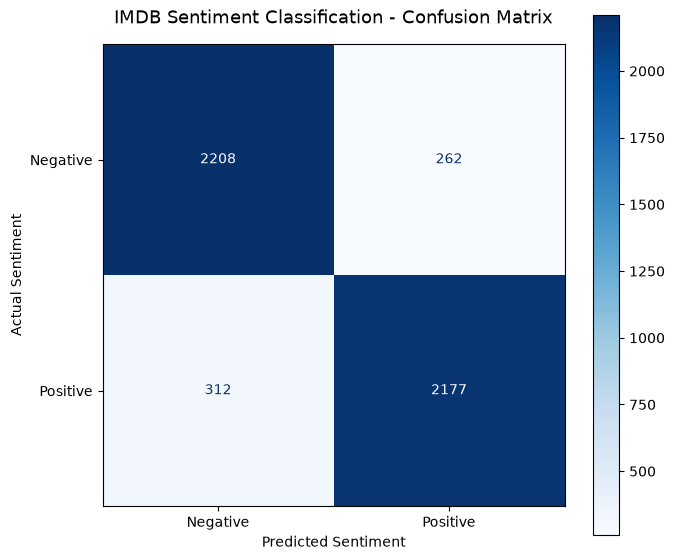

PHASE 6 - CELL 3: CONFUSION MATRIX & CLASSIFICATION REPORT

CONFUSION MATRIX
                 Predicted Negative  Predicted Positive
Actual Negative                2208                 262
Actual Positive                 312                2177

CONFUSION MATRIX DETAILS
True Negatives (TN): 2208
False Positives (FP): 262
False Negatives (FN): 312
True Positives (TP): 2177

PREDICTION SUMMARY
Total Predictions: 4959
Correct Predictions: 4385
Incorrect Predictions: 574

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative     0.8762    0.8939    0.8850      2470
    Positive     0.8926    0.8746    0.8835      2489

    accuracy                         0.8843      4959
   macro avg     0.8844    0.8843    0.8842      4959
weighted avg     0.8844    0.8843    0.8842      4959


TEST METRIC VERIFICATION
accuracy: PASS
precision: PASS
recall: PASS
f1_score: PASS

SAVED FILES
confusion_matrix.png: PASS
confusion_matrix.csv: PASS
classification_report.csv:

In [4]:

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    accuracy_score
)


# ============================================================
# 1. OUTPUT PATH CONFIGURATION
# ============================================================

OUTPUT_DIR = Path(r"D:\Ai_Ml_intren\week_4\outputs")

TEST_OUTPUT_DIR = OUTPUT_DIR / "testing"
PLOT_DIR = TEST_OUTPUT_DIR / "plots"

PLOT_DIR.mkdir(parents=True, exist_ok=True)

PREDICTIONS_PATH = (
    TEST_OUTPUT_DIR / "test_predictions.csv"
)

METRICS_PATH = (
    TEST_OUTPUT_DIR / "test_metrics.json"
)

CONFUSION_MATRIX_PATH = (
    PLOT_DIR / "confusion_matrix.png"
)

CONFUSION_MATRIX_CSV_PATH = (
    TEST_OUTPUT_DIR / "confusion_matrix.csv"
)

CLASSIFICATION_REPORT_CSV_PATH = (
    TEST_OUTPUT_DIR / "classification_report.csv"
)

CLASSIFICATION_REPORT_JSON_PATH = (
    TEST_OUTPUT_DIR / "classification_report.json"
)


# ============================================================
# 2. LOAD SAVED TEST RESULTS
# ============================================================

if not PREDICTIONS_PATH.is_file():
    raise FileNotFoundError(
        "Test predictions file not found."
    )

if not METRICS_PATH.is_file():
    raise FileNotFoundError(
        "Test metrics file not found."
    )

predictions_df = pd.read_csv(PREDICTIONS_PATH)

with open(METRICS_PATH, "r", encoding="utf-8") as file:
    saved_metrics = json.load(file)

required_columns = [
    "review_id",
    "actual_label",
    "predicted_label",
    "positive_probability"
]

if not set(required_columns).issubset(predictions_df.columns):
    raise ValueError(
        "Required prediction columns are missing."
    )

if len(predictions_df) != 4959:
    raise ValueError("Unexpected test sample count.")

if predictions_df["review_id"].duplicated().any():
    raise ValueError("Duplicate review IDs detected.")

if predictions_df[required_columns].isna().any().any():
    raise ValueError("Missing prediction data detected.")

y_true = predictions_df["actual_label"].to_numpy(
    dtype=np.int64
)

y_pred = predictions_df["predicted_label"].to_numpy(
    dtype=np.int64
)

y_prob = predictions_df["positive_probability"].to_numpy(
    dtype=np.float64
)

if not np.isin(y_true, [0, 1]).all():
    raise ValueError("Invalid actual labels.")

if not np.isin(y_pred, [0, 1]).all():
    raise ValueError("Invalid predicted labels.")

if not np.isfinite(y_prob).all():
    raise ValueError("Invalid prediction probabilities.")

if not np.all((y_prob >= 0) & (y_prob <= 1)):
    raise ValueError("Probabilities outside [0, 1].")

threshold = saved_metrics["classification_threshold"]

if not np.array_equal(
    y_pred,
    (y_prob >= threshold).astype(np.int64)
):
    raise ValueError(
        "Saved predictions do not match the classification threshold."
    )


# ============================================================
# 3. COMPUTE CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

total_predictions = int(cm.sum())

correct_predictions = int(tp + tn)

incorrect_predictions = int(fp + fn)

assert total_predictions == len(y_true)

assert correct_predictions == saved_metrics["correct_predictions"]

assert incorrect_predictions == saved_metrics["incorrect_predictions"]


# ============================================================
# 4. GENERATE CLASSIFICATION REPORT
# ============================================================

class_names = ["Negative", "Positive"]

report_text = classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=class_names,
    digits=4,
    zero_division=0
)

report_dict = classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).T


# ============================================================
# 5. VERIFY PREVIOUS TEST METRICS
# ============================================================

calculated_metrics = {
    "accuracy": float(report_dict["accuracy"]),
    "precision": float(report_dict["Positive"]["precision"]),
    "recall": float(report_dict["Positive"]["recall"]),
    "f1_score": float(report_dict["Positive"]["f1-score"])
}

metric_verification = {}

for metric_name, actual_value in calculated_metrics.items():

    expected_value = float(saved_metrics[metric_name])

    metric_verification[metric_name] = bool(
        np.isclose(
            actual_value,
            expected_value,
            rtol=0,
            atol=1e-10
        )
    )

if not all(metric_verification.values()):
    raise ValueError(
        "Classification report does not match saved test metrics."
    )


# ============================================================
# 6. SAVE CONFUSION MATRIX DATA
# ============================================================

cm_df = pd.DataFrame(
    cm,
    index=["Actual Negative", "Actual Positive"],
    columns=["Predicted Negative", "Predicted Positive"]
)

cm_df.to_csv(
    CONFUSION_MATRIX_CSV_PATH
)

report_df.to_csv(
    CLASSIFICATION_REPORT_CSV_PATH,
    index=True
)

classification_summary = {
    "model": saved_metrics["model_name"],
    "checkpoint_epoch": saved_metrics["checkpoint_epoch"],
    "total_test_samples": total_predictions,
    "true_negative": int(tn),
    "false_positive": int(fp),
    "false_negative": int(fn),
    "true_positive": int(tp),
    "correct_predictions": correct_predictions,
    "incorrect_predictions": incorrect_predictions,
    "classification_report": report_dict,
    "metric_verification": metric_verification,
    "status": "VERIFIED"
}

with open(
    CLASSIFICATION_REPORT_JSON_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        classification_summary,
        file,
        indent=4
    )


# ============================================================
# 7. CONFUSION MATRIX VISUALIZATION
# ============================================================

fig, ax = plt.subplots(figsize=(7, 6))

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display_matrix.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=True
)

ax.set_title(
    "IMDB Sentiment Classification - Confusion Matrix",
    fontsize=13,
    pad=15
)

ax.set_xlabel("Predicted Sentiment")
ax.set_ylabel("Actual Sentiment")

plt.tight_layout()

plt.savefig(
    CONFUSION_MATRIX_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 8. FINAL VERIFICATION
# ============================================================

assert cm.shape == (2, 2)
assert correct_predictions + incorrect_predictions == 4959

assert int(cm[0].sum()) == int((y_true == 0).sum())
assert int(cm[1].sum()) == int((y_true == 1).sum())

assert all(metric_verification.values())

required_outputs = [
    CONFUSION_MATRIX_PATH,
    CONFUSION_MATRIX_CSV_PATH,
    CLASSIFICATION_REPORT_CSV_PATH,
    CLASSIFICATION_REPORT_JSON_PATH
]

for output_path in required_outputs:
    if not output_path.is_file():
        raise FileNotFoundError(
            f"Output not saved: {output_path}"
        )


# ============================================================
# 9. DISPLAY FINAL REPORT
# ============================================================

print("=" * 65)
print("PHASE 6 - CELL 3: CONFUSION MATRIX & CLASSIFICATION REPORT")
print("=" * 65)

print("\nCONFUSION MATRIX")
print(cm_df.to_string())

print("\nCONFUSION MATRIX DETAILS")
print("True Negatives (TN):", tn)
print("False Positives (FP):", fp)
print("False Negatives (FN):", fn)
print("True Positives (TP):", tp)

print("\nPREDICTION SUMMARY")
print("Total Predictions:", total_predictions)
print("Correct Predictions:", correct_predictions)
print("Incorrect Predictions:", incorrect_predictions)

print("\nCLASSIFICATION REPORT")
print(report_text)

print("\nTEST METRIC VERIFICATION")

for metric_name, passed in metric_verification.items():
    print(
        f"{metric_name}: {'PASS' if passed else 'FAIL'}"
    )

print("\nSAVED FILES")

for output_path in required_outputs:
    print(
        f"{output_path.name}: "
        f"{'PASS' if output_path.exists() else 'FAIL'}"
    )

print("\nALL CONFUSION MATRIX & CLASSIFICATION CHECKS PASSED!")
print("CELL 3 COMPLETED SUCCESSFULLY!")


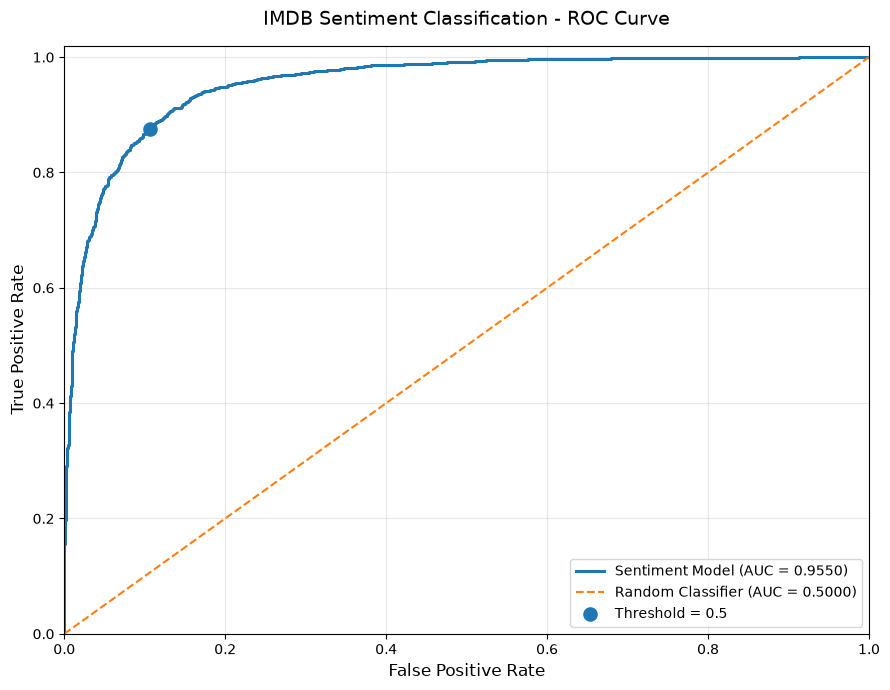

PHASE 6 - CELL 4: ROC CURVE & AUC ANALYSIS

DATASET INFORMATION
Total Test Samples: 4959
Negative Samples: 2470
Positive Samples: 2489

ROC-AUC PERFORMANCE
ROC-AUC Score: 0.9550
ROC-AUC Percentage: 95.50%
Trapezoidal AUC: 0.9550
ROC Curve Points: 828

CLASSIFICATION THRESHOLD ANALYSIS
Current Threshold: 0.5
True Positive Rate: 87.46%
False Positive Rate: 10.61%
True Negative Rate: 89.39%

AUC VERIFICATION
ROC-AUC Calculation: PASS
Curve Integration: PASS
Classification Threshold: UNCHANGED
Model Retraining: NO

SAVED FILES
ROC Plot: D:\Ai_Ml_intren\week_4\outputs\testing\plots\roc_curve.png
ROC Data: D:\Ai_Ml_intren\week_4\outputs\testing\roc_curve_data.csv
ROC Report: D:\Ai_Ml_intren\week_4\outputs\testing\roc_auc_report.json
Plot Exists: True
Data Exists: True
Report Exists: True

ALL ROC-AUC VERIFICATION CHECKS PASSED!
CELL 4 COMPLETED SUCCESSFULLY!


In [5]:

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    auc,
    confusion_matrix
)


# ============================================================
# 1. CONFIGURE OUTPUT PATHS
# ============================================================

OUTPUT_DIR = Path(r"D:\Ai_Ml_intren\week_4\outputs")

TEST_OUTPUT_DIR = OUTPUT_DIR / "testing"
PLOT_DIR = TEST_OUTPUT_DIR / "plots"

PLOT_DIR.mkdir(parents=True, exist_ok=True)

PREDICTIONS_PATH = (
    TEST_OUTPUT_DIR / "test_predictions.csv"
)

METRICS_PATH = (
    TEST_OUTPUT_DIR / "test_metrics.json"
)

ROC_PLOT_PATH = (
    PLOT_DIR / "roc_curve.png"
)

ROC_DATA_PATH = (
    TEST_OUTPUT_DIR / "roc_curve_data.csv"
)

ROC_REPORT_PATH = (
    TEST_OUTPUT_DIR / "roc_auc_report.json"
)


# ============================================================
# 2. LOAD PREVIOUS TEST RESULTS
# ============================================================

if not PREDICTIONS_PATH.is_file():
    raise FileNotFoundError(
        "Test predictions file not found."
    )

if not METRICS_PATH.is_file():
    raise FileNotFoundError(
        "Test metrics file not found."
    )

predictions_df = pd.read_csv(PREDICTIONS_PATH)

with open(METRICS_PATH, "r", encoding="utf-8") as file:
    saved_metrics = json.load(file)

required_columns = [
    "review_id",
    "actual_label",
    "predicted_label",
    "positive_probability"
]

if not set(required_columns).issubset(predictions_df.columns):
    raise ValueError("Required prediction columns are missing.")

if predictions_df[required_columns].isna().any().any():
    raise ValueError("Missing prediction data detected.")

if predictions_df["review_id"].duplicated().any():
    raise ValueError("Duplicate review IDs found.")

if len(predictions_df) != saved_metrics["total_samples"]:
    raise ValueError("Test sample count mismatch.")


# ============================================================
# 3. PREPARE ACTUAL LABELS AND PROBABILITIES
# ============================================================

y_true = predictions_df["actual_label"].to_numpy(
    dtype=np.int64
)

y_pred = predictions_df["predicted_label"].to_numpy(
    dtype=np.int64
)

y_prob = predictions_df["positive_probability"].to_numpy(
    dtype=np.float64
)

if not np.isin(y_true, [0, 1]).all():
    raise ValueError("Invalid actual sentiment labels.")

if not np.isin(y_pred, [0, 1]).all():
    raise ValueError("Invalid predicted sentiment labels.")

if not np.isfinite(y_prob).all():
    raise ValueError("Non-finite prediction probabilities.")

if not np.all((y_prob >= 0) & (y_prob <= 1)):
    raise ValueError("Invalid probability range.")

if len(np.unique(y_true)) != 2:
    raise ValueError("ROC-AUC requires both sentiment classes.")

classification_threshold = float(
    saved_metrics["classification_threshold"]
)

expected_predictions = (
    y_prob >= classification_threshold
).astype(np.int64)

if not np.array_equal(y_pred, expected_predictions):
    raise ValueError(
        "Predicted labels do not match the saved threshold."
    )


# ============================================================
# 4. CALCULATE ROC CURVE AND AUC
# ============================================================

fpr, tpr, thresholds = roc_curve(
    y_true,
    y_prob,
    pos_label=1
)

roc_auc = roc_auc_score(
    y_true,
    y_prob
)

curve_auc = auc(
    fpr,
    tpr
)

if not np.isclose(
    roc_auc,
    curve_auc,
    rtol=0,
    atol=1e-10
):
    raise ValueError(
        "ROC-AUC calculation mismatch."
    )


# ============================================================
# 5. CALCULATE CURRENT OPERATING POINT
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

true_positive_rate = (
    tp / (tp + fn)
)

false_positive_rate = (
    fp / (fp + tn)
)

true_negative_rate = (
    tn / (tn + fp)
)

if not np.isclose(
    true_positive_rate,
    saved_metrics["recall"],
    atol=1e-10
):
    raise ValueError(
        "True Positive Rate does not match test recall."
    )


# ============================================================
# 6. GENERATE ROC VISUALIZATION
# ============================================================

fig, ax = plt.subplots(figsize=(9, 7))

ax.plot(
    fpr,
    tpr,
    linewidth=2.2,
    label=f"Sentiment Model (AUC = {roc_auc:.4f})"
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random Classifier (AUC = 0.5000)"
)

ax.scatter(
    false_positive_rate,
    true_positive_rate,
    s=90,
    zorder=5,
    label=f"Threshold = {classification_threshold}"
)

ax.set_xlabel("False Positive Rate", fontsize=12)
ax.set_ylabel("True Positive Rate", fontsize=12)

ax.set_title(
    "IMDB Sentiment Classification - ROC Curve",
    fontsize=14,
    pad=15
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.grid(alpha=0.3)
ax.legend(loc="lower right")

plt.tight_layout()

plt.savefig(
    ROC_PLOT_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 7. SAVE ROC CURVE DATA
# ============================================================

roc_df = pd.DataFrame({
    "false_positive_rate": fpr,
    "true_positive_rate": tpr,
    "threshold": thresholds
})

roc_df.to_csv(
    ROC_DATA_PATH,
    index=False
)


# ============================================================
# 8. SAVE STRUCTURED ROC REPORT
# ============================================================

roc_report = {
    "model_name": saved_metrics["model_name"],
    "checkpoint_epoch": saved_metrics["checkpoint_epoch"],
    "total_test_samples": int(len(y_true)),
    "positive_class": 1,
    "negative_class": 0,
    "roc_auc": float(roc_auc),
    "curve_auc": float(curve_auc),
    "classification_threshold": classification_threshold,
    "true_positive_rate_at_threshold": float(
        true_positive_rate
    ),
    "false_positive_rate_at_threshold": float(
        false_positive_rate
    ),
    "true_negative_rate_at_threshold": float(
        true_negative_rate
    ),
    "roc_curve_points": int(len(fpr)),
    "roc_plot": str(ROC_PLOT_PATH),
    "roc_data": str(ROC_DATA_PATH),
    "status": "VERIFIED"
}

with open(ROC_REPORT_PATH, "w", encoding="utf-8") as file:
    json.dump(
        roc_report,
        file,
        indent=4
    )


# ============================================================
# 9. FINAL VERIFICATION
# ============================================================

assert len(y_true) == 4959
assert np.isfinite(roc_auc)
assert 0 <= roc_auc <= 1

assert np.isclose(fpr[0], 0)
assert np.isclose(tpr[0], 0)
assert np.isclose(fpr[-1], 1)
assert np.isclose(tpr[-1], 1)

assert np.all(np.diff(fpr) >= 0)
assert np.all(np.diff(tpr) >= 0)

assert ROC_PLOT_PATH.is_file()
assert ROC_DATA_PATH.is_file()
assert ROC_REPORT_PATH.is_file()


# ============================================================
# 10. DISPLAY FINAL RESULTS
# ============================================================

print("=" * 65)
print("PHASE 6 - CELL 4: ROC CURVE & AUC ANALYSIS")
print("=" * 65)

print("\nDATASET INFORMATION")
print("Total Test Samples:", len(y_true))
print("Negative Samples:", int(np.sum(y_true == 0)))
print("Positive Samples:", int(np.sum(y_true == 1)))

print("\nROC-AUC PERFORMANCE")
print(f"ROC-AUC Score: {roc_auc:.4f}")
print(f"ROC-AUC Percentage: {roc_auc * 100:.2f}%")
print(f"Trapezoidal AUC: {curve_auc:.4f}")
print("ROC Curve Points:", len(fpr))

print("\nCLASSIFICATION THRESHOLD ANALYSIS")
print("Current Threshold:", classification_threshold)
print(f"True Positive Rate: {true_positive_rate * 100:.2f}%")
print(f"False Positive Rate: {false_positive_rate * 100:.2f}%")
print(f"True Negative Rate: {true_negative_rate * 100:.2f}%")

print("\nAUC VERIFICATION")
print("ROC-AUC Calculation: PASS")
print("Curve Integration: PASS")
print("Classification Threshold: UNCHANGED")
print("Model Retraining: NO")

print("\nSAVED FILES")
print("ROC Plot:", ROC_PLOT_PATH)
print("ROC Data:", ROC_DATA_PATH)
print("ROC Report:", ROC_REPORT_PATH)

print("Plot Exists:", ROC_PLOT_PATH.is_file())
print("Data Exists:", ROC_DATA_PATH.is_file())
print("Report Exists:", ROC_REPORT_PATH.is_file())

print("\nALL ROC-AUC VERIFICATION CHECKS PASSED!")
print("CELL 4 COMPLETED SUCCESSFULLY!")


In [6]:

import re
import html
import sys
import json

from pathlib import Path

import numpy as np
import pandas as pd
import torch

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS


# ============================================================
# 1. RESTORE PREPROCESSING DEPENDENCIES
# ============================================================

PROJECT_DIR = Path(r"D:\Ai_Ml_intren\week_4")
OUTPUT_DIR = PROJECT_DIR / "outputs"

PACKAGE_DIR = PROJECT_DIR / "packages"

if PACKAGE_DIR.is_dir():
    if str(PACKAGE_DIR) not in sys.path:
        sys.path.insert(0, str(PACKAGE_DIR))

from nltk.stem.snowball import SnowballStemmer

snowball_stemmer = SnowballStemmer("english")

if "test_model" not in globals():
    raise RuntimeError(
        "Run Phase 6 - Cell 1 to restore test_model first."
    )


# ============================================================
# 2. LOAD SAVED VOCABULARY
# ============================================================

VOCABULARY_PATH = (
    OUTPUT_DIR / "vocabulary" / "vocabulary.json"
)

with open(VOCABULARY_PATH, "r", encoding="utf-8") as file:
    vocabulary_config = json.load(file)

word_to_index = {
    word: int(index)
    for word, index in vocabulary_config["token_to_index"].items()
}

PAD_INDEX = vocabulary_config["padding_index"]
UNK_INDEX = vocabulary_config["unknown_index"]

MAX_LENGTH = vocabulary_config["maximum_sequence_length"]
VOCAB_SIZE = vocabulary_config["total_vocabulary_size"]

assert len(word_to_index) == VOCAB_SIZE
assert PAD_INDEX == 0
assert UNK_INDEX == 1


# ============================================================
# 3. RESTORE ORIGINAL TEXT PREPROCESSING
# ============================================================

preserved_words = {
    "no", "not", "nor", "never", "neither",
    "none", "nobody", "nothing", "nowhere",
    "without", "against", "but", "however",
    "very", "too", "only"
}

stop_words = set(ENGLISH_STOP_WORDS) - preserved_words


def preprocess_review(text):

    text = html.unescape(str(text))

    text = re.sub(
        r"<[^>]+>",
        " ",
        text
    )

    text = re.sub(
        r"https?://\S+|www\.\S+",
        " ",
        text,
        flags=re.IGNORECASE
    )

    text = text.replace("’", "'").replace("‘", "'")

    text = text.lower()

    text = re.sub(
        r"[^a-z0-9'\s]",
        " ",
        text
    )

    text = re.sub(r"\s+", " ", text).strip()

    tokens = re.findall(
        r"[a-z]+(?:'[a-z]+)?|\d+",
        text
    )

    filtered_tokens = [
        token
        for token in tokens
        if token not in stop_words
    ]

    stemmed_tokens = [
        token if "'" in token
        else snowball_stemmer.stem(token)
        for token in filtered_tokens
    ]

    return stemmed_tokens


# ============================================================
# 4. NUMERICAL ENCODING AND PADDING
# ============================================================

def encode_custom_review(text):

    tokens = preprocess_review(text)

    if len(tokens) == 0:
        raise ValueError(
            "Review contains no usable tokens."
        )

    token_ids = [
        word_to_index.get(token, UNK_INDEX)
        for token in tokens
    ]

    retained_ids = token_ids[:MAX_LENGTH]

    padded_sequence = np.full(
        MAX_LENGTH,
        PAD_INDEX,
        dtype=np.int64
    )

    padded_sequence[:len(retained_ids)] = retained_ids

    unknown_count = sum(
        token_id == UNK_INDEX
        for token_id in retained_ids
    )

    return padded_sequence, tokens, unknown_count


# ============================================================
# 5. VERIFY PREPROCESSING CONSISTENCY
# ============================================================

saved_test_df = pd.read_csv(
    OUTPUT_DIR / "preprocessed" / "test.csv"
)

saved_test_sequences = np.load(
    OUTPUT_DIR / "encoded_sequences" / "test_padded.npy"
)

verification_indices = [0, 1, 2, 100, 1000]

for index in verification_indices:

    original_review = saved_test_df.iloc[index]["review"]

    encoded_sequence, tokens, _ = encode_custom_review(
        original_review
    )

    expected_text = saved_test_df.iloc[index]["stemmed_review"]

    if " ".join(tokens) != expected_text:
        raise ValueError(
            f"Preprocessing mismatch at test index {index}."
        )

    if not np.array_equal(
        encoded_sequence,
        saved_test_sequences[index]
    ):
        raise ValueError(
            f"Encoding mismatch at test index {index}."
        )


# ============================================================
# 6. THREE NEW CUSTOM SENTENCES
# ============================================================

custom_reviews = [
    (
        "I absolutely loved this movie. "
        "The acting was fantastic and the story "
        "kept me engaged from beginning to end."
    ),
    (
        "This was a terrible movie. "
        "The plot was boring, the acting was awful, "
        "and I regret watching it."
    ),
    (
        "Although the film started slowly, "
        "I really enjoyed the characters "
        "and the ending was wonderful."
    )
]

expected_sentiments = [
    "Positive",
    "Negative",
    "Positive"
]


# ============================================================
# 7. PREPARE MODEL INPUT
# ============================================================

encoded_reviews = []
review_token_counts = []
review_unknown_counts = []

for review in custom_reviews:

    encoded_sequence, tokens, unknown_count = (
        encode_custom_review(review)
    )

    encoded_reviews.append(encoded_sequence)
    review_token_counts.append(len(tokens))
    review_unknown_counts.append(unknown_count)

input_array = np.stack(encoded_reviews)

input_tensor = torch.from_numpy(
    input_array
).long().to(DEVICE)

assert input_tensor.shape == (3, MAX_LENGTH)


# ============================================================
# 8. PREDICT SENTIMENT
# ============================================================

test_model.eval()

with torch.inference_mode():

    logits = test_model(input_tensor)

    positive_probabilities = torch.sigmoid(
        logits
    ).cpu().numpy()

predicted_labels = (
    positive_probabilities >= 0.5
).astype(np.int64)

predicted_sentiments = [
    "Positive" if label == 1 else "Negative"
    for label in predicted_labels
]

predicted_class_scores = np.where(
    predicted_labels == 1,
    positive_probabilities,
    1.0 - positive_probabilities
)


# ============================================================
# 9. BUILD PREDICTION RESULTS
# ============================================================

custom_predictions_df = pd.DataFrame({
    "review_id": [1, 2, 3],
    "review": custom_reviews,
    "expected_sentiment": expected_sentiments,
    "predicted_sentiment": predicted_sentiments,
    "positive_probability": positive_probabilities,
    "predicted_class_score": predicted_class_scores,
    "token_count": review_token_counts,
    "unknown_token_count": review_unknown_counts
})


# ============================================================
# 10. SAVE CUSTOM PREDICTIONS
# ============================================================

CUSTOM_OUTPUT_DIR = OUTPUT_DIR / "testing" / "custom_predictions"

CUSTOM_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

CUSTOM_CSV_PATH = (
    CUSTOM_OUTPUT_DIR / "custom_predictions.csv"
)

CUSTOM_JSON_PATH = (
    CUSTOM_OUTPUT_DIR / "custom_predictions.json"
)

custom_predictions_df.to_csv(
    CUSTOM_CSV_PATH,
    index=False,
    encoding="utf-8"
)

with open(CUSTOM_JSON_PATH, "w", encoding="utf-8") as file:
    json.dump(
        custom_predictions_df.to_dict(orient="records"),
        file,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 11. FINAL VERIFICATION
# ============================================================

assert len(custom_predictions_df) == 3

assert np.isfinite(positive_probabilities).all()

assert np.all(
    (positive_probabilities >= 0)
    & (positive_probabilities <= 1)
)

assert np.isin(
    predicted_labels,
    [0, 1]
).all()

assert CUSTOM_CSV_PATH.is_file()
assert CUSTOM_JSON_PATH.is_file()

assert not test_model.training


# ============================================================
# 12. DISPLAY FINAL RESULTS
# ============================================================

print("=" * 65)
print("PHASE 6 - CELL 5: THREE CUSTOM SENTIMENT PREDICTIONS")
print("=" * 65)

print("\nPREPROCESSING VERIFICATION")
print("Text Cleaning: PASS")
print("Tokenization: PASS")
print("Stopword Removal: PASS")
print("Snowball Stemming: PASS")
print("Vocabulary Encoding: PASS")
print("Padding & Truncation: PASS")
print("Saved Test Sequence Comparison: PASS")

print("\nMODEL INFORMATION")
print("Model:", type(test_model).__name__)
print("Device:", DEVICE)
print("Input Shape:", tuple(input_tensor.shape))
print("Evaluation Mode:", not test_model.training)

print("\n" + "=" * 65)
print("CUSTOM SENTIMENT PREDICTION RESULTS")
print("=" * 65)

for index, row in custom_predictions_df.iterrows():

    print(f"\nREVIEW {index + 1}")
    print("-" * 55)

    print("Sentence:", row["review"])
    print("Expected Sentiment:", row["expected_sentiment"])
    print("Predicted Sentiment:", row["predicted_sentiment"])

    print(
        "Positive Probability:",
        f"{row['positive_probability'] * 100:.2f}%"
    )

    print(
        "Predicted Class Score:",
        f"{row['predicted_class_score'] * 100:.2f}%"
    )

    print("Total Tokens:", row["token_count"])
    print("Unknown Tokens:", row["unknown_token_count"])

    print(
        "Qualitative Check:",
        "MATCH"
        if row["expected_sentiment"] == row["predicted_sentiment"]
        else "MISMATCH"
    )

print("\nSAVED FILES")
print("CSV:", CUSTOM_CSV_PATH)
print("JSON:", CUSTOM_JSON_PATH)

print("\nALL CUSTOM PREDICTION PIPELINE CHECKS PASSED!")
print("CELL 5 COMPLETED SUCCESSFULLY!")


PHASE 6 - CELL 5: THREE CUSTOM SENTIMENT PREDICTIONS

PREPROCESSING VERIFICATION
Text Cleaning: PASS
Tokenization: PASS
Stopword Removal: PASS
Snowball Stemming: PASS
Vocabulary Encoding: PASS
Padding & Truncation: PASS
Saved Test Sequence Comparison: PASS

MODEL INFORMATION
Model: SentimentClassifier
Device: cuda
Input Shape: (3, 298)
Evaluation Mode: True

CUSTOM SENTIMENT PREDICTION RESULTS

REVIEW 1
-------------------------------------------------------
Sentence: I absolutely loved this movie. The acting was fantastic and the story kept me engaged from beginning to end.
Expected Sentiment: Positive
Predicted Sentiment: Positive
Positive Probability: 100.00%
Predicted Class Score: 100.00%
Total Tokens: 10
Unknown Tokens: 0
Qualitative Check: MATCH

REVIEW 2
-------------------------------------------------------
Sentence: This was a terrible movie. The plot was boring, the acting was awful, and I regret watching it.
Expected Sentiment: Negative
Predicted Sentiment: Negative
Positiv

In [7]:

import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score
)


# ============================================================
# 1. PROJECT PATHS
# ============================================================

PROJECT_DIR = Path(r"D:\Ai_Ml_intren\week_4")
OUTPUT_DIR = PROJECT_DIR / "outputs"

TEST_DIR = OUTPUT_DIR / "testing"
PLOT_DIR = TEST_DIR / "plots"
CUSTOM_DIR = TEST_DIR / "custom_predictions"

REPORT_DIR = OUTPUT_DIR / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT_PATH = OUTPUT_DIR / "checkpoints" / "best_model.pt"

CHECKPOINT_VERIFICATION_PATH = (
    OUTPUT_DIR / "training" / "best_checkpoint_verification.json"
)

PREDICTIONS_PATH = TEST_DIR / "test_predictions.csv"
METRICS_PATH = TEST_DIR / "test_metrics.json"

CONFUSION_PATH = TEST_DIR / "confusion_matrix.csv"
CLASSIFICATION_PATH = TEST_DIR / "classification_report.json"

ROC_DATA_PATH = TEST_DIR / "roc_curve_data.csv"
ROC_REPORT_PATH = TEST_DIR / "roc_auc_report.json"

CUSTOM_CSV_PATH = CUSTOM_DIR / "custom_predictions.csv"
CUSTOM_JSON_PATH = CUSTOM_DIR / "custom_predictions.json"

required_files = [
    CHECKPOINT_PATH,
    CHECKPOINT_VERIFICATION_PATH,
    PREDICTIONS_PATH,
    METRICS_PATH,
    CONFUSION_PATH,
    CLASSIFICATION_PATH,
    ROC_DATA_PATH,
    ROC_REPORT_PATH,
    CUSTOM_CSV_PATH,
    CUSTOM_JSON_PATH,
    PLOT_DIR / "confusion_matrix.png",
    PLOT_DIR / "roc_curve.png"
]

for file_path in required_files:
    if not file_path.is_file():
        raise FileNotFoundError(
            f"Required file missing: {file_path}"
        )


# ============================================================
# 2. LOAD SAVED REPORTS
# ============================================================

def load_json(path):
    with open(path, "r", encoding="utf-8") as file:
        return json.load(file)


test_metrics = load_json(METRICS_PATH)
classification_report_data = load_json(CLASSIFICATION_PATH)
roc_report = load_json(ROC_REPORT_PATH)
checkpoint_verification = load_json(
    CHECKPOINT_VERIFICATION_PATH
)

predictions_df = pd.read_csv(PREDICTIONS_PATH)
confusion_df = pd.read_csv(CONFUSION_PATH, index_col=0)
roc_df = pd.read_csv(ROC_DATA_PATH)

custom_df = pd.read_csv(CUSTOM_CSV_PATH)
custom_json = load_json(CUSTOM_JSON_PATH)


# ============================================================
# 3. VERIFY MODEL CHECKPOINT
# ============================================================

sha256 = hashlib.sha256()

with open(CHECKPOINT_PATH, "rb") as file:
    for chunk in iter(
        lambda: file.read(1024 * 1024),
        b""
    ):
        sha256.update(chunk)

checkpoint_hash = sha256.hexdigest()

if checkpoint_hash != checkpoint_verification["checkpoint_sha256"]:
    raise ValueError("Checkpoint SHA256 mismatch.")

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

best_epoch = int(checkpoint["epoch"])

if best_epoch != 4:
    raise ValueError("Unexpected best checkpoint epoch.")

if best_epoch != int(test_metrics["checkpoint_epoch"]):
    raise ValueError("Test checkpoint epoch mismatch.")

if best_epoch != int(roc_report["checkpoint_epoch"]):
    raise ValueError("ROC checkpoint epoch mismatch.")

if checkpoint["model_config"]["vocab_size"] != 30002:
    raise ValueError("Checkpoint vocabulary mismatch.")

model_parameters_finite = all(
    torch.isfinite(parameter).all().item()
    for parameter in checkpoint["model_state_dict"].values()
)

if not model_parameters_finite:
    raise ValueError("Non-finite model weights detected.")


# ============================================================
# 4. VERIFY TEST DATA AND METRICS
# ============================================================

required_columns = [
    "review_id",
    "actual_label",
    "predicted_label",
    "positive_probability"
]

if not set(required_columns).issubset(predictions_df.columns):
    raise ValueError("Prediction columns are incomplete.")

if predictions_df[required_columns].isna().any().any():
    raise ValueError("Missing prediction values detected.")

if predictions_df["review_id"].duplicated().any():
    raise ValueError("Duplicate review IDs detected.")

y_true = predictions_df["actual_label"].to_numpy(dtype=np.int64)
y_pred = predictions_df["predicted_label"].to_numpy(dtype=np.int64)
y_prob = predictions_df["positive_probability"].to_numpy(
    dtype=np.float64
)

if len(y_true) != 4959:
    raise ValueError("Unexpected test sample count.")

if not np.isin(y_true, [0, 1]).all():
    raise ValueError("Invalid actual labels.")

if not np.isin(y_pred, [0, 1]).all():
    raise ValueError("Invalid predicted labels.")

if not np.isfinite(y_prob).all():
    raise ValueError("Invalid probabilities.")

if not np.all((y_prob >= 0) & (y_prob <= 1)):
    raise ValueError("Probabilities outside [0, 1].")

threshold = float(test_metrics["classification_threshold"])

if not np.array_equal(
    y_pred,
    (y_prob >= threshold).astype(np.int64)
):
    raise ValueError("Prediction threshold mismatch.")

calculated_metrics = {
    "accuracy": float(accuracy_score(y_true, y_pred)),
    "precision": float(
        precision_score(y_true, y_pred, zero_division=0)
    ),
    "recall": float(
        recall_score(y_true, y_pred, zero_division=0)
    ),
    "f1_score": float(
        f1_score(y_true, y_pred, zero_division=0)
    )
}

for metric_name, value in calculated_metrics.items():
    if not np.isclose(
        value,
        float(test_metrics[metric_name]),
        rtol=0,
        atol=1e-10
    ):
        raise ValueError(
            f"Test metric mismatch: {metric_name}"
        )


# ============================================================
# 5. VERIFY CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

saved_cm = confusion_df.to_numpy(dtype=np.int64)

if saved_cm.shape != (2, 2):
    raise ValueError("Invalid saved confusion matrix.")

if not np.array_equal(cm, saved_cm):
    raise ValueError("Confusion matrix mismatch.")

tn, fp, fn, tp = map(int, cm.ravel())

correct_predictions = tp + tn
incorrect_predictions = fp + fn

if correct_predictions != int(test_metrics["correct_predictions"]):
    raise ValueError("Correct prediction count mismatch.")

if incorrect_predictions != int(
    test_metrics["incorrect_predictions"]
):
    raise ValueError("Incorrect prediction count mismatch.")

saved_classification = (
    classification_report_data["classification_report"]
)

if not np.isclose(
    saved_classification["accuracy"],
    calculated_metrics["accuracy"],
    rtol=0,
    atol=1e-10
):
    raise ValueError("Classification report mismatch.")

if not all(
    classification_report_data["metric_verification"].values()
):
    raise ValueError("Previous classification verification failed.")


# ============================================================
# 6. VERIFY ROC-AUC
# ============================================================

calculated_auc = float(
    roc_auc_score(y_true, y_prob)
)

saved_auc = float(roc_report["roc_auc"])

roc_fpr = roc_df["false_positive_rate"].to_numpy(
    dtype=np.float64
)

roc_tpr = roc_df["true_positive_rate"].to_numpy(
    dtype=np.float64
)

integrated_auc = float(
    np.trapezoid(roc_tpr, roc_fpr)
)

if not np.isfinite(roc_fpr).all():
    raise ValueError("Invalid saved ROC FPR.")

if not np.isfinite(roc_tpr).all():
    raise ValueError("Invalid saved ROC TPR.")

if not np.isclose(
    calculated_auc,
    saved_auc,
    rtol=0,
    atol=1e-10
):
    raise ValueError("ROC-AUC mismatch.")

if not np.isclose(
    integrated_auc,
    calculated_auc,
    rtol=0,
    atol=1e-10
):
    raise ValueError("ROC integration mismatch.")

if len(roc_df) != int(roc_report["roc_curve_points"]):
    raise ValueError("ROC curve point count mismatch.")


# ============================================================
# 7. VERIFY CUSTOM PREDICTIONS
# ============================================================

required_custom_columns = [
    "review_id",
    "review",
    "expected_sentiment",
    "predicted_sentiment",
    "positive_probability",
    "predicted_class_score",
    "token_count",
    "unknown_token_count"
]

if not set(required_custom_columns).issubset(custom_df.columns):
    raise ValueError("Custom prediction columns missing.")

if len(custom_df) != 3 or len(custom_json) != 3:
    raise ValueError("Expected exactly three custom predictions.")

if custom_df[required_custom_columns].isna().any().any():
    raise ValueError("Missing custom prediction values.")

for index, record in enumerate(custom_json):
    if record["review"] != custom_df.iloc[index]["review"]:
        raise ValueError("Custom CSV and JSON mismatch.")

custom_probabilities = custom_df[
    "positive_probability"
].to_numpy(dtype=np.float64)

if not np.isfinite(custom_probabilities).all():
    raise ValueError("Invalid custom prediction probabilities.")

if not np.all(
    (custom_probabilities >= 0)
    & (custom_probabilities <= 1)
):
    raise ValueError("Custom probabilities outside [0, 1].")

expected_custom_labels = np.where(
    custom_probabilities >= 0.5,
    "Positive",
    "Negative"
)

if not np.array_equal(
    expected_custom_labels,
    custom_df["predicted_sentiment"].to_numpy()
):
    raise ValueError("Custom classification threshold mismatch.")

custom_matches = (
    custom_df["expected_sentiment"]
    == custom_df["predicted_sentiment"]
)

custom_match_count = int(custom_matches.sum())


# ============================================================
# 8. GENERATE FINAL PHASE 6 REPORT
# ============================================================

phase6_report = {
    "project": "IMDB Customer Sentiment Analysis",
    "framework": "PyTorch",
    "phase": 6,
    "best_checkpoint_epoch": best_epoch,
    "checkpoint_sha256_verified": True,
    "total_test_samples": len(y_true),
    "test_loss": float(test_metrics["test_loss"]),
    "test_accuracy": calculated_metrics["accuracy"],
    "test_precision": calculated_metrics["precision"],
    "test_recall": calculated_metrics["recall"],
    "test_f1_score": calculated_metrics["f1_score"],
    "correct_predictions": correct_predictions,
    "incorrect_predictions": incorrect_predictions,
    "confusion_matrix": {
        "true_negative": tn,
        "false_positive": fp,
        "false_negative": fn,
        "true_positive": tp
    },
    "roc_auc": calculated_auc,
    "classification_threshold": threshold,
    "custom_reviews_tested": len(custom_df),
    "custom_predictions_matched": custom_match_count,
    "test_used_for_training": False,
    "model_retraining": False,
    "verification": {
        "checkpoint": "PASS",
        "test_metrics": "PASS",
        "confusion_matrix": "PASS",
        "classification_report": "PASS",
        "roc_auc": "PASS",
        "custom_predictions": "PASS",
        "saved_outputs": "PASS"
    },
    "status": "COMPLETED"
}

REPORT_PATH = REPORT_DIR / "phase6_summary.json"

with open(REPORT_PATH, "w", encoding="utf-8") as file:
    json.dump(
        phase6_report,
        file,
        indent=4
    )


# ============================================================
# 9. DISPLAY FINAL VERIFICATION
# ============================================================

print("=" * 65)
print("WEEK 4 - PHASE 6 FINAL VERIFICATION")
print("=" * 65)

print("\nMODEL VERIFICATION")
print("Best Checkpoint Epoch:", best_epoch)
print("Checkpoint SHA256: PASS")
print("Model Weights Finite:", model_parameters_finite)

print("\nFINAL TEST PERFORMANCE")
print("Total Test Samples:", len(y_true))
print(f"Test Loss: {float(test_metrics['test_loss']):.4f}")

for metric_name, value in calculated_metrics.items():
    print(f"{metric_name.title()}: {value * 100:.2f}%")

print("\nCONFUSION MATRIX")
print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

print("\nPREDICTION SUMMARY")
print("Correct Predictions:", correct_predictions)
print("Incorrect Predictions:", incorrect_predictions)

print("\nROC-AUC")
print(f"ROC-AUC Score: {calculated_auc:.4f}")
print("ROC Verification: PASS")

print("\nCUSTOM PREDICTION VERIFICATION")
print("Total Custom Reviews:", len(custom_df))
print("Expected Sentiment Matches:", custom_match_count)

for _, row in custom_df.iterrows():
    print(
        f"Review {int(row['review_id'])}: "
        f"{row['predicted_sentiment']} | "
        f"Positive Probability: "
        f"{row['positive_probability'] * 100:.2f}%"
    )

print("\nSAVED ARTIFACT VERIFICATION")
print("Required Files Verified:", len(required_files))
print("All Required Files: PASS")

print("\nFINAL REPORT")
print("Report Path:", REPORT_PATH)
print("Report Exists:", REPORT_PATH.is_file())

assert REPORT_PATH.is_file()
assert len(y_true) == 4959
assert correct_predictions == 4385
assert incorrect_predictions == 574
assert all(
    result == "PASS"
    for result in phase6_report["verification"].values()
)

print("\nALL PHASE 6 VERIFICATION CHECKS PASSED!")
print("PHASE 6 COMPLETED SUCCESSFULLY!")


WEEK 4 - PHASE 6 FINAL VERIFICATION

MODEL VERIFICATION
Best Checkpoint Epoch: 4
Checkpoint SHA256: PASS
Model Weights Finite: True

FINAL TEST PERFORMANCE
Total Test Samples: 4959
Test Loss: 0.2754
Accuracy: 88.43%
Precision: 89.26%
Recall: 87.46%
F1_Score: 88.35%

CONFUSION MATRIX
True Negatives: 2208
False Positives: 262
False Negatives: 312
True Positives: 2177

PREDICTION SUMMARY
Correct Predictions: 4385
Incorrect Predictions: 574

ROC-AUC
ROC-AUC Score: 0.9550
ROC Verification: PASS

CUSTOM PREDICTION VERIFICATION
Total Custom Reviews: 3
Expected Sentiment Matches: 3
Review 1: Positive | Positive Probability: 100.00%
Review 2: Negative | Positive Probability: 0.00%
Review 3: Positive | Positive Probability: 99.97%

SAVED ARTIFACT VERIFICATION
Required Files Verified: 12
All Required Files: PASS

FINAL REPORT
Report Path: D:\Ai_Ml_intren\week_4\outputs\reports\phase6_summary.json
Report Exists: True

ALL PHASE 6 VERIFICATION CHECKS PASSED!
PHASE 6 COMPLETED SUCCESSFULLY!


In [10]:

import hashlib
import json
from pathlib import Path

import pandas as pd

PROJECT_DIR = Path(r"D:\Ai_Ml_intren\week_4")
OUTPUT_DIR = PROJECT_DIR / "outputs"

SUBMISSION_DIR = OUTPUT_DIR / "submission"
SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)

MANIFEST_CSV_PATH = SUBMISSION_DIR / "artifact_manifest.csv"
MANIFEST_JSON_PATH = SUBMISSION_DIR / "artifact_manifest.json"

required_artifacts = {
    "Notebook": [
        "notebook.ipynb"
    ],
    "Model & Configuration": [
        "outputs/checkpoints/best_model.pt",
        "outputs/vocabulary/vocabulary.json",
        "outputs/config/model_config.json",
        "outputs/config/training_config.json",
        "outputs/architecture/model_architecture.json"
    ],
    "Phase Reports": [
        "outputs/reports/phase1_summary.json",
        "outputs/reports/phase2_summary.json",
        "outputs/reports/phase3_summary.json",
        "outputs/reports/phase4_summary.json",
        "outputs/reports/phase5_summary.json",
        "outputs/reports/phase6_summary.json"
    ],
    "Dataset Artifacts": [
        "outputs/preprocessed/test.csv",
        "outputs/encoded_sequences/test_padded.npy"
    ],
    "Training Artifacts": [
        "outputs/training/training_history.csv",
        "outputs/training/training_summary.json",
        "outputs/training/best_checkpoint_verification.json"
    ],
    "Testing Artifacts": [
        "outputs/testing/test_predictions.csv",
        "outputs/testing/test_metrics.json",
        "outputs/testing/confusion_matrix.csv",
        "outputs/testing/classification_report.json",
        "outputs/testing/roc_curve_data.csv",
        "outputs/testing/roc_auc_report.json"
    ],
    "Custom Predictions": [
        "outputs/testing/custom_predictions/custom_predictions.csv",
        "outputs/testing/custom_predictions/custom_predictions.json"
    ],
    "Visualizations": [
        "outputs/training/plots/loss_curve.png",
        "outputs/training/plots/accuracy_curve.png",
        "outputs/training/plots/validation_metrics.png",
        "outputs/testing/plots/confusion_matrix.png",
        "outputs/testing/plots/roc_curve.png"
    ]
}


def calculate_sha256(file_path):
    sha256 = hashlib.sha256()

    with open(file_path, "rb") as file:
        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):
            sha256.update(chunk)

    return sha256.hexdigest()


def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)


artifact_records = []
missing_files = []
empty_files = []

for category, relative_paths in required_artifacts.items():

    for relative_path in relative_paths:

        file_path = PROJECT_DIR / relative_path

        if not file_path.is_file():
            missing_files.append(relative_path)
            continue

        file_size = file_path.stat().st_size

        if file_size == 0:
            empty_files.append(relative_path)
            continue

        artifact_records.append({
            "category": category,
            "relative_path": relative_path,
            "file_name": file_path.name,
            "file_size_bytes": file_size,
            "file_size_mb": round(
                file_size / (1024 ** 2),
                4
            ),
            "sha256": calculate_sha256(file_path),
            "status": "VERIFIED"
        })


if missing_files:
    print("\nMISSING FILES")
    for file_name in missing_files:
        print("-", file_name)

if empty_files:
    print("\nEMPTY FILES")
    for file_name in empty_files:
        print("-", file_name)

if missing_files or empty_files:
    raise FileNotFoundError(
        "Project artifact verification failed."
    )


phase_status = {}

expected_split_sizes = {
    "train": 39665,
    "validation": 4958,
    "test": 4959
}

for phase_number in range(1, 7):

    report_path = (
        OUTPUT_DIR
        / "reports"
        / f"phase{phase_number}_summary.json"
    )

    phase_report = load_json(report_path)

    if phase_number == 1:

        split_sizes = phase_report["split_records"]
        label_distribution = phase_report["label_distribution"]
        overlap_counts = phase_report["cross_split_overlap"]

        checks = [
            phase_report["total_cleaned_records"] == 49582,
            split_sizes == expected_split_sizes,
            all(
                count == 0
                for count in overlap_counts.values()
            ),
            all(
                sum(label_distribution[split_name].values())
                == expected_size
                for split_name, expected_size
                in expected_split_sizes.items()
            )
        ]

        status = (
            "COMPLETED"
            if all(checks)
            else "FAILED"
        )

    elif phase_number in (2, 3):

        status = phase_report.get(
            "summary", {}
        ).get("status", "MISSING")

    else:

        status = phase_report.get(
            "status", "MISSING"
        )

    phase_status[f"Phase {phase_number}"] = status

    if status != "COMPLETED":
        raise ValueError(
            f"Phase {phase_number} verification failed: {status}"
        )


CHECKPOINT_PATH = (
    OUTPUT_DIR / "checkpoints" / "best_model.pt"
)

CHECKPOINT_VERIFICATION_PATH = (
    OUTPUT_DIR
    / "training"
    / "best_checkpoint_verification.json"
)

checkpoint_verification = load_json(
    CHECKPOINT_VERIFICATION_PATH
)

checkpoint_hash = calculate_sha256(
    CHECKPOINT_PATH
)

expected_checkpoint_hash = (
    checkpoint_verification["checkpoint_sha256"]
)

if checkpoint_hash != expected_checkpoint_hash:
    raise ValueError(
        "Best model checkpoint SHA256 mismatch."
    )


phase6_report = load_json(
    OUTPUT_DIR / "reports" / "phase6_summary.json"
)

assert phase6_report["status"] == "COMPLETED"
assert phase6_report["best_checkpoint_epoch"] == 4
assert phase6_report["total_test_samples"] == 4959

assert phase6_report["correct_predictions"] == 4385
assert phase6_report["incorrect_predictions"] == 574

assert phase6_report["custom_reviews_tested"] == 3
assert phase6_report["custom_predictions_matched"] == 3

assert phase6_report["model_retraining"] is False

assert all(
    status == "PASS"
    for status in phase6_report["verification"].values()
)


manifest_df = pd.DataFrame(artifact_records)

expected_file_count = sum(
    len(paths)
    for paths in required_artifacts.values()
)

total_verified_files = len(manifest_df)

total_artifact_size = round(
    manifest_df["file_size_bytes"].sum() / (1024 ** 2),
    2
)

assert total_verified_files == expected_file_count

manifest_df.to_csv(
    MANIFEST_CSV_PATH,
    index=False,
    encoding="utf-8"
)

manifest_report = {
    "project": "IMDB Customer Sentiment Analysis",
    "internship_week": 4,
    "phase": 7,
    "cell": 1,
    "completed_phases": phase_status,
    "total_verified_files": total_verified_files,
    "missing_files": missing_files,
    "empty_files": empty_files,
    "total_artifact_size_mb": total_artifact_size,
    "checkpoint_sha256_verified": True,
    "final_test_accuracy": phase6_report["test_accuracy"],
    "final_test_f1_score": phase6_report["test_f1_score"],
    "final_roc_auc": phase6_report["roc_auc"],
    "custom_predictions_matched": phase6_report[
        "custom_predictions_matched"
    ],
    "artifacts": artifact_records,
    "status": "VERIFIED"
}

with open(
    MANIFEST_JSON_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        manifest_report,
        file,
        indent=4,
        ensure_ascii=False
    )


saved_manifest_df = pd.read_csv(
    MANIFEST_CSV_PATH
)

saved_manifest_json = load_json(
    MANIFEST_JSON_PATH
)

assert len(saved_manifest_df) == total_verified_files
assert saved_manifest_json["total_verified_files"] == total_verified_files

assert not missing_files
assert not empty_files

assert all(
    status == "COMPLETED"
    for status in phase_status.values()
)

assert MANIFEST_CSV_PATH.is_file()
assert MANIFEST_JSON_PATH.is_file()


print("=" * 65)
print("PHASE 7 - CELL 1: PROJECT ARTIFACT VERIFICATION")
print("=" * 65)

print("\nPHASE COMPLETION STATUS")

for phase_name, status in phase_status.items():
    print(f"{phase_name}: {status}")

print("\nARTIFACT VERIFICATION")

for category, relative_paths in required_artifacts.items():
    print(
        f"{category}: "
        f"{len(relative_paths)} files VERIFIED"
    )

print("\nFILE INTEGRITY")
print("Total Verified Files:", total_verified_files)
print("Missing Files:", len(missing_files))
print("Empty Files:", len(empty_files))
print("Total Artifact Size:", total_artifact_size, "MB")
print("All SHA256 Hashes Generated:", True)
print("Best Checkpoint SHA256: PASS")

print("\nFINAL TEST RESULTS")

print(
    "Test Accuracy:",
    f"{phase6_report['test_accuracy'] * 100:.2f}%"
)

print(
    "Test F1-Score:",
    f"{phase6_report['test_f1_score'] * 100:.2f}%"
)

print(
    "ROC-AUC:",
    f"{phase6_report['roc_auc']:.4f}"
)

print(
    "Custom Predictions:",
    phase6_report["custom_predictions_matched"],
    "/",
    phase6_report["custom_reviews_tested"]
)

print("\nSAVED MANIFEST FILES")
print("CSV:", MANIFEST_CSV_PATH)
print("JSON:", MANIFEST_JSON_PATH)

print("\nALL PROJECT ARTIFACT CHECKS PASSED!")
print("CELL 1 COMPLETED SUCCESSFULLY!")


PHASE 7 - CELL 1: PROJECT ARTIFACT VERIFICATION

PHASE COMPLETION STATUS
Phase 1: COMPLETED
Phase 2: COMPLETED
Phase 3: COMPLETED
Phase 4: COMPLETED
Phase 5: COMPLETED
Phase 6: COMPLETED

ARTIFACT VERIFICATION
Notebook: 1 files VERIFIED
Model & Configuration: 5 files VERIFIED
Phase Reports: 6 files VERIFIED
Dataset Artifacts: 2 files VERIFIED
Training Artifacts: 3 files VERIFIED
Testing Artifacts: 6 files VERIFIED
Custom Predictions: 2 files VERIFIED
Visualizations: 5 files VERIFIED

FILE INTEGRITY
Total Verified Files: 30
Missing Files: 0
Empty Files: 0
Total Artifact Size: 73.12 MB
All SHA256 Hashes Generated: True
Best Checkpoint SHA256: PASS

FINAL TEST RESULTS
Test Accuracy: 88.43%
Test F1-Score: 88.35%
ROC-AUC: 0.9550
Custom Predictions: 3 / 3

SAVED MANIFEST FILES
CSV: D:\Ai_Ml_intren\week_4\outputs\submission\artifact_manifest.csv
JSON: D:\Ai_Ml_intren\week_4\outputs\submission\artifact_manifest.json

ALL PROJECT ARTIFACT CHECKS PASSED!
CELL 1 COMPLETED SUCCESSFULLY!


In [11]:

import hashlib
import json
import shutil
from pathlib import Path

import torch

PROJECT_DIR = Path(r"D:\Ai_Ml_intren\week_4")
OUTPUT_DIR = PROJECT_DIR / "outputs"

BUNDLE_DIR = OUTPUT_DIR / "submission" / "model_bundle"
BUNDLE_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT_PATH = OUTPUT_DIR / "checkpoints" / "best_model.pt"
MODEL_CONFIG_PATH = OUTPUT_DIR / "config" / "model_config.json"
VOCABULARY_PATH = OUTPUT_DIR / "vocabulary" / "vocabulary.json"
TEST_METRICS_PATH = OUTPUT_DIR / "testing" / "test_metrics.json"

CHECKPOINT_VERIFICATION_PATH = (
    OUTPUT_DIR / "training" / "best_checkpoint_verification.json"
)

WEIGHTS_EXPORT_PATH = BUNDLE_DIR / "sentiment_model_weights.pt"
VOCABULARY_EXPORT_PATH = BUNDLE_DIR / "vocabulary.json"
INFERENCE_CONFIG_PATH = BUNDLE_DIR / "inference_config.json"
EXPORT_VERIFICATION_PATH = BUNDLE_DIR / "export_verification.json"

required_files = [
    CHECKPOINT_PATH,
    MODEL_CONFIG_PATH,
    VOCABULARY_PATH,
    TEST_METRICS_PATH,
    CHECKPOINT_VERIFICATION_PATH
]

for file_path in required_files:
    if not file_path.is_file():
        raise FileNotFoundError(
            f"Required file not found: {file_path}"
        )


def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)


def calculate_sha256(file_path):
    sha256 = hashlib.sha256()

    with open(file_path, "rb") as file:
        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):
            sha256.update(chunk)

    return sha256.hexdigest()


model_config = load_json(MODEL_CONFIG_PATH)
vocabulary_config = load_json(VOCABULARY_PATH)
test_metrics = load_json(TEST_METRICS_PATH)
checkpoint_verification = load_json(
    CHECKPOINT_VERIFICATION_PATH
)

source_checkpoint_hash = calculate_sha256(CHECKPOINT_PATH)

if source_checkpoint_hash != checkpoint_verification["checkpoint_sha256"]:
    raise ValueError("Original checkpoint SHA256 mismatch.")

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

if checkpoint["model_config"] != model_config:
    raise ValueError("Model configuration mismatch.")

if int(checkpoint["epoch"]) != 4:
    raise ValueError("Unexpected checkpoint epoch.")

if int(test_metrics["checkpoint_epoch"]) != 4:
    raise ValueError("Test evaluation checkpoint mismatch.")

vocab_size = int(model_config["vocab_size"])
embedding_dim = int(model_config["embedding_dim"])
hidden_dim = int(model_config["hidden_dim"])
output_dim = int(model_config["output_dim"])
padding_idx = int(model_config["padding_idx"])

if vocabulary_config["total_vocabulary_size"] != vocab_size:
    raise ValueError("Vocabulary size mismatch.")

if vocabulary_config["padding_index"] != padding_idx:
    raise ValueError("Padding index mismatch.")

if len(vocabulary_config["token_to_index"]) != vocab_size:
    raise ValueError("Vocabulary mapping size mismatch.")

expected_shapes = {
    "embedding.weight": (vocab_size, embedding_dim),
    "fc1.weight": (hidden_dim, embedding_dim),
    "fc1.bias": (hidden_dim,),
    "output_layer.weight": (output_dim, hidden_dim),
    "output_layer.bias": (output_dim,)
}

original_state = checkpoint["model_state_dict"]

if set(original_state.keys()) != set(expected_shapes.keys()):
    raise ValueError("Unexpected model state dictionary keys.")

for parameter_name, expected_shape in expected_shapes.items():

    parameter = original_state[parameter_name]

    if tuple(parameter.shape) != expected_shape:
        raise ValueError(
            f"Parameter shape mismatch: {parameter_name}"
        )

    if not torch.isfinite(parameter).all().item():
        raise ValueError(
            f"Non-finite parameter detected: {parameter_name}"
        )

if torch.count_nonzero(
    original_state["embedding.weight"][padding_idx]
).item() != 0:
    raise ValueError("Padding embedding is not zero.")

exported_state = {
    name: tensor.detach().cpu().clone()
    for name, tensor in original_state.items()
}

total_parameters = sum(
    tensor.numel()
    for tensor in exported_state.values()
)

if total_parameters != 3856897:
    raise ValueError("Unexpected total model parameters.")

torch.save(
    exported_state,
    WEIGHTS_EXPORT_PATH
)

shutil.copy2(
    VOCABULARY_PATH,
    VOCABULARY_EXPORT_PATH
)

preserved_words = {
    "no", "not", "nor", "never", "neither",
    "none", "nobody", "nothing", "nowhere",
    "without", "against", "but", "however",
    "very", "too", "only"
}

inference_config = {
    "project": "IMDB Customer Sentiment Analysis",
    "framework": "PyTorch",
    "model_name": model_config["model_name"],
    "model_class": "SentimentClassifier",
    "model_config": model_config,
    "architecture": {
        "embedding": "nn.Embedding",
        "pooling": "padding_masked_mean",
        "hidden_layer": "nn.Linear",
        "activation": "ReLU",
        "dropout": float(model_config["dropout"]),
        "output_layer": "nn.Linear",
        "forward_output": "logits"
    },
    "preprocessing": {
        "html_unescape": True,
        "html_tag_pattern": r"<[^>]+>",
        "url_pattern": r"https?://\S+|www\.\S+",
        "normalize_curly_apostrophes": True,
        "lowercase": True,
        "special_character_pattern": r"[^a-z0-9'\s]",
        "whitespace_pattern": r"\s+",
        "token_pattern": r"[a-z]+(?:'[a-z]+)?|\d+",
        "stopword_source": "sklearn.feature_extraction.text.ENGLISH_STOP_WORDS",
        "preserved_stopwords": sorted(preserved_words),
        "stemmer": "SnowballStemmer",
        "stemmer_language": "english",
        "skip_stemming_for_apostrophe_tokens": True
    },
    "sequence_encoding": {
        "vocabulary_size": vocab_size,
        "padding_token": vocabulary_config["padding_token"],
        "unknown_token": vocabulary_config["unknown_token"],
        "padding_index": padding_idx,
        "unknown_index": int(vocabulary_config["unknown_index"]),
        "maximum_sequence_length": int(
            vocabulary_config["maximum_sequence_length"]
        ),
        "truncation": "post",
        "padding": "post",
        "tensor_dtype": "torch.int64"
    },
    "classification": {
        "task": "binary_sentiment_classification",
        "label_mapping": {
            "negative": 0,
            "positive": 1
        },
        "positive_class": 1,
        "probability_activation": "sigmoid",
        "classification_threshold": float(
            test_metrics["classification_threshold"]
        ),
        "score_calibration": "not_verified"
    },
    "training_reference": {
        "best_epoch": int(checkpoint["epoch"]),
        "selection_metric": "validation_loss",
        "best_validation_loss": float(
            checkpoint["best_val_loss"]
        )
    },
    "files": {
        "model_weights": WEIGHTS_EXPORT_PATH.name,
        "vocabulary": VOCABULARY_EXPORT_PATH.name
    }
}

with open(
    INFERENCE_CONFIG_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        inference_config,
        file,
        indent=4,
        ensure_ascii=False
    )

restored_state = torch.load(
    WEIGHTS_EXPORT_PATH,
    map_location="cpu",
    weights_only=True
)

if set(restored_state.keys()) != set(original_state.keys()):
    raise ValueError("Exported model keys mismatch.")

parameter_verification = {}

for parameter_name in original_state:

    original_tensor = original_state[parameter_name].cpu()
    exported_tensor = restored_state[parameter_name]

    parameter_verification[parameter_name] = bool(
        torch.equal(
            original_tensor,
            exported_tensor
        )
    )

if not all(parameter_verification.values()):
    raise ValueError("Exported model weights mismatch.")

if calculate_sha256(
    VOCABULARY_PATH
) != calculate_sha256(
    VOCABULARY_EXPORT_PATH
):
    raise ValueError("Exported vocabulary hash mismatch.")

saved_inference_config = load_json(
    INFERENCE_CONFIG_PATH
)

if saved_inference_config != inference_config:
    raise ValueError("Inference configuration mismatch.")

exported_files = [
    WEIGHTS_EXPORT_PATH,
    VOCABULARY_EXPORT_PATH,
    INFERENCE_CONFIG_PATH
]

file_integrity = {}

for file_path in exported_files:

    if not file_path.is_file():
        raise FileNotFoundError(
            f"Exported file missing: {file_path.name}"
        )

    if file_path.stat().st_size == 0:
        raise ValueError(
            f"Exported file is empty: {file_path.name}"
        )

    file_integrity[file_path.name] = {
        "size_bytes": file_path.stat().st_size,
        "sha256": calculate_sha256(file_path),
        "verified": True
    }

export_report = {
    "project": "IMDB Customer Sentiment Analysis",
    "phase": 7,
    "cell": 2,
    "model_name": model_config["model_name"],
    "source_checkpoint_epoch": int(checkpoint["epoch"]),
    "total_parameters": total_parameters,
    "source_checkpoint_sha256": source_checkpoint_hash,
    "model_weights_verified": all(
        parameter_verification.values()
    ),
    "vocabulary_verified": True,
    "inference_configuration_verified": True,
    "parameter_verification": parameter_verification,
    "exported_files": file_integrity,
    "status": "COMPLETED"
}

with open(
    EXPORT_VERIFICATION_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        export_report,
        file,
        indent=4
    )

assert WEIGHTS_EXPORT_PATH.is_file()
assert VOCABULARY_EXPORT_PATH.is_file()
assert INFERENCE_CONFIG_PATH.is_file()
assert EXPORT_VERIFICATION_PATH.is_file()

assert all(parameter_verification.values())
assert total_parameters == 3856897

print("=" * 65)
print("PHASE 7 - CELL 2: FINAL MODEL EXPORT VERIFICATION")
print("=" * 65)

print("\nSOURCE MODEL")
print("Model:", model_config["model_name"])
print("Best Epoch:", checkpoint["epoch"])
print("Total Parameters:", total_parameters)
print("Original Checkpoint Integrity: PASS")

print("\nEXPORTED MODEL WEIGHTS")

for parameter_name, verified in parameter_verification.items():
    print(
        f"{parameter_name}: "
        f"{'PASS' if verified else 'FAIL'}"
    )

print("\nINFERENCE CONFIGURATION")
print("Vocabulary Size:", vocab_size)
print(
    "Maximum Sequence Length:",
    model_config["max_sequence_length"]
)
print("Embedding Dimension:", embedding_dim)
print("Hidden Dimension:", hidden_dim)
print(
    "Classification Threshold:",
    inference_config["classification"]["classification_threshold"]
)
print("Preprocessing Configuration: VERIFIED")
print("Vocabulary Export: VERIFIED")

print("\nEXPORTED FILES")

for filename, info in file_integrity.items():
    print(
        f"{filename}: "
        f"{info['size_bytes'] / (1024 ** 2):.2f} MB | PASS"
    )

print("\nEXPORT VERIFICATION")
print("All Weights Identical: True")
print("Vocabulary SHA256 Match: True")
print("Inference Configuration Match: True")
print("Verification Report:", EXPORT_VERIFICATION_PATH)
print("Report Exists:", EXPORT_VERIFICATION_PATH.is_file())

print("\nALL MODEL EXPORT VERIFICATION CHECKS PASSED!")
print("CELL 2 COMPLETED SUCCESSFULLY!")


PHASE 7 - CELL 2: FINAL MODEL EXPORT VERIFICATION

SOURCE MODEL
Model: IMDB_Embedding_MLP
Best Epoch: 4
Total Parameters: 3856897
Original Checkpoint Integrity: PASS

EXPORTED MODEL WEIGHTS
embedding.weight: PASS
fc1.weight: PASS
fc1.bias: PASS
output_layer.weight: PASS
output_layer.bias: PASS

INFERENCE CONFIGURATION
Vocabulary Size: 30002
Maximum Sequence Length: 298
Embedding Dimension: 128
Hidden Dimension: 128
Classification Threshold: 0.5
Preprocessing Configuration: VERIFIED
Vocabulary Export: VERIFIED

EXPORTED FILES
sentiment_model_weights.pt: 14.72 MB | PASS
vocabulary.json: 0.74 MB | PASS
inference_config.json: 0.00 MB | PASS

EXPORT VERIFICATION
All Weights Identical: True
Vocabulary SHA256 Match: True
Inference Configuration Match: True
Verification Report: D:\Ai_Ml_intren\week_4\outputs\submission\model_bundle\export_verification.json
Report Exists: True

ALL MODEL EXPORT VERIFICATION CHECKS PASSED!
CELL 2 COMPLETED SUCCESSFULLY!


In [12]:

import hashlib
import html
import json
import re
import sys

from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS


PROJECT_DIR = Path(r"D:\Ai_Ml_intren\week_4")
OUTPUT_DIR = PROJECT_DIR / "outputs"

BUNDLE_DIR = OUTPUT_DIR / "submission" / "model_bundle"

WEIGHTS_PATH = BUNDLE_DIR / "sentiment_model_weights.pt"
VOCABULARY_PATH = BUNDLE_DIR / "vocabulary.json"
CONFIG_PATH = BUNDLE_DIR / "inference_config.json"
EXPORT_REPORT_PATH = BUNDLE_DIR / "export_verification.json"

REFERENCE_PREDICTIONS_PATH = (
    OUTPUT_DIR
    / "testing"
    / "custom_predictions"
    / "custom_predictions.csv"
)

TEST_DATA_PATH = OUTPUT_DIR / "preprocessed" / "test.csv"
TEST_SEQUENCES_PATH = (
    OUTPUT_DIR / "encoded_sequences" / "test_padded.npy"
)

INFERENCE_REPORT_PATH = (
    BUNDLE_DIR / "independent_inference_verification.json"
)

INFERENCE_PREDICTIONS_PATH = (
    BUNDLE_DIR / "independent_inference_predictions.csv"
)


def load_json(path):
    with open(path, "r", encoding="utf-8") as file:
        return json.load(file)


def calculate_sha256(path):
    sha256 = hashlib.sha256()

    with open(path, "rb") as file:
        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):
            sha256.update(chunk)

    return sha256.hexdigest()


inference_config = load_json(CONFIG_PATH)
vocabulary_config = load_json(VOCABULARY_PATH)
export_report = load_json(EXPORT_REPORT_PATH)

for filename, metadata in export_report["exported_files"].items():

    file_path = BUNDLE_DIR / filename

    if not file_path.is_file():
        raise FileNotFoundError(filename)

    if file_path.stat().st_size != metadata["size_bytes"]:
        raise ValueError(f"File size mismatch: {filename}")

    if calculate_sha256(file_path) != metadata["sha256"]:
        raise ValueError(f"SHA256 mismatch: {filename}")


model_config = inference_config["model_config"]
preprocessing_config = inference_config["preprocessing"]
sequence_config = inference_config["sequence_encoding"]
classification_config = inference_config["classification"]

word_to_index = {
    word: int(index)
    for word, index in vocabulary_config["token_to_index"].items()
}

VOCAB_SIZE = int(sequence_config["vocabulary_size"])
MAX_LENGTH = int(sequence_config["maximum_sequence_length"])
PAD_INDEX = int(sequence_config["padding_index"])
UNK_INDEX = int(sequence_config["unknown_index"])

THRESHOLD = float(
    classification_config["classification_threshold"]
)

if len(word_to_index) != VOCAB_SIZE:
    raise ValueError("Vocabulary size mismatch.")

if VOCAB_SIZE != int(model_config["vocab_size"]):
    raise ValueError("Model vocabulary mismatch.")

if MAX_LENGTH != int(model_config["max_sequence_length"]):
    raise ValueError("Sequence length mismatch.")

if PAD_INDEX != int(model_config["padding_idx"]):
    raise ValueError("Padding index mismatch.")

if word_to_index["<PAD>"] != PAD_INDEX:
    raise ValueError("Padding token mismatch.")

if word_to_index["<UNK>"] != UNK_INDEX:
    raise ValueError("Unknown token mismatch.")


class IndependentSentimentClassifier(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim,
        hidden_dim,
        output_dim,
        padding_idx,
        dropout
    ):
        super().__init__()

        self.padding_idx = padding_idx

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=padding_idx
        )

        self.fc1 = nn.Linear(
            embedding_dim,
            hidden_dim
        )

        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)

        self.output_layer = nn.Linear(
            hidden_dim,
            output_dim
        )

    def forward(self, input_ids):

        padding_mask = (
            input_ids != self.padding_idx
        ).unsqueeze(-1)

        embedded = self.embedding(input_ids)

        masked_embeddings = embedded * padding_mask

        summed_embeddings = masked_embeddings.sum(dim=1)

        token_counts = padding_mask.sum(dim=1).clamp(min=1)

        pooled = summed_embeddings / token_counts

        hidden = self.fc1(pooled)
        hidden = self.relu(hidden)
        hidden = self.dropout(hidden)

        logits = self.output_layer(hidden)

        return logits.squeeze(-1)


INFERENCE_DEVICE = torch.device("cpu")

independent_model = IndependentSentimentClassifier(
    vocab_size=model_config["vocab_size"],
    embedding_dim=model_config["embedding_dim"],
    hidden_dim=model_config["hidden_dim"],
    output_dim=model_config["output_dim"],
    padding_idx=model_config["padding_idx"],
    dropout=model_config["dropout"]
)

exported_state = torch.load(
    WEIGHTS_PATH,
    map_location="cpu",
    weights_only=True
)

independent_model.load_state_dict(
    exported_state,
    strict=True
)

independent_model = independent_model.to(INFERENCE_DEVICE)
independent_model.eval()

total_parameters = sum(
    parameter.numel()
    for parameter in independent_model.parameters()
)

parameters_finite = all(
    torch.isfinite(parameter).all().item()
    for parameter in independent_model.parameters()
)

padding_zero = (
    torch.count_nonzero(
        independent_model.embedding.weight[PAD_INDEX]
    ).item() == 0
)

assert total_parameters == 3856897
assert parameters_finite
assert padding_zero
assert not independent_model.training


PACKAGE_DIR = PROJECT_DIR / "packages"

if PACKAGE_DIR.is_dir() and str(PACKAGE_DIR) not in sys.path:
    sys.path.insert(0, str(PACKAGE_DIR))

from nltk.stem.snowball import SnowballStemmer

if preprocessing_config["stemmer"] != "SnowballStemmer":
    raise ValueError("Unsupported stemming method.")

if preprocessing_config["stopword_source"] != (
    "sklearn.feature_extraction.text.ENGLISH_STOP_WORDS"
):
    raise ValueError("Unexpected stopword configuration.")

snowball_stemmer = SnowballStemmer(
    preprocessing_config["stemmer_language"]
)

preserved_words = set(
    preprocessing_config["preserved_stopwords"]
)

stop_words = set(ENGLISH_STOP_WORDS) - preserved_words


def preprocess_for_inference(text):

    text = html.unescape(str(text))

    text = re.sub(
        preprocessing_config["html_tag_pattern"],
        " ",
        text
    )

    text = re.sub(
        preprocessing_config["url_pattern"],
        " ",
        text,
        flags=re.IGNORECASE
    )

    if preprocessing_config["normalize_curly_apostrophes"]:
        text = text.replace("’", "'").replace("‘", "'")

    if preprocessing_config["lowercase"]:
        text = text.lower()

    text = re.sub(
        preprocessing_config["special_character_pattern"],
        " ",
        text
    )

    text = re.sub(
        preprocessing_config["whitespace_pattern"],
        " ",
        text
    ).strip()

    tokens = re.findall(
        preprocessing_config["token_pattern"],
        text
    )

    filtered_tokens = [
        token
        for token in tokens
        if token not in stop_words
    ]

    stemmed_tokens = [
        token
        if (
            preprocessing_config["skip_stemming_for_apostrophe_tokens"]
            and "'" in token
        )
        else snowball_stemmer.stem(token)
        for token in filtered_tokens
    ]

    return stemmed_tokens


def encode_for_inference(text):

    tokens = preprocess_for_inference(text)

    if not tokens:
        raise ValueError("Review contains no usable tokens.")

    token_ids = [
        word_to_index.get(token, UNK_INDEX)
        for token in tokens
    ]

    retained_ids = token_ids[:MAX_LENGTH]

    sequence = np.full(
        MAX_LENGTH,
        PAD_INDEX,
        dtype=np.int64
    )

    sequence[:len(retained_ids)] = retained_ids

    unknown_count = sum(
        token_id == UNK_INDEX
        for token_id in retained_ids
    )

    return sequence, tokens, unknown_count


@torch.inference_mode()
def predict_sentiment(reviews):

    if not isinstance(reviews, list) or len(reviews) == 0:
        raise ValueError("Provide a non-empty list of reviews.")

    encoded_sequences = []
    token_counts = []
    unknown_counts = []

    for review in reviews:

        sequence, tokens, unknown_count = (
            encode_for_inference(review)
        )

        encoded_sequences.append(sequence)
        token_counts.append(len(tokens))
        unknown_counts.append(unknown_count)

    input_array = np.stack(encoded_sequences)

    input_tensor = torch.from_numpy(
        input_array
    ).long().to(INFERENCE_DEVICE)

    independent_model.eval()

    logits = independent_model(input_tensor)

    probabilities = torch.sigmoid(
        logits
    ).cpu().numpy()

    predictions = (
        probabilities >= THRESHOLD
    ).astype(np.int64)

    results = pd.DataFrame({
        "review_id": np.arange(1, len(reviews) + 1),
        "review": reviews,
        "predicted_sentiment": np.where(
            predictions == 1,
            "Positive",
            "Negative"
        ),
        "positive_probability": probabilities,
        "predicted_class_score": np.where(
            predictions == 1,
            probabilities,
            1.0 - probabilities
        ),
        "token_count": token_counts,
        "unknown_token_count": unknown_counts
    })

    return results


test_df = pd.read_csv(TEST_DATA_PATH)
test_sequences = np.load(TEST_SEQUENCES_PATH)

verification_indices = [0, 1, 2, 100, 1000]

for index in verification_indices:

    sequence, tokens, _ = encode_for_inference(
        test_df.iloc[index]["review"]
    )

    if " ".join(tokens) != test_df.iloc[index]["stemmed_review"]:
        raise ValueError(
            f"Preprocessing mismatch at index {index}."
        )

    if not np.array_equal(
        sequence,
        test_sequences[index]
    ):
        raise ValueError(
            f"Encoding mismatch at index {index}."
        )


reference_df = pd.read_csv(
    REFERENCE_PREDICTIONS_PATH
)

if len(reference_df) != 3:
    raise ValueError("Expected three reference predictions.")

independent_results = predict_sentiment(
    reference_df["review"].tolist()
)

reference_probabilities = reference_df[
    "positive_probability"
].to_numpy(dtype=np.float64)

independent_probabilities = independent_results[
    "positive_probability"
].to_numpy(dtype=np.float64)

probability_differences = np.abs(
    reference_probabilities - independent_probabilities
)

maximum_probability_difference = float(
    probability_differences.max()
)

probability_match = bool(
    np.allclose(
        reference_probabilities,
        independent_probabilities,
        rtol=0,
        atol=1e-5
    )
)

sentiment_match = bool(
    np.array_equal(
        reference_df["predicted_sentiment"].to_numpy(),
        independent_results["predicted_sentiment"].to_numpy()
    )
)

token_count_match = bool(
    np.array_equal(
        reference_df["token_count"].to_numpy(),
        independent_results["token_count"].to_numpy()
    )
)

unknown_count_match = bool(
    np.array_equal(
        reference_df["unknown_token_count"].to_numpy(),
        independent_results["unknown_token_count"].to_numpy()
    )
)

predicted_score_match = bool(
    np.allclose(
        reference_df["predicted_class_score"].to_numpy(),
        independent_results["predicted_class_score"].to_numpy(),
        rtol=0,
        atol=1e-5
    )
)

if not all([
    probability_match,
    sentiment_match,
    token_count_match,
    unknown_count_match,
    predicted_score_match
]):
    raise ValueError(
        "Independent inference results do not match saved predictions."
    )


independent_results.to_csv(
    INFERENCE_PREDICTIONS_PATH,
    index=False,
    encoding="utf-8"
)

verification_report = {
    "project": "IMDB Customer Sentiment Analysis",
    "phase": 7,
    "cell": 3,
    "model": inference_config["model_name"],
    "device": str(INFERENCE_DEVICE),
    "checkpoint_dependency": False,
    "total_parameters": total_parameters,
    "bundle_hash_verification": True,
    "model_weights_verified": True,
    "model_parameters_finite": parameters_finite,
    "padding_embedding_zero": padding_zero,
    "preprocessing_test_samples_verified": len(
        verification_indices
    ),
    "custom_predictions_verified": len(
        independent_results
    ),
    "sentiment_match": sentiment_match,
    "probability_match": probability_match,
    "predicted_class_score_match": predicted_score_match,
    "token_count_match": token_count_match,
    "unknown_token_count_match": unknown_count_match,
    "maximum_probability_difference": (
        maximum_probability_difference
    ),
    "probability_tolerance": 1e-5,
    "status": "COMPLETED"
}

with open(
    INFERENCE_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        verification_report,
        file,
        indent=4
    )

assert INFERENCE_PREDICTIONS_PATH.is_file()
assert INFERENCE_REPORT_PATH.is_file()
assert len(independent_results) == 3
assert sentiment_match
assert probability_match
assert token_count_match
assert unknown_count_match
assert predicted_score_match
assert not independent_model.training


print("=" * 65)
print("PHASE 7 - CELL 3: INDEPENDENT MODEL RELOAD VERIFICATION")
print("=" * 65)

print("\nMODEL RESTORATION")
print("Model:", inference_config["model_name"])
print("Device:", INFERENCE_DEVICE)
print("Total Parameters:", total_parameters)
print("Model Weights Loaded: PASS")
print("Original Training Checkpoint Used: NO")
print("Model Evaluation Mode:", not independent_model.training)

print("\nBUNDLE INTEGRITY")
print("Exported File SHA256 Verification: PASS")
print("All Parameters Finite:", parameters_finite)
print("Padding Embedding Zero:", padding_zero)

print("\nPREPROCESSING VERIFICATION")
print("Original Preprocessing Match: PASS")
print("Numerical Encoding Match: PASS")
print("Verified Test Samples:", len(verification_indices))

print("\nINDEPENDENT CUSTOM PREDICTIONS")

for _, row in independent_results.iterrows():

    print(f"\nREVIEW {int(row['review_id'])}")
    print("Sentence:", row["review"])
    print("Predicted Sentiment:", row["predicted_sentiment"])

    print(
        "Positive Probability:",
        f"{row['positive_probability'] * 100:.2f}%"
    )

    print(
        "Predicted Class Score:",
        f"{row['predicted_class_score'] * 100:.2f}%"
    )

print("\nREPRODUCIBILITY VERIFICATION")
print("Sentiment Predictions Match:", sentiment_match)
print("Positive Probabilities Match:", probability_match)
print("Predicted Class Scores Match:", predicted_score_match)
print("Token Counts Match:", token_count_match)
print("Unknown Token Counts Match:", unknown_count_match)

print(
    "Maximum Probability Difference:",
    f"{maximum_probability_difference:.10f}"
)

print("\nSAVED FILES")
print("Predictions:", INFERENCE_PREDICTIONS_PATH)
print("Verification Report:", INFERENCE_REPORT_PATH)

print("\nALL INDEPENDENT INFERENCE CHECKS PASSED!")
print("CELL 3 COMPLETED SUCCESSFULLY!")


PHASE 7 - CELL 3: INDEPENDENT MODEL RELOAD VERIFICATION

MODEL RESTORATION
Model: IMDB_Embedding_MLP
Device: cpu
Total Parameters: 3856897
Model Weights Loaded: PASS
Original Training Checkpoint Used: NO
Model Evaluation Mode: True

BUNDLE INTEGRITY
Exported File SHA256 Verification: PASS
All Parameters Finite: True
Padding Embedding Zero: True

PREPROCESSING VERIFICATION
Original Preprocessing Match: PASS
Numerical Encoding Match: PASS
Verified Test Samples: 5

INDEPENDENT CUSTOM PREDICTIONS

REVIEW 1
Sentence: I absolutely loved this movie. The acting was fantastic and the story kept me engaged from beginning to end.
Predicted Sentiment: Positive
Positive Probability: 100.00%
Predicted Class Score: 100.00%

REVIEW 2
Sentence: This was a terrible movie. The plot was boring, the acting was awful, and I regret watching it.
Predicted Sentiment: Negative
Positive Probability: 0.00%
Predicted Class Score: 100.00%

REVIEW 3
Sentence: Although the film started slowly, I really enjoyed the ch

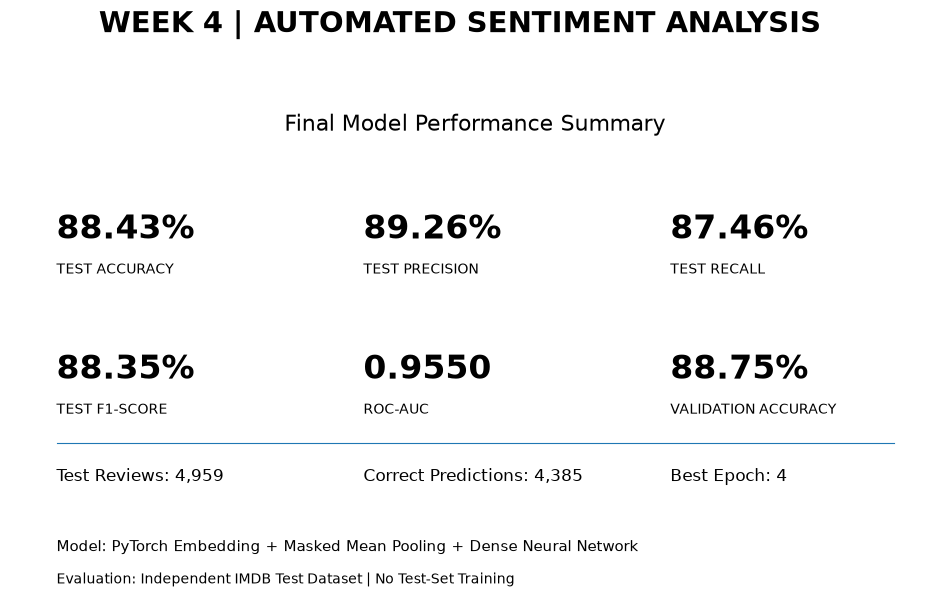

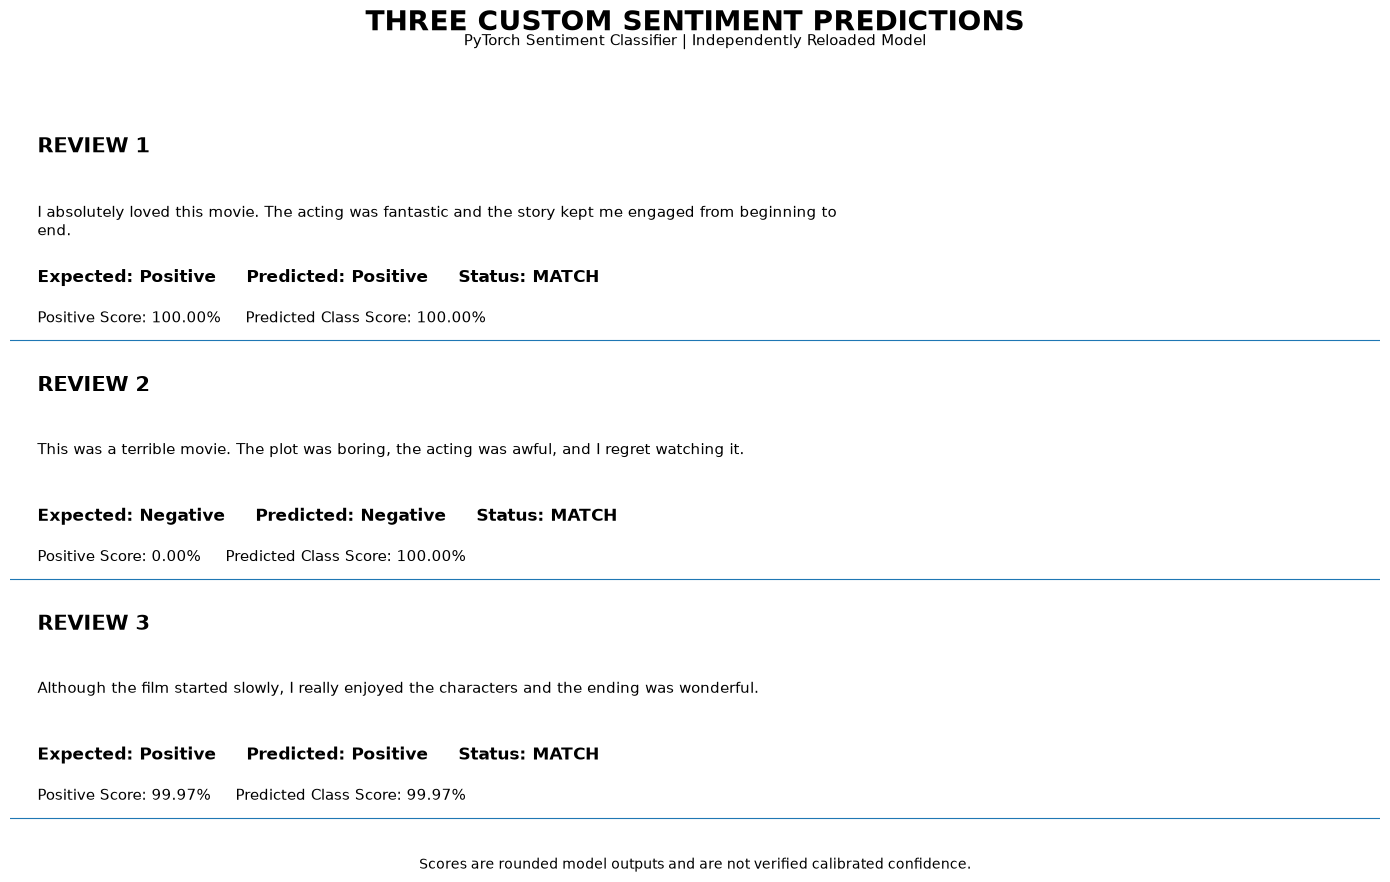

PHASE 7 - CELL 4: FINAL RESULTS & SUBMISSION VISUALIZATIONS

FINAL MODEL PERFORMANCE
Best Epoch: 4
Validation Accuracy: 88.75%
Test Accuracy: 88.43%
Test Precision: 89.26%
Test Recall: 87.46%
Test F1-Score: 88.35%
ROC-AUC: 0.9550

CUSTOM PREDICTIONS
Total Reviews: 3
Expected Sentiment Matches: 3
Review 1: Positive | Positive Score: 100.00%
Review 2: Negative | Positive Score: 0.00%
Review 3: Positive | Positive Score: 99.97%

SAVED OUTPUTS
final_performance_summary.png: PASS
three_custom_predictions.png: PASS
final_results_summary.json: PASS
final_results_summary.txt: PASS

FINAL SUMMARY VERIFICATION: PASS
INDEPENDENT INFERENCE VERIFICATION: PASS
MODEL RETRAINING: NO

ALL SUBMISSION VISUALIZATION CHECKS PASSED!
CELL 4 COMPLETED SUCCESSFULLY!


In [13]:

import json
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


PROJECT_DIR = Path(r"D:\Ai_Ml_intren\week_4")
OUTPUT_DIR = PROJECT_DIR / "outputs"

SUBMISSION_DIR = OUTPUT_DIR / "submission"
SCREENSHOT_DIR = SUBMISSION_DIR / "screenshots"

SCREENSHOT_DIR.mkdir(parents=True, exist_ok=True)

PHASE5_PATH = OUTPUT_DIR / "reports" / "phase5_summary.json"
PHASE6_PATH = OUTPUT_DIR / "reports" / "phase6_summary.json"

INFERENCE_VERIFICATION_PATH = (
    SUBMISSION_DIR
    / "model_bundle"
    / "independent_inference_verification.json"
)

INFERENCE_PREDICTIONS_PATH = (
    SUBMISSION_DIR
    / "model_bundle"
    / "independent_inference_predictions.csv"
)

REFERENCE_PREDICTIONS_PATH = (
    OUTPUT_DIR
    / "testing"
    / "custom_predictions"
    / "custom_predictions.csv"
)

PERFORMANCE_IMAGE_PATH = (
    SCREENSHOT_DIR / "final_performance_summary.png"
)

PREDICTIONS_IMAGE_PATH = (
    SCREENSHOT_DIR / "three_custom_predictions.png"
)

SUMMARY_JSON_PATH = (
    SUBMISSION_DIR / "final_results_summary.json"
)

SUMMARY_TEXT_PATH = (
    SUBMISSION_DIR / "final_results_summary.txt"
)


def load_json(path):
    with open(path, "r", encoding="utf-8") as file:
        return json.load(file)


required_files = [
    PHASE5_PATH,
    PHASE6_PATH,
    INFERENCE_VERIFICATION_PATH,
    INFERENCE_PREDICTIONS_PATH,
    REFERENCE_PREDICTIONS_PATH
]

for file_path in required_files:
    if not file_path.is_file():
        raise FileNotFoundError(
            f"Required file not found: {file_path}"
        )


phase5 = load_json(PHASE5_PATH)
phase6 = load_json(PHASE6_PATH)
inference_verification = load_json(
    INFERENCE_VERIFICATION_PATH
)

predictions_df = pd.read_csv(
    INFERENCE_PREDICTIONS_PATH
)

reference_df = pd.read_csv(
    REFERENCE_PREDICTIONS_PATH
)


if phase5["status"] != "COMPLETED":
    raise ValueError("Phase 5 verification failed.")

if phase6["status"] != "COMPLETED":
    raise ValueError("Phase 6 verification failed.")

if inference_verification["status"] != "COMPLETED":
    raise ValueError("Independent inference verification failed.")

if not inference_verification["sentiment_match"]:
    raise ValueError("Independent sentiment mismatch.")

if not inference_verification["probability_match"]:
    raise ValueError("Independent probability mismatch.")

if len(predictions_df) != 3 or len(reference_df) != 3:
    raise ValueError("Expected exactly three predictions.")

if not np.array_equal(
    predictions_df["review"].to_numpy(),
    reference_df["review"].to_numpy()
):
    raise ValueError("Custom review text mismatch.")

if not np.array_equal(
    predictions_df["predicted_sentiment"].to_numpy(),
    reference_df["predicted_sentiment"].to_numpy()
):
    raise ValueError("Custom prediction mismatch.")

if not np.allclose(
    predictions_df["positive_probability"].to_numpy(),
    reference_df["positive_probability"].to_numpy(),
    rtol=0,
    atol=1e-5
):
    raise ValueError("Custom probability mismatch.")


predictions_df["expected_sentiment"] = (
    reference_df["expected_sentiment"].to_numpy()
)

predictions_df["qualitative_match"] = (
    predictions_df["predicted_sentiment"]
    == predictions_df["expected_sentiment"]
)

custom_match_count = int(
    predictions_df["qualitative_match"].sum()
)

best_epoch = int(phase5["best_epoch"])

validation_accuracy = float(
    phase5["best_validation_accuracy"]
)

test_accuracy = float(phase6["test_accuracy"])
test_precision = float(phase6["test_precision"])
test_recall = float(phase6["test_recall"])
test_f1 = float(phase6["test_f1_score"])
test_loss = float(phase6["test_loss"])
roc_auc = float(phase6["roc_auc"])

total_test_samples = int(
    phase6["total_test_samples"]
)

correct_predictions = int(
    phase6["correct_predictions"]
)

incorrect_predictions = int(
    phase6["incorrect_predictions"]
)

if best_epoch != 4:
    raise ValueError("Unexpected best checkpoint epoch.")

if total_test_samples != 4959:
    raise ValueError("Unexpected test sample count.")

if correct_predictions + incorrect_predictions != total_test_samples:
    raise ValueError("Prediction counts mismatch.")

metrics = np.array([
    validation_accuracy,
    test_accuracy,
    test_precision,
    test_recall,
    test_f1,
    roc_auc
])

if not np.isfinite(metrics).all():
    raise ValueError("Non-finite model metrics.")

if not np.all((metrics >= 0) & (metrics <= 1)):
    raise ValueError("Model metrics outside valid range.")


fig, ax = plt.subplots(figsize=(12, 7))

ax.axis("off")

fig.suptitle(
    "WEEK 4 | AUTOMATED SENTIMENT ANALYSIS",
    fontsize=21,
    fontweight="bold",
    y=0.96
)

ax.text(
    0.5,
    0.88,
    "Final Model Performance Summary",
    fontsize=16,
    ha="center",
    transform=ax.transAxes
)

metric_cards = [
    ("TEST ACCURACY", f"{test_accuracy * 100:.2f}%", 0.05, 0.68),
    ("TEST PRECISION", f"{test_precision * 100:.2f}%", 0.38, 0.68),
    ("TEST RECALL", f"{test_recall * 100:.2f}%", 0.71, 0.68),
    ("TEST F1-SCORE", f"{test_f1 * 100:.2f}%", 0.05, 0.42),
    ("ROC-AUC", f"{roc_auc:.4f}", 0.38, 0.42),
    ("VALIDATION ACCURACY", f"{validation_accuracy * 100:.2f}%", 0.71, 0.42)
]

for label, value, x_pos, y_pos in metric_cards:

    ax.text(
        x_pos,
        y_pos,
        value,
        fontsize=24,
        fontweight="bold",
        transform=ax.transAxes
    )

    ax.text(
        x_pos,
        y_pos - 0.065,
        label,
        fontsize=10,
        transform=ax.transAxes
    )

ax.axhline(
    y=0.30,
    xmin=0.05,
    xmax=0.95,
    linewidth=0.8
)

ax.text(
    0.05,
    0.23,
    f"Test Reviews: {total_test_samples:,}",
    fontsize=12,
    transform=ax.transAxes
)

ax.text(
    0.38,
    0.23,
    f"Correct Predictions: {correct_predictions:,}",
    fontsize=12,
    transform=ax.transAxes
)

ax.text(
    0.71,
    0.23,
    f"Best Epoch: {best_epoch}",
    fontsize=12,
    transform=ax.transAxes
)

ax.text(
    0.05,
    0.10,
    "Model: PyTorch Embedding + Masked Mean Pooling + Dense Neural Network",
    fontsize=11,
    transform=ax.transAxes
)

ax.text(
    0.05,
    0.04,
    "Evaluation: Independent IMDB Test Dataset | No Test-Set Training",
    fontsize=10,
    transform=ax.transAxes
)

plt.savefig(
    PERFORMANCE_IMAGE_PATH,
    dpi=250,
    bbox_inches="tight"
)

plt.show()


fig, axes = plt.subplots(
    3,
    1,
    figsize=(14, 9)
)

fig.suptitle(
    "THREE CUSTOM SENTIMENT PREDICTIONS",
    fontsize=20,
    fontweight="bold",
    y=0.98
)

fig.text(
    0.5,
    0.94,
    "PyTorch Sentiment Classifier | Independently Reloaded Model",
    ha="center",
    fontsize=11
)

for index, ax in enumerate(axes):

    row = predictions_df.iloc[index]

    ax.axis("off")

    review_text = textwrap.fill(
        str(row["review"]),
        width=105
    )

    predicted_sentiment = row["predicted_sentiment"]
    expected_sentiment = row["expected_sentiment"]

    positive_score = float(
        row["positive_probability"]
    ) * 100

    predicted_score = float(
        row["predicted_class_score"]
    ) * 100

    qualitative_status = (
        "MATCH"
        if row["qualitative_match"]
        else "MISMATCH"
    )

    ax.text(
        0.02,
        0.86,
        f"REVIEW {index + 1}",
        fontsize=15,
        fontweight="bold",
        transform=ax.transAxes
    )

    ax.text(
        0.02,
        0.63,
        review_text,
        fontsize=11,
        transform=ax.transAxes,
        va="top"
    )

    ax.text(
        0.02,
        0.28,
        f"Expected: {expected_sentiment}     "
        f"Predicted: {predicted_sentiment}     "
        f"Status: {qualitative_status}",
        fontsize=12,
        fontweight="bold",
        transform=ax.transAxes
    )

    ax.text(
        0.02,
        0.10,
        f"Positive Score: {positive_score:.2f}%     "
        f"Predicted Class Score: {predicted_score:.2f}%",
        fontsize=11,
        transform=ax.transAxes
    )

    ax.axhline(
        y=0.02,
        linewidth=0.8
    )

fig.text(
    0.5,
    0.025,
    "Scores are rounded model outputs and are not verified calibrated confidence.",
    fontsize=10,
    ha="center"
)

plt.tight_layout(
    rect=[0, 0.06, 1, 0.92]
)

plt.savefig(
    PREDICTIONS_IMAGE_PATH,
    dpi=250,
    bbox_inches="tight"
)

plt.show()


summary_data = {
    "project": "Automated Customer Sentiment Analysis",
    "dataset": "IMDB Movie Reviews",
    "framework": "PyTorch",
    "model": "IMDB_Embedding_MLP",
    "completed_phases": 6,
    "current_phase": 7,
    "best_checkpoint_epoch": best_epoch,
    "model_parameters": 3856897,
    "vocabulary_size": 30002,
    "maximum_sequence_length": 298,
    "validation_accuracy": validation_accuracy,
    "test_samples": total_test_samples,
    "test_loss": test_loss,
    "test_accuracy": test_accuracy,
    "test_precision": test_precision,
    "test_recall": test_recall,
    "test_f1_score": test_f1,
    "roc_auc": roc_auc,
    "correct_predictions": correct_predictions,
    "incorrect_predictions": incorrect_predictions,
    "custom_reviews_tested": len(predictions_df),
    "custom_predictions_matched": custom_match_count,
    "independent_inference_verified": True,
    "model_retraining": False,
    "submission_images": [
        str(PERFORMANCE_IMAGE_PATH),
        str(PREDICTIONS_IMAGE_PATH)
    ],
    "status": "COMPLETED"
}

with open(
    SUMMARY_JSON_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        summary_data,
        file,
        indent=4
    )


summary_text = f"""
WEEK 4 - AUTOMATED SENTIMENT ANALYSIS
FINAL PROJECT RESULTS SUMMARY

Dataset: IMDB Movie Reviews
Framework: PyTorch
Model: IMDB_Embedding_MLP

MODEL ARCHITECTURE
Total Parameters: 3,856,897
Vocabulary Size: 30,002
Maximum Sequence Length: 298
Best Training Epoch: {best_epoch}

VALIDATION PERFORMANCE
Validation Accuracy: {validation_accuracy * 100:.2f}%

FINAL TEST PERFORMANCE
Test Samples: {total_test_samples:,}
Test Loss: {test_loss:.4f}
Test Accuracy: {test_accuracy * 100:.2f}%
Test Precision: {test_precision * 100:.2f}%
Test Recall: {test_recall * 100:.2f}%
Test F1-Score: {test_f1 * 100:.2f}%
ROC-AUC: {roc_auc:.4f}

PREDICTION RESULTS
Correct Predictions: {correct_predictions:,}
Incorrect Predictions: {incorrect_predictions:,}
Custom Reviews Tested: {len(predictions_df)}
Expected Sentiment Matches: {custom_match_count}

MODEL VERIFICATION
Best Model Checkpoint: VERIFIED
Exported Model Weights: VERIFIED
Vocabulary and Preprocessing: VERIFIED
Independent CPU Inference: VERIFIED
Training Checkpoint Required for Inference: NO

LIMITATIONS
The model was trained and tested using IMDB movie reviews.
Performance on other customer review domains is not established.
Prediction probabilities have not been calibrated.
""".strip()

with open(
    SUMMARY_TEXT_PATH,
    "w",
    encoding="utf-8"
) as file:
    file.write(summary_text + "\n")


required_outputs = [
    PERFORMANCE_IMAGE_PATH,
    PREDICTIONS_IMAGE_PATH,
    SUMMARY_JSON_PATH,
    SUMMARY_TEXT_PATH
]

for file_path in required_outputs:

    if not file_path.is_file():
        raise FileNotFoundError(
            f"Required output missing: {file_path}"
        )

    if file_path.stat().st_size == 0:
        raise ValueError(
            f"Empty output file: {file_path}"
        )

saved_summary = load_json(SUMMARY_JSON_PATH)

assert saved_summary["status"] == "COMPLETED"
assert saved_summary["test_samples"] == 4959
assert saved_summary["correct_predictions"] == 4385
assert saved_summary["incorrect_predictions"] == 574
assert saved_summary["custom_predictions_matched"] == 3
assert saved_summary["independent_inference_verified"] is True

print("=" * 65)
print("PHASE 7 - CELL 4: FINAL RESULTS & SUBMISSION VISUALIZATIONS")
print("=" * 65)

print("\nFINAL MODEL PERFORMANCE")
print("Best Epoch:", best_epoch)
print(f"Validation Accuracy: {validation_accuracy * 100:.2f}%")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Precision: {test_precision * 100:.2f}%")
print(f"Test Recall: {test_recall * 100:.2f}%")
print(f"Test F1-Score: {test_f1 * 100:.2f}%")
print(f"ROC-AUC: {roc_auc:.4f}")

print("\nCUSTOM PREDICTIONS")
print("Total Reviews:", len(predictions_df))
print("Expected Sentiment Matches:", custom_match_count)

for _, row in predictions_df.iterrows():
    print(
        f"Review {int(row['review_id'])}: "
        f"{row['predicted_sentiment']} | "
        f"Positive Score: "
        f"{row['positive_probability'] * 100:.2f}%"
    )

print("\nSAVED OUTPUTS")

for file_path in required_outputs:
    print(
        f"{file_path.name}: PASS"
    )

print("\nFINAL SUMMARY VERIFICATION: PASS")
print("INDEPENDENT INFERENCE VERIFICATION: PASS")
print("MODEL RETRAINING: NO")

print("\nALL SUBMISSION VISUALIZATION CHECKS PASSED!")
print("CELL 4 COMPLETED SUCCESSFULLY!")


In [14]:

import hashlib
import json
import struct
import subprocess
from pathlib import Path

import numpy as np

PROJECT_DIR = Path(r"D:\Ai_Ml_intren\week_4")
OUTPUT_DIR = PROJECT_DIR / "outputs"
SUBMISSION_DIR = OUTPUT_DIR / "submission"
SCREENSHOT_DIR = SUBMISSION_DIR / "screenshots"

NOTEBOOK_PATH = PROJECT_DIR / "notebook.ipynb"
SUMMARY_PATH = SUBMISSION_DIR / "final_results_summary.json"
PHASE6_PATH = OUTPUT_DIR / "reports" / "phase6_summary.json"

NOTEBOOK_REPORT_PATH = (
    SUBMISSION_DIR / "notebook_validation_report.json"
)

GIT_REPORT_PATH = (
    SUBMISSION_DIR / "git_submission_status.json"
)

required_files = [
    NOTEBOOK_PATH,
    SUMMARY_PATH,
    PHASE6_PATH,
    SUBMISSION_DIR / "model_bundle" / "sentiment_model_weights.pt",
    SUBMISSION_DIR / "model_bundle" / "vocabulary.json",
    SUBMISSION_DIR / "model_bundle" / "inference_config.json",
    SUBMISSION_DIR / "model_bundle" / "export_verification.json",
    SUBMISSION_DIR / "model_bundle" / "independent_inference_verification.json",
    SCREENSHOT_DIR / "final_performance_summary.png",
    SCREENSHOT_DIR / "three_custom_predictions.png"
]

for file_path in required_files:
    if not file_path.is_file():
        raise FileNotFoundError(
            f"Required file missing: {file_path}"
        )

    if file_path.stat().st_size == 0:
        raise ValueError(
            f"Empty file detected: {file_path}"
        )


def load_json(path):
    with open(path, "r", encoding="utf-8") as file:
        return json.load(file)


def calculate_sha256(path):
    sha256 = hashlib.sha256()

    with open(path, "rb") as file:
        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):
            sha256.update(chunk)

    return sha256.hexdigest()


notebook = load_json(NOTEBOOK_PATH)

if notebook.get("nbformat") != 4:
    raise ValueError(
        "Notebook is not in Jupyter Notebook format version 4."
    )

cells = notebook.get("cells")

if not isinstance(cells, list) or not cells:
    raise ValueError("Notebook cells are missing.")

code_cells = []
markdown_cells = []
error_outputs = []
invalid_cells = []
cell_sources = []

for index, cell in enumerate(cells):

    cell_type = cell.get("cell_type")
    source = cell.get("source", "")

    if isinstance(source, list):
        source = "".join(source)

    if not isinstance(source, str):
        invalid_cells.append(index + 1)
        continue

    cell_sources.append(source)

    if cell_type == "code":

        code_cells.append(index + 1)

        outputs = cell.get("outputs", [])

        if not isinstance(outputs, list):
            invalid_cells.append(index + 1)
            continue

        for output in outputs:

            if output.get("output_type") == "error":
                error_outputs.append({
                    "cell_number": index + 1,
                    "error_type": output.get("ename"),
                    "error_message": output.get("evalue")
                })

    elif cell_type == "markdown":
        markdown_cells.append(index + 1)

    elif cell_type != "raw":
        invalid_cells.append(index + 1)


all_source_text = "\n".join(cell_sources)

required_milestones = {
    "Phase 5 Training": "PHASE 5 - CELL 3",
    "Phase 6 Test Evaluation": "PHASE 6 - CELL 2",
    "Phase 6 Custom Predictions": "PHASE 6 - CELL 5",
    "Phase 6 Final Verification": "PHASE 6 FINAL VERIFICATION",
    "Phase 7 Cell 1": "PHASE 7 - CELL 1",
    "Phase 7 Cell 2": "PHASE 7 - CELL 2",
    "Phase 7 Cell 3": "PHASE 7 - CELL 3",
    "Phase 7 Cell 4": "PHASE 7 - CELL 4"
}

milestone_status = {
    name: marker in all_source_text
    for name, marker in required_milestones.items()
}

missing_milestones = [
    name
    for name, found in milestone_status.items()
    if not found
]


image_information = {}

for image_path in [
    SCREENSHOT_DIR / "final_performance_summary.png",
    SCREENSHOT_DIR / "three_custom_predictions.png"
]:

    with open(image_path, "rb") as file:
        header = file.read(24)

    if header[:8] != b"\x89PNG\r\n\x1a\n":
        raise ValueError(
            f"Invalid PNG signature: {image_path.name}"
        )

    if header[12:16] != b"IHDR":
        raise ValueError(
            f"Invalid PNG header: {image_path.name}"
        )

    width, height = struct.unpack(
        ">II",
        header[16:24]
    )

    if width < 600 or height < 400:
        raise ValueError(
            f"Image resolution too small: {image_path.name}"
        )

    image_information[image_path.name] = {
        "width": width,
        "height": height,
        "size_mb": round(
            image_path.stat().st_size / (1024 ** 2),
            3
        ),
        "verified": True
    }


summary = load_json(SUMMARY_PATH)
phase6 = load_json(PHASE6_PATH)

metric_names = [
    "test_accuracy",
    "test_precision",
    "test_recall",
    "test_f1_score",
    "roc_auc"
]

for metric_name in metric_names:

    if not np.isclose(
        summary[metric_name],
        phase6[metric_name],
        rtol=0,
        atol=1e-10
    ):
        raise ValueError(
            f"Final summary metric mismatch: {metric_name}"
        )

if summary["custom_predictions_matched"] != 3:
    raise ValueError("Custom prediction summary mismatch.")

if summary["independent_inference_verified"] is not True:
    raise ValueError("Independent inference verification missing.")


def run_git_command(*arguments):

    try:
        result = subprocess.run(
            [
                "git",
                "-C",
                str(PROJECT_DIR.parent),
                *arguments
            ],
            capture_output=True,
            text=True,
            timeout=15,
            check=False
        )

        if result.returncode == 0:
            return result.stdout.strip()

        return None

    except (
        FileNotFoundError,
        subprocess.TimeoutExpired,
        OSError
    ):
        return None


git_repository_root = run_git_command(
    "rev-parse",
    "--show-toplevel"
)

git_available = git_repository_root is not None

git_branch = None
git_commit = None
git_origin_configured = False
git_local_changes = []
git_ahead_count = None
git_behind_count = None

if git_available:

    git_branch = run_git_command(
        "branch",
        "--show-current"
    )

    git_commit = run_git_command(
        "rev-parse",
        "--short",
        "HEAD"
    )

    git_origin_configured = (
        run_git_command(
            "remote",
            "get-url",
            "origin"
        ) is not None
    )

    status_output = run_git_command(
        "status",
        "--short",
        "--",
        "week_4"
    )

    if status_output is not None:
        git_local_changes = (
            status_output.splitlines()
            if status_output
            else []
        )

    git_ahead_count = run_git_command(
        "rev-list",
        "--count",
        "origin/main..HEAD"
    )

    git_behind_count = run_git_command(
        "rev-list",
        "--count",
        "HEAD..origin/main"
    )


large_files = []

for file_path in OUTPUT_DIR.rglob("*"):

    if not file_path.is_file():
        continue

    file_size = file_path.stat().st_size

    if file_size >= 100 * 1024 * 1024:
        large_files.append({
            "file": str(
                file_path.relative_to(PROJECT_DIR)
            ),
            "size_mb": round(
                file_size / (1024 ** 2),
                2
            )
        })


notebook_issues = []

if invalid_cells:
    notebook_issues.append(
        f"Invalid notebook cells: {invalid_cells}"
    )

if error_outputs:
    notebook_issues.append(
        f"Saved error outputs: {len(error_outputs)}"
    )

if missing_milestones:
    notebook_issues.append(
        "Missing saved phase cells: "
        + ", ".join(missing_milestones)
    )

notebook_status = (
    "VERIFIED"
    if not notebook_issues
    else "NEEDS_ATTENTION"
)

notebook_report = {
    "project": "IMDB Customer Sentiment Analysis",
    "phase": 7,
    "cell": 5,
    "notebook_name": NOTEBOOK_PATH.name,
    "notebook_format": notebook["nbformat"],
    "total_cells": len(cells),
    "code_cells": len(code_cells),
    "markdown_cells": len(markdown_cells),
    "invalid_cells": invalid_cells,
    "saved_error_outputs": error_outputs,
    "phase_milestones": milestone_status,
    "missing_milestones": missing_milestones,
    "notebook_sha256": calculate_sha256(NOTEBOOK_PATH),
    "image_verification": image_information,
    "final_metrics_verified": True,
    "submission_files_verified": len(required_files),
    "issues": notebook_issues,
    "status": notebook_status
}

git_report = {
    "git_available": git_available,
    "repository_root": git_repository_root,
    "current_branch": git_branch,
    "local_commit": git_commit,
    "origin_remote_configured": git_origin_configured,
    "local_changes_count": len(git_local_changes),
    "local_changes_preview": git_local_changes[:15],
    "commits_ahead_of_local_origin_main": git_ahead_count,
    "commits_behind_local_origin_main": git_behind_count,
    "files_at_or_above_100_mb": large_files,
    "live_github_sync_verified": False,
    "status": "LOCAL_CHECK_ONLY"
}

with open(
    NOTEBOOK_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        notebook_report,
        file,
        indent=4,
        ensure_ascii=False
    )

with open(
    GIT_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        git_report,
        file,
        indent=4,
        ensure_ascii=False
    )


print("=" * 65)
print("PHASE 7 - CELL 5: NOTEBOOK & GITHUB SUBMISSION CHECK")
print("=" * 65)

print("\nJUPYTER NOTEBOOK VALIDATION")
print("Notebook Exists:", NOTEBOOK_PATH.is_file())
print("Notebook Format:", notebook["nbformat"])
print("Total Cells:", len(cells))
print("Code Cells:", len(code_cells))
print("Markdown Cells:", len(markdown_cells))
print("Invalid Cells:", len(invalid_cells))
print("Saved Error Outputs:", len(error_outputs))

print("\nPHASE MILESTONE VERIFICATION")

for name, found in milestone_status.items():
    print(
        f"{name}: {'PASS' if found else 'MISSING'}"
    )

print("\nSUBMISSION FILE VERIFICATION")
print("Required Files:", len(required_files))
print("All Files Exist: PASS")
print("Final Metrics Match: PASS")

print("\nSUBMISSION IMAGE VERIFICATION")

for filename, information in image_information.items():
    print(
        f"{filename}: "
        f"{information['width']}x{information['height']} | PASS"
    )

print("\nLOCAL GIT STATUS")
print("Git Repository Found:", git_available)
print("Current Branch:", git_branch)
print("Local Commit:", git_commit)
print("Origin Remote Configured:", git_origin_configured)
print("Local Changes:", len(git_local_changes))
print("Commits Ahead of Local Origin/Main:", git_ahead_count)
print("Commits Behind Local Origin/Main:", git_behind_count)

if git_local_changes:
    print("\nLOCAL CHANGES PREVIEW")

    for change in git_local_changes[:15]:
        print(change)

if large_files:
    print("\nGITHUB FILE SIZE WARNING")

    for item in large_files:
        print(
            f"{item['file']}: {item['size_mb']} MB"
        )

print("\nLIVE GITHUB SYNC")
print("Remote Publication Verified: NO")
print("Local Git Inspection: COMPLETED" if git_available
      else "Local Git Inspection: UNAVAILABLE")

print("\nSAVED REPORTS")
print("Notebook Report:", NOTEBOOK_REPORT_PATH)
print("Git Report:", GIT_REPORT_PATH)

print("\nNOTEBOOK VALIDATION STATUS:", notebook_status)

if notebook_issues:

    print("\nISSUES REQUIRING ATTENTION")

    for issue in notebook_issues:
        print("-", issue)

    print("\nCELL 5 REQUIRES ATTENTION")

else:

    print("\nALL NOTEBOOK & SUBMISSION FILE CHECKS PASSED!")
    print("CELL 5 COMPLETED SUCCESSFULLY!")


PHASE 7 - CELL 5: NOTEBOOK & GITHUB SUBMISSION CHECK

JUPYTER NOTEBOOK VALIDATION
Notebook Exists: True
Notebook Format: 4
Total Cells: 37
Code Cells: 37
Markdown Cells: 0
Invalid Cells: 0
Saved Error Outputs: 0

PHASE MILESTONE VERIFICATION
Phase 5 Training: PASS
Phase 6 Test Evaluation: MISSING
Phase 6 Custom Predictions: MISSING
Phase 6 Final Verification: MISSING
Phase 7 Cell 1: MISSING
Phase 7 Cell 2: MISSING
Phase 7 Cell 3: MISSING
Phase 7 Cell 4: MISSING

SUBMISSION FILE VERIFICATION
Required Files: 10
All Files Exist: PASS
Final Metrics Match: PASS

SUBMISSION IMAGE VERIFICATION
final_performance_summary.png: 2375x1537 | PASS
three_custom_predictions.png: 3475x2207 | PASS

LOCAL GIT STATUS
Git Repository Found: True
Current Branch: main
Local Commit: 65515d6c
Origin Remote Configured: True
Local Changes: 4
Commits Ahead of Local Origin/Main: 0
Commits Behind Local Origin/Main: 0

LOCAL CHANGES PREVIEW
?? week_4/notebook_recovered.ipynb
?? week_4/outputs/reports/phase6_summary.j

In [15]:

import json
from pathlib import Path

PROJECT_DIR = Path(r"D:\Ai_Ml_intren\week_4")

notebook_files = sorted(
    PROJECT_DIR.glob("*.ipynb")
)

required_markers = {
    "Phase 5 Training": "PHASE 5 - CELL 3",
    "Phase 6 Test Evaluation": "PHASE 6 - CELL 2",
    "Phase 6 Custom Predictions": "PHASE 6 - CELL 5",
    "Phase 6 Final Verification": "PHASE 6 FINAL VERIFICATION",
    "Phase 7 Cell 1": "PHASE 7 - CELL 1",
    "Phase 7 Cell 2": "PHASE 7 - CELL 2",
    "Phase 7 Cell 3": "PHASE 7 - CELL 3",
    "Phase 7 Cell 4": "PHASE 7 - CELL 4"
}

notebook_results = []

print("=" * 65)
print("PHASE 7 - CELL 5A: NOTEBOOK RECOVERY VERIFICATION")
print("=" * 65)

for notebook_path in notebook_files:

    with open(
        notebook_path,
        "r",
        encoding="utf-8"
    ) as file:
        notebook = json.load(file)

    cells = notebook.get("cells", [])

    code_cells = [
        cell for cell in cells
        if cell.get("cell_type") == "code"
    ]

    markdown_cells = [
        cell for cell in cells
        if cell.get("cell_type") == "markdown"
    ]

    source_text = "\n".join(
        "".join(cell.get("source", []))
        if isinstance(cell.get("source", []), list)
        else str(cell.get("source", ""))
        for cell in cells
    )

    marker_status = {
        name: marker in source_text
        for name, marker in required_markers.items()
    }

    found_count = sum(marker_status.values())

    error_count = sum(
        1
        for cell in code_cells
        for output in cell.get("outputs", [])
        if output.get("output_type") == "error"
    )

    notebook_results.append({
        "filename": notebook_path.name,
        "total_cells": len(cells),
        "code_cells": len(code_cells),
        "markdown_cells": len(markdown_cells),
        "saved_errors": error_count,
        "milestones_found": found_count,
        "milestones_required": len(required_markers),
        "all_milestones_found": all(marker_status.values())
    })

    print("\n" + "-" * 65)
    print("NOTEBOOK:", notebook_path.name)
    print("-" * 65)

    print("Total Cells:", len(cells))
    print("Code Cells:", len(code_cells))
    print("Markdown Cells:", len(markdown_cells))
    print("Saved Errors:", error_count)

    print("\nPHASE VERIFICATION")

    for name, found in marker_status.items():
        print(
            f"{name}: {'FOUND' if found else 'MISSING'}"
        )

    print(
        "\nMilestones Found:",
        f"{found_count}/{len(required_markers)}"
    )

print("\n" + "=" * 65)
print("NOTEBOOK COMPARISON SUMMARY")
print("=" * 65)

for result in notebook_results:
    print(
        f"{result['filename']}: "
        f"{result['total_cells']} cells | "
        f"{result['milestones_found']}/"
        f"{result['milestones_required']} milestones"
    )

complete_notebooks = [
    result
    for result in notebook_results
    if result["all_milestones_found"]
]

print("\nCOMPLETE NOTEBOOK CANDIDATES")

if complete_notebooks:
    for result in complete_notebooks:
        print(result["filename"])
else:
    print("No notebook contains all required milestones.")

print("\nRECOVERY INSPECTION COMPLETED!")


PHASE 7 - CELL 5A: NOTEBOOK RECOVERY VERIFICATION

-----------------------------------------------------------------
NOTEBOOK: notebook.ipynb
-----------------------------------------------------------------
Total Cells: 37
Code Cells: 37
Markdown Cells: 0
Saved Errors: 0

PHASE VERIFICATION
Phase 5 Training: FOUND
Phase 6 Test Evaluation: MISSING
Phase 6 Custom Predictions: MISSING
Phase 6 Final Verification: MISSING
Phase 7 Cell 1: MISSING
Phase 7 Cell 2: MISSING
Phase 7 Cell 3: MISSING
Phase 7 Cell 4: MISSING

Milestones Found: 1/8

-----------------------------------------------------------------
NOTEBOOK: notebook_recovered.ipynb
-----------------------------------------------------------------
Total Cells: 37
Code Cells: 37
Markdown Cells: 0
Saved Errors: 0

PHASE VERIFICATION
Phase 5 Training: FOUND
Phase 6 Test Evaluation: MISSING
Phase 6 Custom Predictions: MISSING
Phase 6 Final Verification: MISSING
Phase 7 Cell 1: MISSING
Phase 7 Cell 2: MISSING
Phase 7 Cell 3: MISSING
Phase